# Codigo base

In [1]:
source("utils.r")
source("erpt_lp.R")

# Cargar datos

In [2]:
# Example of how to call the function
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Data%20trimestral%201950%20a%202023%20PRUEBA.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))

# Read the `data` from the Excel file
df_trimestral_crudo <- read_excel(temp_file)

Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Data%20trimestral%201950%20a%202023%20PRUEBA.xlsx]
  Date: 2026-11-01 22:25
  Status: 200
  Content-Type: application/octet-stream
  Size: 56 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//Rtmph0uWqX/file458e6180774.xlsxNULL

In [3]:
# Select specific columns and rows from df_trimestral_crudo
df_Arg <- df_trimestral_crudo |> 
  dplyr::select(año, trimestre, ipc_ajust, E, Ebc, pbird, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA, TOTfmi) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)

# Rename "ipc_ajust" to "ipc"
df_Arg <- renameColumnOfDataframe(df_Arg, "ipc_ajust", "ipc")

# Display first 6 rows
print(head(df_Arg))

# Display first 65 rows
print(head(df_Arg, 65))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA


    año trimestre          ipc            E          Ebc  pbird impp_usa
1  1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2  1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3  1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4  1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5  1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6  1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
7  1951      3ºTr 5.068546e-12 1.420937e-12 1.420937e-12 147595 15.28579
8  1951      4ºTr 5.473033e-12 1.440207e-12 1.440207e-12 146949 14.66607
9  1952      1ºTr 6.101530e-12 1.417080e-12 1.417080e-12 147305 14.70636
10 1952      2ºTr 6.739640e-12 1.400573e-12 1.400573e-12 142608 14.30367
11 1952      3ºTr 6.641693e-12 1.397523e-12 1.397523e-12 135474 13.91547
12 1952      4ºTr 6.868363e-12 1.397507e-12 1.397507e-12 136685 13.67280
13 1953      1ºTr 7.054161e-12 1.397500e-12 1.39750

In [23]:
# Copy df_Arg to df_ERPT_Arg1
df_ERPT_Arg1 <- df_Arg

# Display first rows
print(head(df_ERPT_Arg1))

# Apply logarithm to specific columns
df_ERPT_Arg1 <- makeLogColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg1) # nolint: line_length_linter.

# Display transformed dataframe
print(head(df_ERPT_Arg1))
print(tail(df_ERPT_Arg1))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA
   año trimestre       ipc         E       Ebc    pbird impp_usa Psoja_USA
1 1950      1ºTr -26.48263 -27.73416 -27.73416 11.86097 2.394203 0.7701082
2 1950      2ºTr -26.41158 -27.73416 -27.73416 11.84453 2.419022 0

In [24]:
# Create df_ERPT_Arg as a copy of df_Arg
df_ERPT_Arg <- df_Arg

# Display first rows
print(head(df_ERPT_Arg))

# Apply logarithm transformation
df_ERPT_Arg <- makeLogColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg)

# Display transformed dataframe
print(head(df_ERPT_Arg))

# Apply differencing transformation
df_ERPT_Arg <- makeDiffColumns(c("ipc", "E", "Ebc", "pbird", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA", "TOTfmi"), df_ERPT_Arg)

# Display first and last rows
print(head(df_ERPT_Arg))
print(tail(df_ERPT_Arg, 90))

   año trimestre          ipc            E          Ebc  pbird impp_usa
1 1950      1ºTr 3.153126e-12 9.020000e-13 9.020000e-13 141630 10.95946
2 1950      2ºTr 3.385298e-12 9.020000e-13 9.020000e-13 139320 11.23487
3 1950      3ºTr 3.553683e-12 1.082330e-12 1.082330e-12 144669 12.19485
4 1950      4ºTr 3.806171e-12 1.403200e-12 1.403200e-12 142804 13.26367
5 1951      1ºTr 3.893961e-12 1.405173e-12 1.405173e-12 146731 14.45577
6 1951      2ºTr 4.559823e-12 1.412013e-12 1.412013e-12 148515 15.34128
  Psoja_USA Pmaíz_USA Ptrigo_USA TOTfmi
1  2.160000  1.166667   1.943333     NA
2  2.663333  1.320000   2.060000     NA
3  2.536667  1.440000   1.966667     NA
4  2.423333  1.396667   1.953333     NA
5  3.026667  1.580000   2.140000     NA
6  3.076667  1.626667   2.110000     NA


   año trimestre       ipc         E       Ebc    pbird impp_usa Psoja_USA
1 1950      1ºTr -26.48263 -27.73416 -27.73416 11.86097 2.394203 0.7701082
2 1950      2ºTr -26.41158 -27.73416 -27.73416 11.84453 2.419022 0.9795785
3 1950      3ºTr -26.36304 -27.55190 -27.55190 11.88220 2.501014 0.9308509
4 1950      4ºTr -26.29440 -27.29227 -27.29227 11.86923 2.585029 0.8851440
5 1951      1ºTr -26.27159 -27.29086 -27.29086 11.89636 2.671094 1.1074619
6 1951      2ºTr -26.11374 -27.28600 -27.28600 11.90844 2.730547 1.1238468
  Pmaíz_USA Ptrigo_USA TOTfmi
1 0.1541507  0.6644047     NA
2 0.2776317  0.7227060     NA
3 0.3646431  0.6763401     NA
4 0.3340884  0.6695373     NA
5 0.4574248  0.7608058     NA
6 0.4865329  0.7466879     NA
   año trimestre        ipc           E         Ebc        pbird     impp_usa
2 1950      2ºTr 0.07104761 0.000000000 0.000000000 -0.016444578  0.024819416
3 1950      3ºTr 0.04854264 0.182256884 0.182256884  0.037674929  0.081991561
4 1950      4ºTr 0.06863892 0.2

# Regresiones

### impp_usa 1950 a 2023 - Todas endógenas - Selected orders: 2 y 3 

### Todas endógenas - 2 lags

Selected orders (en notebook: "selected_orders.ipynb): 

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4446318,-1.44463181,-1.4446318,-1.4446318,-1.4446318,-1.444632
2,1,-1.3924070,-1.74803641,-1.0367775,4.8852978,-4.3516439,14.122239
3,2,-1.2148192,-1.27369682,-1.1559416,4.9690771,-4.6021443,14.540298
4,3,-0.7344247,-0.72359648,-0.7452529,-0.9824487,-4.1012658,2.136368
5,4,-0.2044832,-1.06722984,0.6582634,3.9351677,-3.1367632,11.007099
6,5,0.4974344,-0.18537519,1.1802441,2.9273425,-1.3826532,7.237338
7,6,0.9208520,0.02556448,1.8161395,-1.5606825,-5.7421449,2.620780
8,7,1.1359463,0.10390060,2.1679920,2.4953966,-1.9024174,6.893211
9,8,0.5621742,0.48796262,0.6363859,4.2798692,0.2974123,8.262326


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.7268158,-0.726815837,-0.7268158,-0.7268158,-0.7268158,-0.7268158
11,1,-0.6639497,-0.752547996,-0.5753515,3.2707397,-1.2248246,7.7663040
12,2,-0.8218448,-0.810154442,-0.8335352,4.7427695,-3.9936340,13.4791730
13,3,-0.6586999,-0.696524474,-0.6208753,0.9125323,-1.7791332,3.6041977
14,4,-0.4427892,-0.495895629,-0.3896827,4.2844764,-1.4620800,10.0310329
15,5,-0.2794160,-0.271496901,-0.2873352,4.1049509,-0.9125096,9.1224114
16,6,0.3001420,-0.259193660,0.8594777,1.0159501,-2.5718893,4.6037895
17,7,0.4713383,-0.170536170,1.1132128,2.0128843,-1.7250079,5.7507764
18,8,0.5881943,0.001727268,1.1746614,3.7584462,-0.1531634,7.6700557


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
92,1,-0.7549079,-1.5451420,0.0353262,-2.4037543,-5.658265,0.850756
93,2,-0.6969155,-1.5976694,0.2038384,0.6060489,-2.506181,3.718279
94,3,-0.3988163,-1.1415517,0.3439191,-0.4636926,-4.254171,3.326786
95,4,-0.4599578,-1.2090157,0.2891000,-0.9118204,-5.725632,3.901991
96,5,0.1320764,-0.6334077,0.8975605,1.6715821,-1.829355,5.172519
97,6,-0.6259983,-1.4805126,0.2285160,-0.6352829,-3.934433,2.663867
98,7,-0.5882365,-1.4820107,0.3055378,-0.6880683,-3.815906,2.439769
99,8,-0.1648701,-1.0921288,0.7623885,2.4445441,-0.774450,5.663538


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000,0.0000000,0.00000000,0.0000000,0.000000
101,1,0.06937094,-0.1231061,0.2618479,-1.47614402,-4.1645266,1.212239
102,2,-0.10961689,-0.3876594,0.1684256,0.83369014,-1.4245557,3.091936
103,3,-0.05964120,-0.3698187,0.2505363,-0.09795053,-3.2490837,3.053183
104,4,-0.17638338,-0.5655140,0.2127472,-0.24123303,-3.5602957,3.077830
105,5,-0.09132646,-0.4985806,0.3159277,0.36801243,-2.2219303,2.957955
106,6,-0.28978183,-0.8339067,0.2543431,0.76732881,-2.5965975,4.131255
107,7,-0.27631137,-0.8100119,0.2573892,-1.26843816,-5.3567067,2.819830
108,8,-0.08839194,-0.6615610,0.4847771,2.77860829,-0.2435544,5.800771


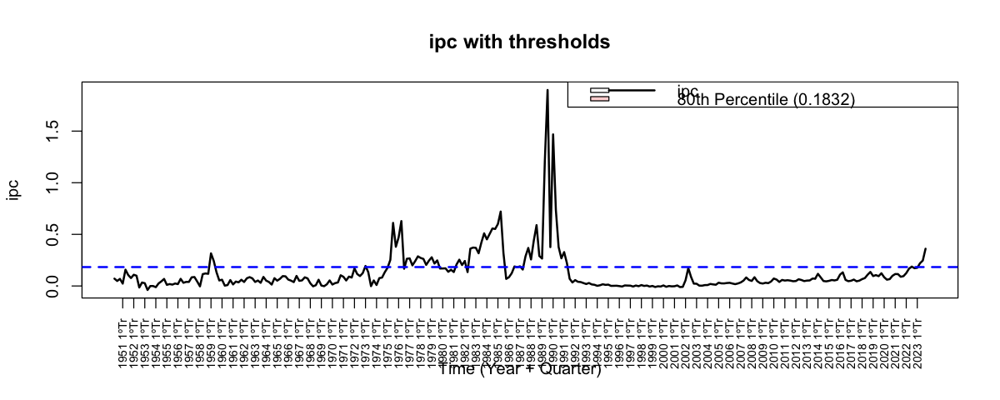

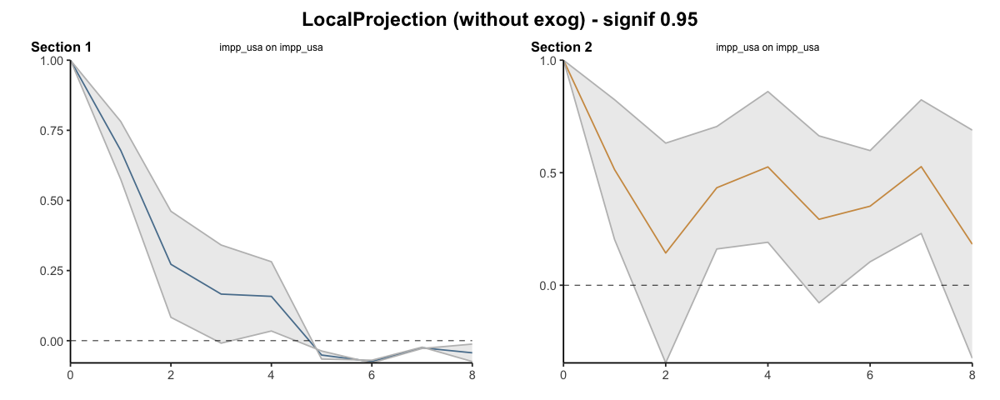

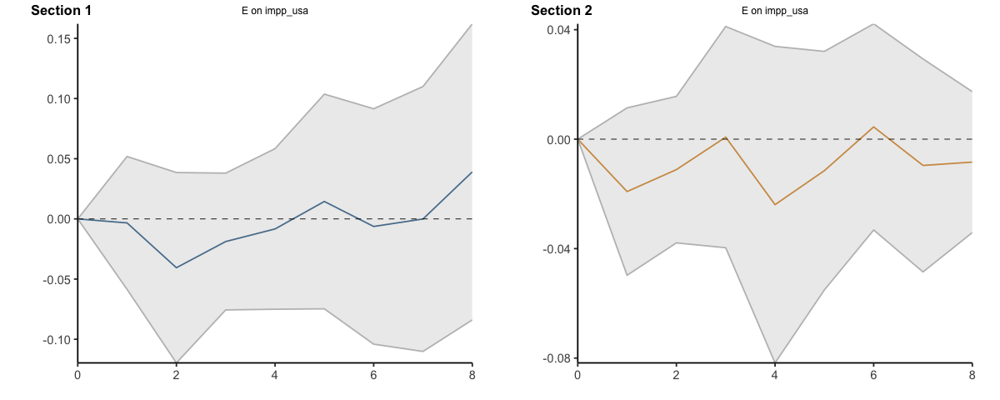

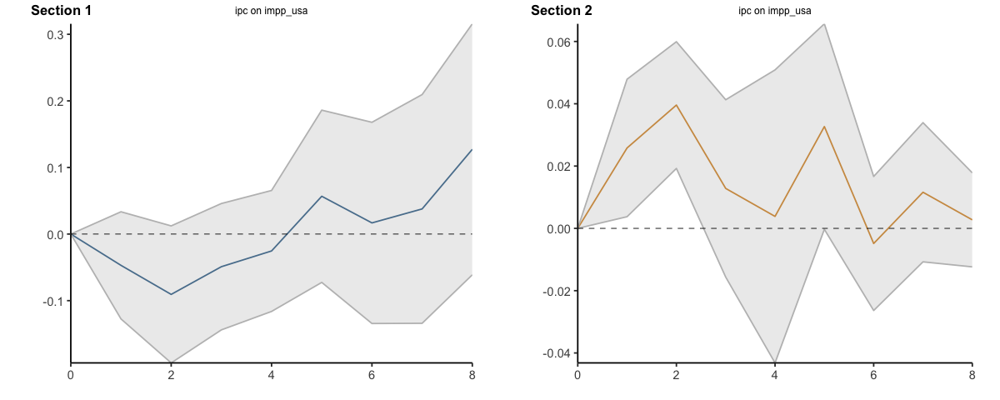

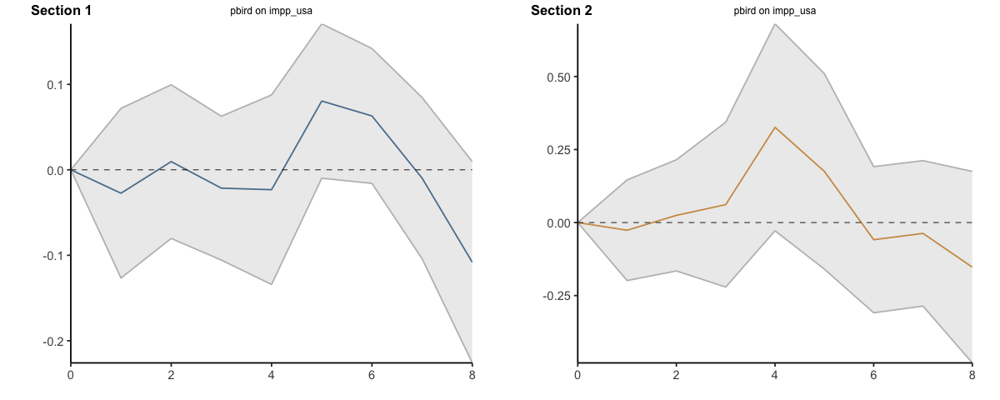

...

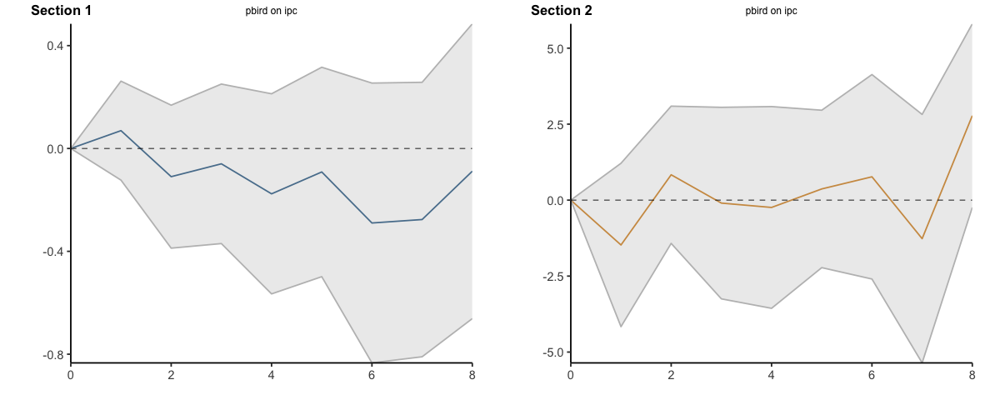

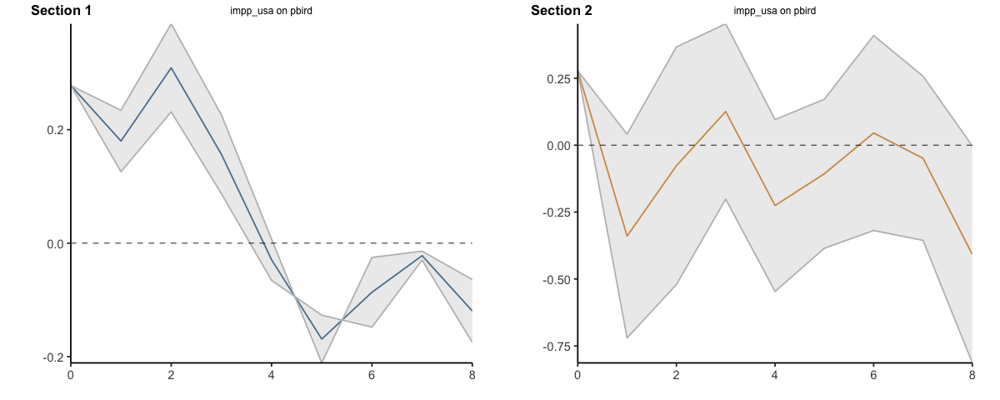

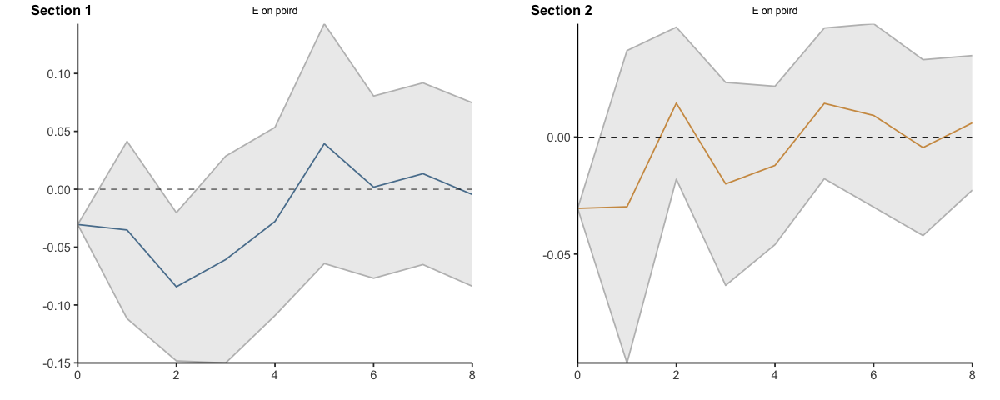

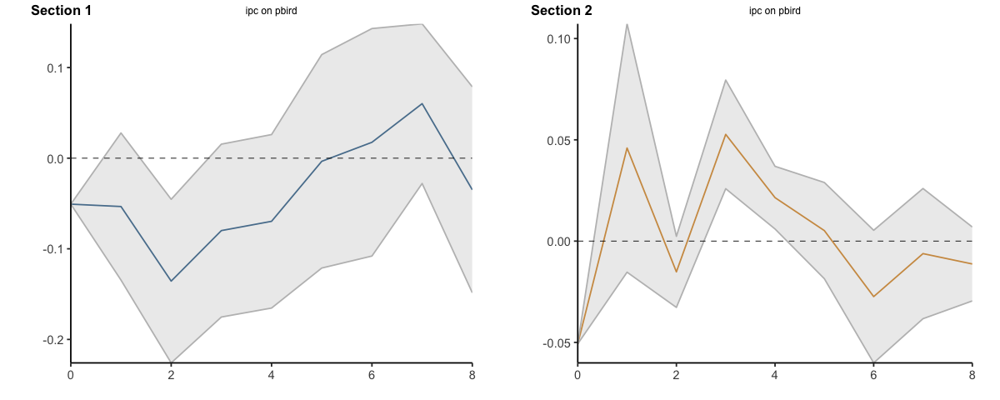

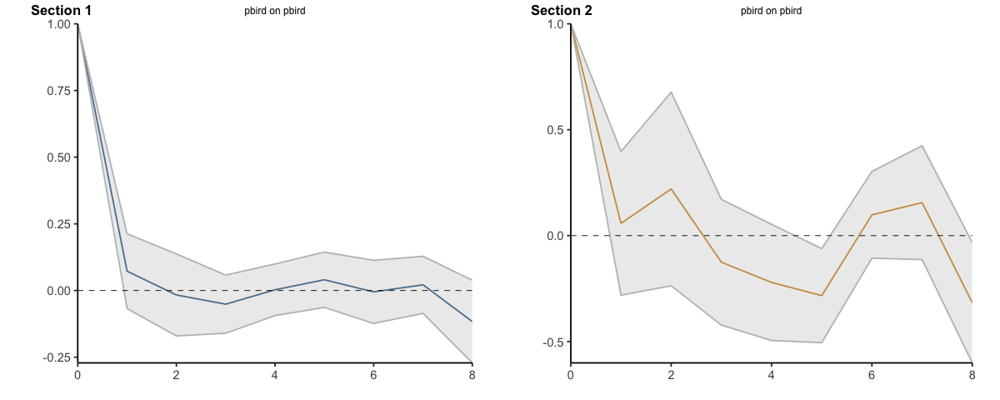

In [14]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.8)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.444632,-1.444632,-1.4446318,-1.444632,-1.444632,-1.444632
2,1,-2.837039,-3.192668,-2.4814094,3.440666,-5.796276,12.677608
3,2,-4.051858,-4.466365,-3.6373510,8.409743,-10.398420,27.217906
4,3,-4.786283,-5.189962,-4.3826038,7.427294,-14.499686,29.354274
5,4,-4.990766,-6.257191,-3.7243405,11.362462,-17.636449,40.361373
6,5,-4.493331,-6.442567,-2.5440964,14.289805,-19.019102,47.598711
7,6,-3.572479,-6.417002,-0.7279569,12.729122,-24.761247,50.219491
8,7,-2.436533,-6.313101,1.4400351,15.224519,-26.663665,57.112702
9,8,-1.874359,-5.825139,2.0764210,19.504388,-26.366252,65.375028


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158,-0.7268158
11,1,-1.3907656,-1.4793638,-1.3021673,2.5439239,-1.9516404,7.0394882
12,2,-2.2126104,-2.2895183,-2.1357025,7.2866934,-5.9452745,20.5186612
13,3,-2.8713103,-2.9860427,-2.7565778,8.1992257,-7.7244077,24.1228590
14,4,-3.3140995,-3.4819384,-3.1462605,12.4837021,-9.1864877,34.1538919
15,5,-3.5935155,-3.7534353,-3.4335957,16.5886530,-10.0989973,43.2763033
16,6,-3.2933735,-4.0126289,-2.5741180,17.6046032,-12.6708865,47.8800929
17,7,-2.8220352,-4.1831651,-1.4609052,19.6174874,-14.3958944,53.6308693
18,8,-2.2338408,-4.1814378,-0.2862439,23.3759336,-14.5490578,61.3009250


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.000000,0.0000000,0.0000000,0.000000,0.000000
92,1,-0.7549079,-1.545142,0.0353262,-2.4037543,-5.658265,0.850756
93,2,-1.4518234,-3.142811,0.2391646,-1.7977055,-8.164446,4.569035
94,3,-1.8506397,-4.284363,0.5830837,-2.2613981,-12.418617,7.895821
95,4,-2.3105975,-5.493379,0.8721837,-3.1732184,-18.144249,11.797812
96,5,-2.1785211,-6.126786,1.7697443,-1.5016363,-19.973604,16.970331
97,6,-2.8045194,-7.607299,1.9982603,-2.1369192,-23.908037,19.634199
98,7,-3.3927559,-9.089310,2.3037980,-2.8249875,-27.723943,22.073968
99,8,-3.5576260,-10.181439,3.0661866,-0.3804434,-28.498393,27.737506


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.00000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
101,1,0.06937094,-0.1231061,0.2618479,-1.4761440,-4.164527,1.212239
102,2,-0.04024595,-0.5107654,0.4302735,-0.6424539,-5.589082,4.304174
103,3,-0.09988715,-0.8805841,0.6808098,-0.7404044,-8.838166,7.357357
104,4,-0.27627054,-1.4460981,0.8935571,-0.9816374,-12.398462,10.435187
105,5,-0.36759700,-1.9446788,1.2094848,-0.6136250,-14.620392,13.393142
106,6,-0.65737884,-2.7785855,1.4638278,0.1537038,-17.216989,17.524397
107,7,-0.93369020,-3.5885974,1.7212170,-1.1147344,-22.573696,20.344227
108,8,-1.02208215,-4.2501584,2.2059941,1.6638739,-22.817250,26.144998


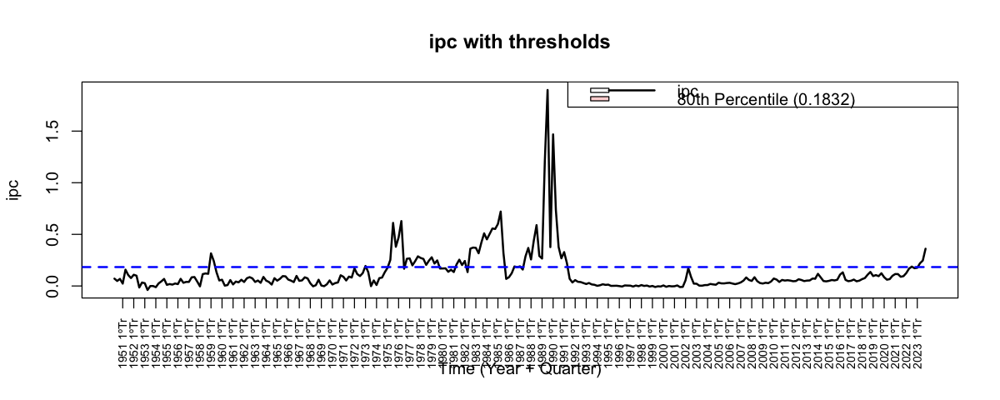

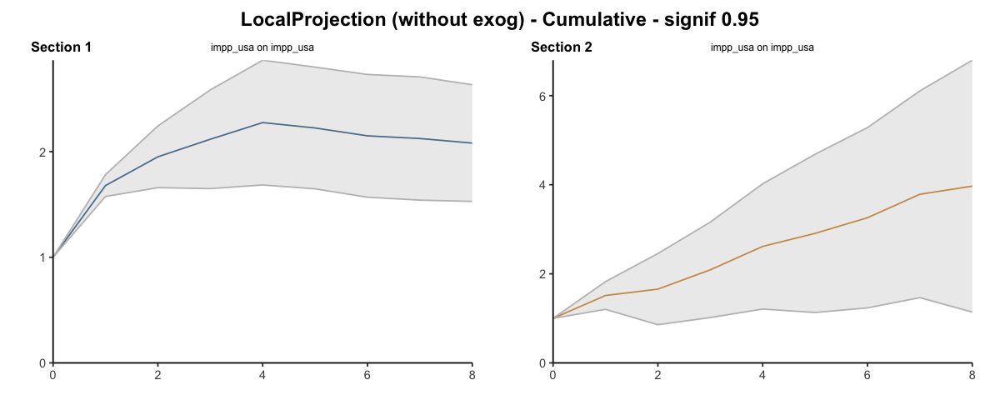

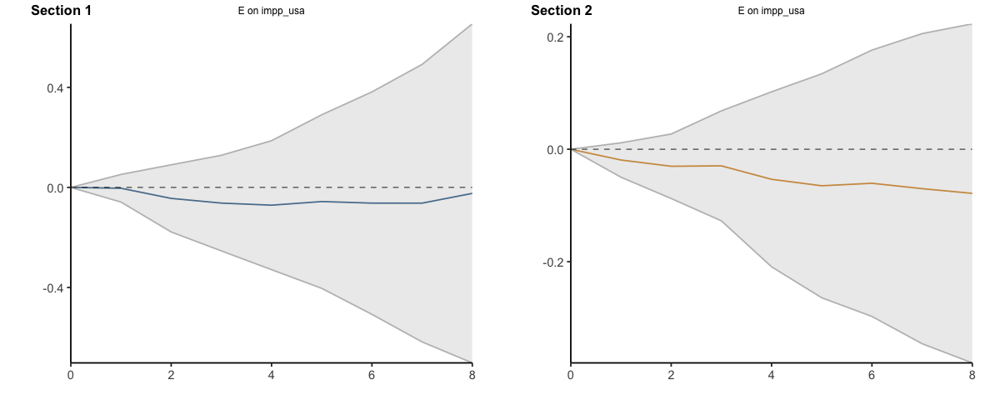

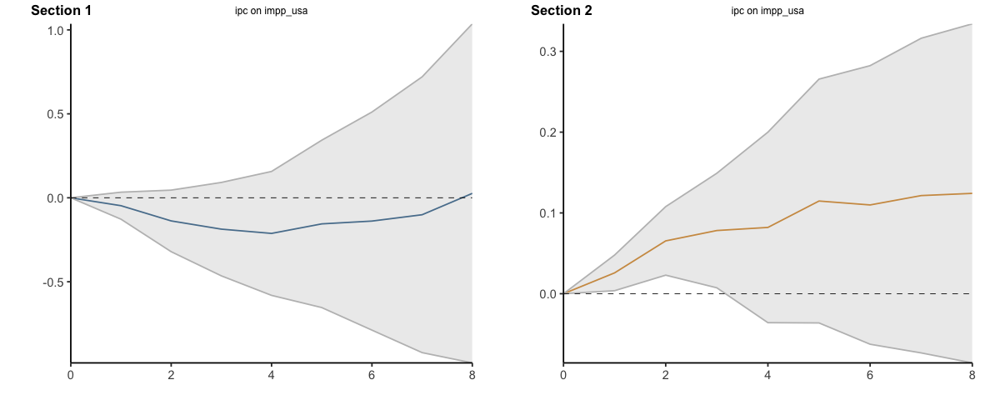

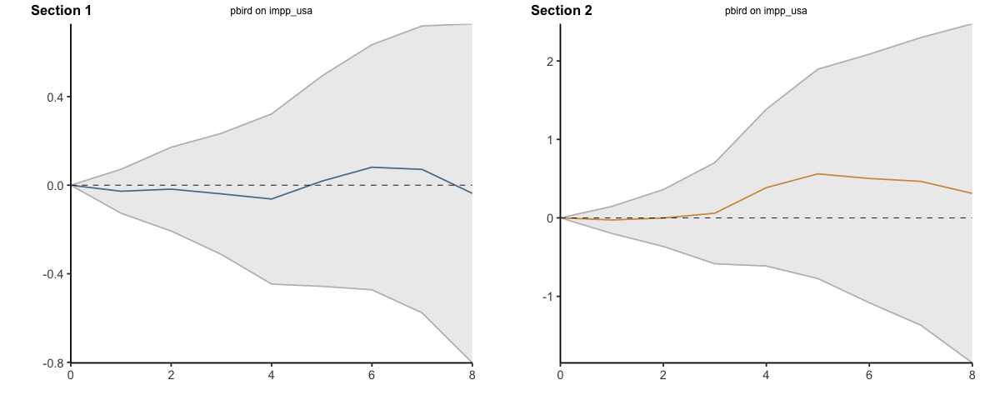

...

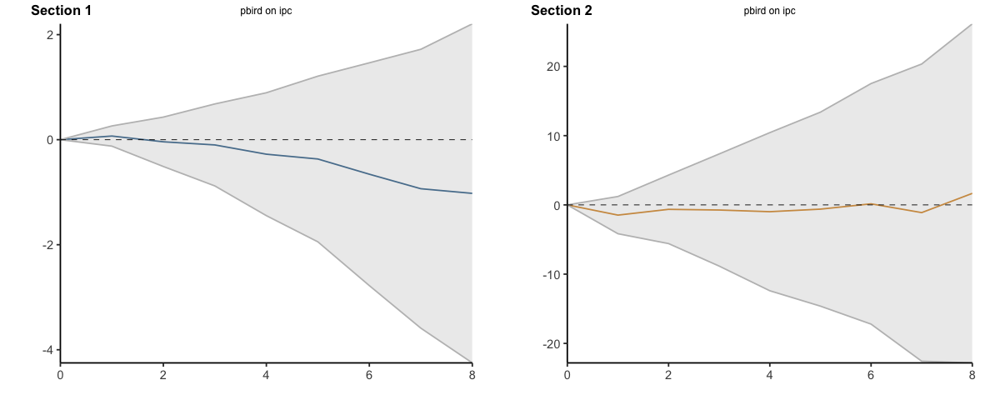

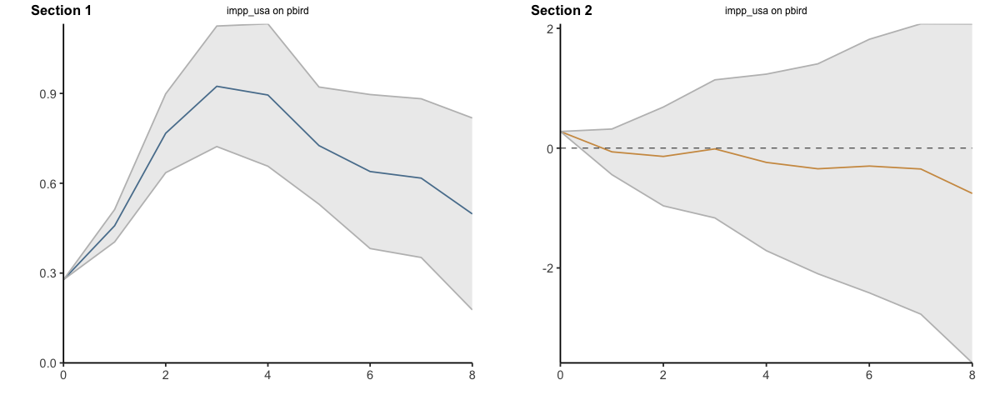

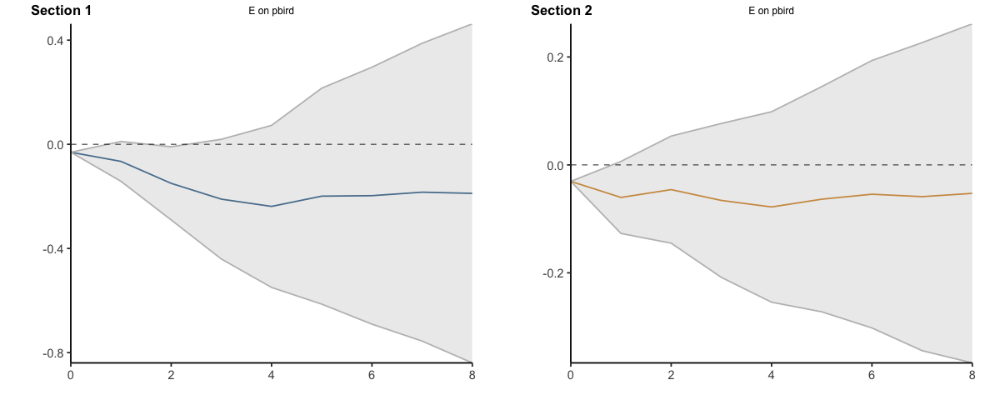

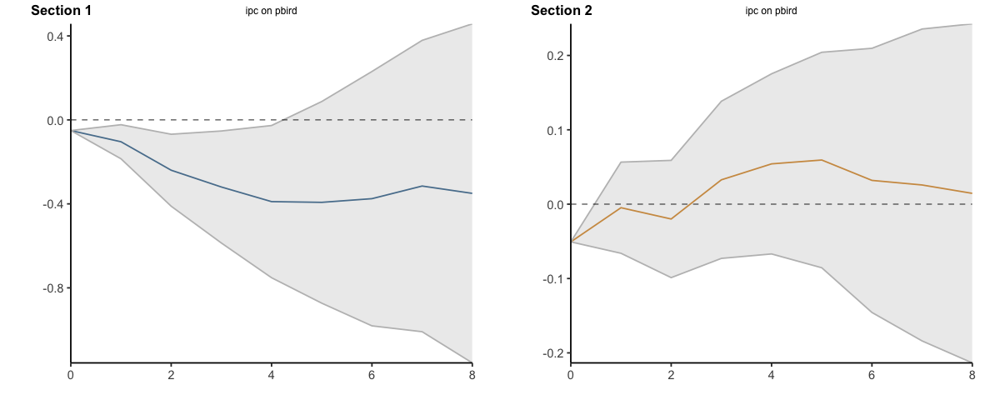

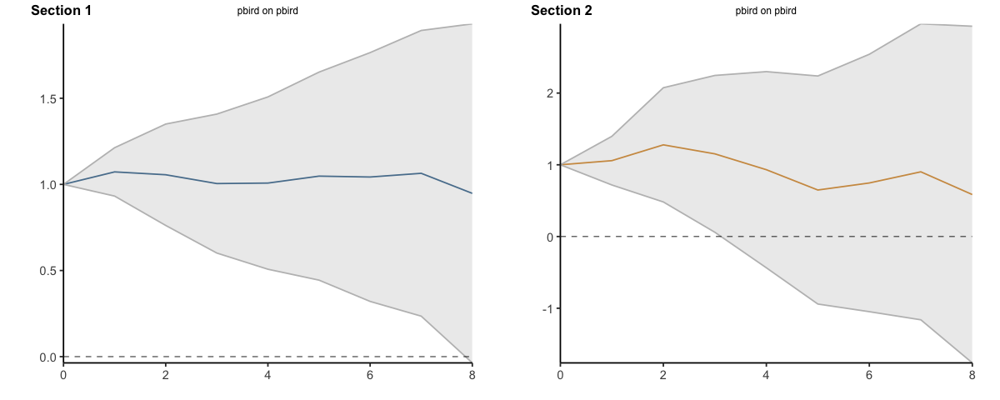

In [13]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.8, cumulative=TRUE)

#### Percentile 80 - 2 lags

Umbral: ipc > 0.1832 (percentil 80 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 236 | encima del umbral (dummy = 1) = 59 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, umbral: ipc > 0,183, 59 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.8492         0.5614       1.5126
         2              1.2880         0.6698       1.9229
         3              1.6598         0.7728       2.1479
         4              1.9836         0.8665       2.2893
         5              2.2105         0.9167       2.4114
         6              2.3212         0.9543       2.4323
         7              2.4261         0.9751       2.4880
         8              2.5020         0.9447       2.6484
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.3930             0.1052
                  0.4389             0.1085
                  0.3

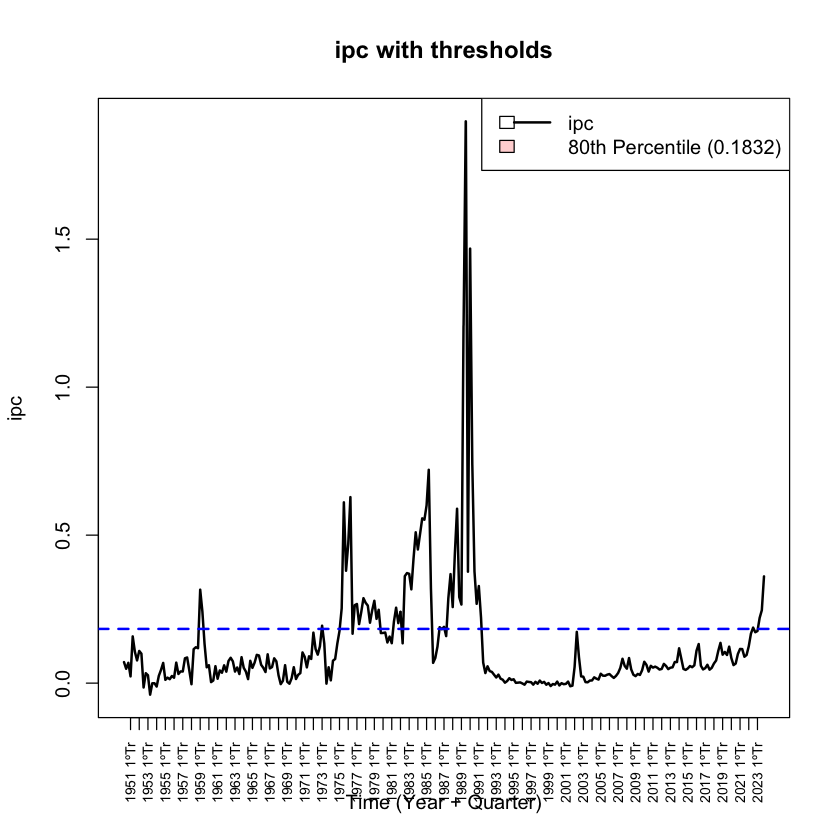

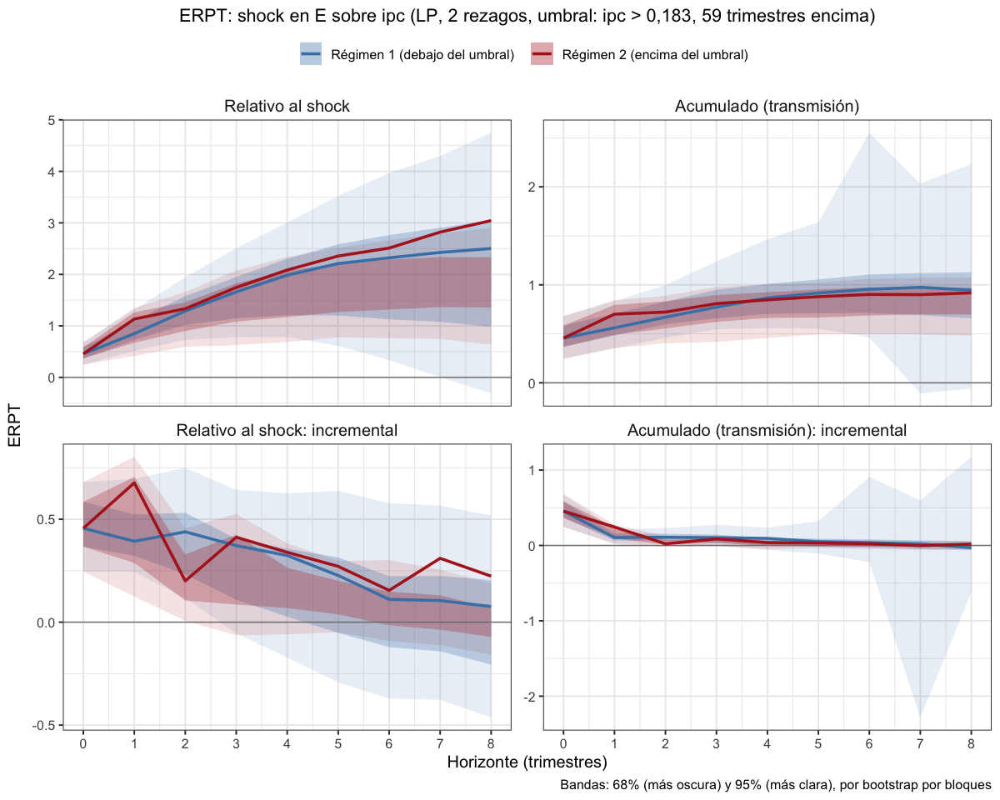

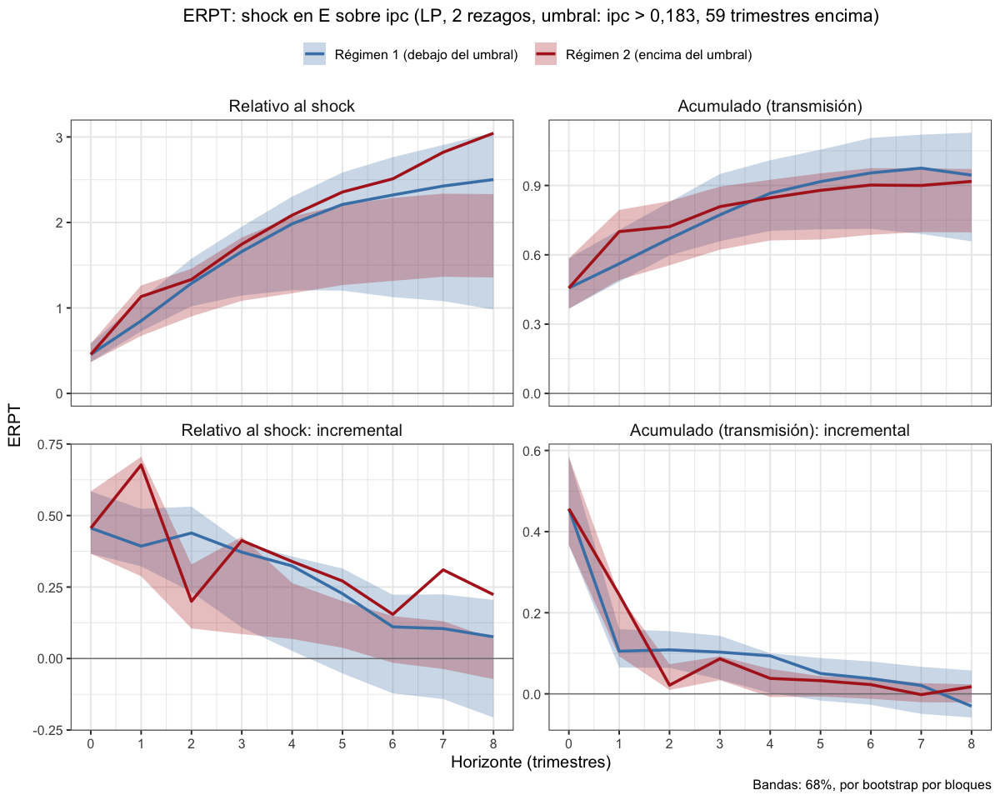

In [8]:
# Todas endógenas con umbral en el percentil 80 del ipc, 2 rezagos
lp_erpt_endog_p2_u80 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                fixed_lags = 2, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.8)
saveRDS(lp_erpt_endog_p2_u80, "lp_erpt_endog_p2_u80.rds")
graficar_erpt_lp(lp_erpt_endog_p2_u80, archivo = "lp_erpt_endog_p2_u80")
graficar_erpt_lp(lp_erpt_endog_p2_u80, niveles = 0.68, archivo = "lp_erpt_endog_p2_u80_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-0.19460906,-0.1946091,-0.1946091,-0.1946091,-0.1946091,-0.19460906
2,1,-0.38476157,-0.4843015,-0.2852216,-0.3144332,-0.5981523,-0.03071413
3,2,-0.25824721,-0.6304990,0.1140045,-0.7957946,-1.7404929,0.14890355
4,3,-0.21917841,-0.6729667,0.2346099,-0.8941804,-2.3024665,0.51410568
5,4,-0.09564744,-0.7685616,0.5772667,-0.5713996,-2.8671926,1.72439344
6,5,-0.18895642,-1.1066675,0.7287547,-0.2739340,-3.4381018,2.89023389
7,6,-0.30079238,-1.4247130,0.8231282,0.1243208,-3.7961679,4.04480960
8,7,-0.24341217,-1.6591195,1.1722952,0.7833778,-3.6701561,5.23691158
9,8,-0.27462473,-1.9245466,1.3752971,1.6120732,-3.5980103,6.82215674


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.028387373,-0.02838737,-0.02838737,-0.02838737,-0.02838737,-0.02838737
11,1,-0.012942262,-0.04287117,0.01698665,0.01227348,-0.20016613,0.22471310
12,2,0.007304529,-0.05807640,0.07268545,-0.32280765,-0.92090219,0.27528688
13,3,0.040286029,-0.07508764,0.15565969,-0.45329577,-1.45764018,0.55104865
14,4,0.145288469,-0.12754708,0.41812402,-0.18999634,-1.78723214,1.40723947
15,5,0.148931103,-0.18501565,0.48287786,0.04575586,-2.30882806,2.40033978
16,6,0.206693763,-0.23933524,0.65272277,0.43404266,-2.46490527,3.33299059
17,7,0.214215138,-0.43297527,0.86140555,0.93120964,-2.55606939,4.41848867
18,8,0.145397537,-0.66085731,0.95165238,1.31872340,-2.67869594,5.31614274


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.000000,0.00000000,0.0000000,0.000000,0.000000
92,1,-0.6909276,-1.327760,-0.05409555,-0.6925502,-3.126888,1.741788
93,2,-1.6869068,-3.300280,-0.07353388,0.7507904,-3.158391,4.659971
94,3,-2.1751330,-4.438397,0.08813115,-0.2145915,-7.343671,6.914488
95,4,-2.3926511,-5.221513,0.43621057,-0.8132348,-11.283100,9.656630
96,5,-1.8901069,-5.617290,1.83707653,0.3096520,-12.262406,12.881710
97,6,-1.9107860,-6.214884,2.39331181,-1.3938112,-17.162369,14.374747
98,7,-2.0810162,-7.300132,3.13809971,-1.9867973,-19.667987,15.694393
99,8,-2.6536228,-8.678509,3.37126311,1.4196156,-20.188752,23.027983


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.000000000,0.0000000,0.0000000,0.0000000,0.0000000,0.000000
101,1,0.008389923,-0.1386759,0.1554558,0.4124866,-0.8944198,1.719393
102,2,-0.218917563,-0.6684878,0.2306527,1.8584572,-0.9950984,4.712013
103,3,-0.362650836,-1.0932839,0.3679823,1.6638488,-3.5775380,6.905235
104,4,-0.520281393,-1.5894895,0.5489268,1.7885238,-6.1392937,9.716341
105,5,-0.576783055,-2.0062983,0.8527322,2.4107152,-7.0468666,11.868297
106,6,-0.609515946,-2.4321732,1.2131413,2.1181021,-9.4889800,13.725184
107,7,-0.507529523,-2.7779627,1.7629036,1.0613077,-12.9498271,15.072443
108,8,-0.548684105,-3.3474109,2.2500427,3.4128279,-13.5345426,20.360198


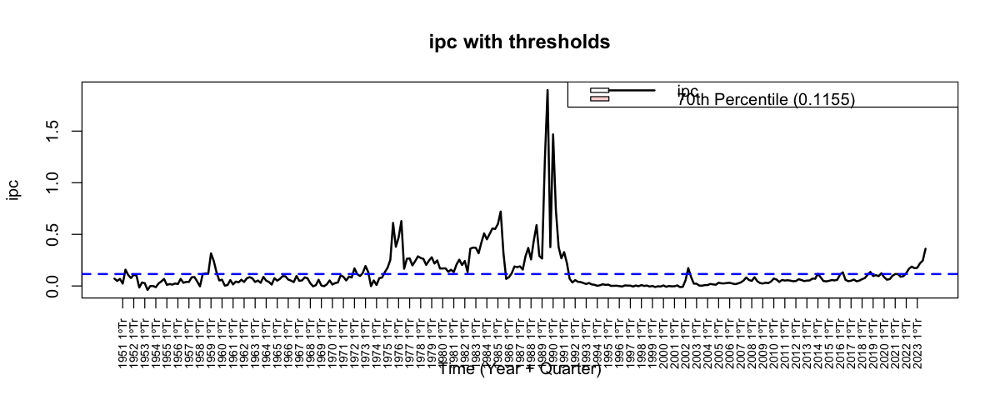

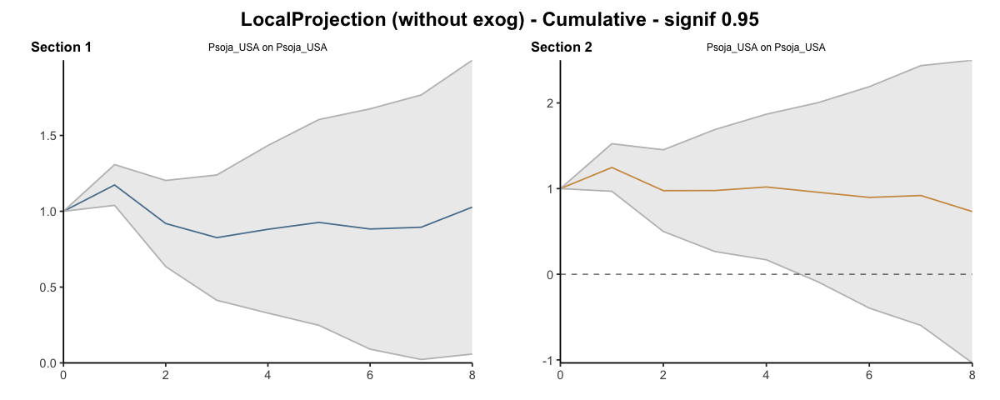

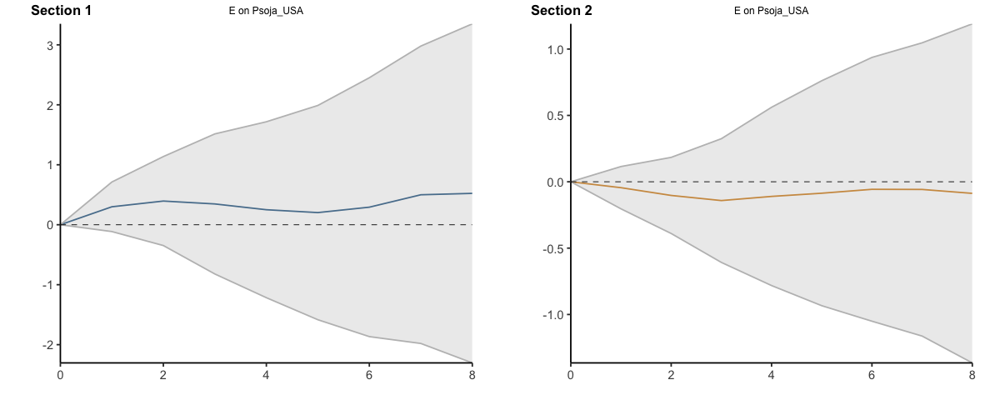

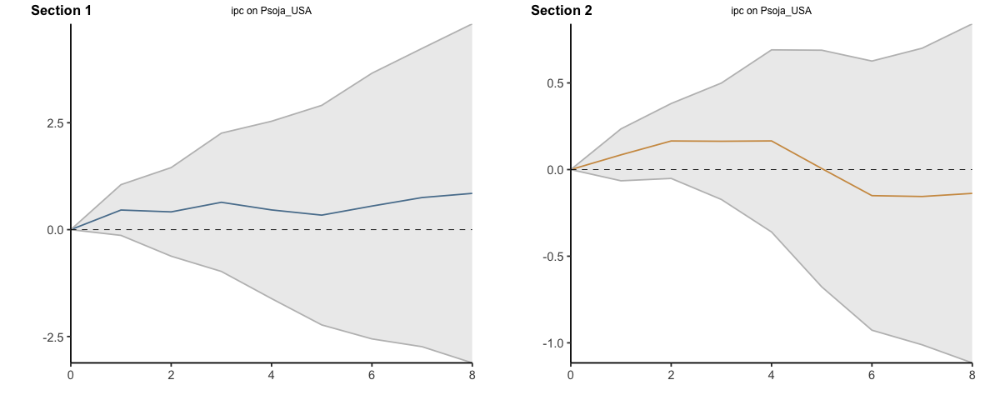

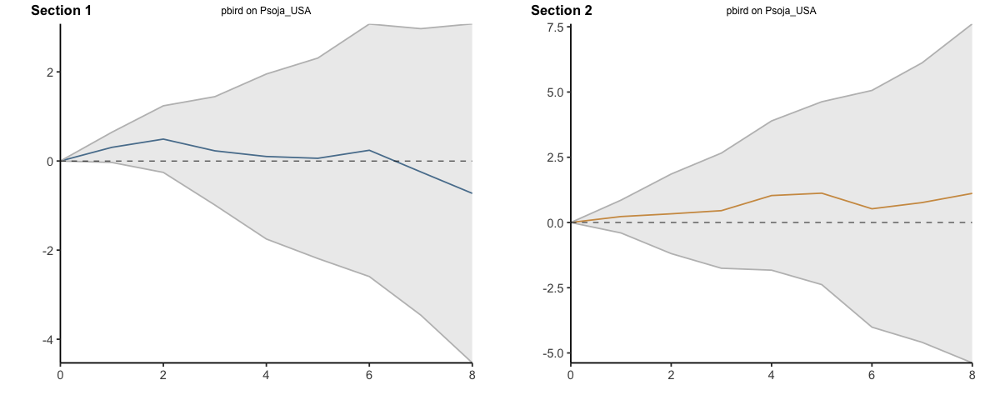

...

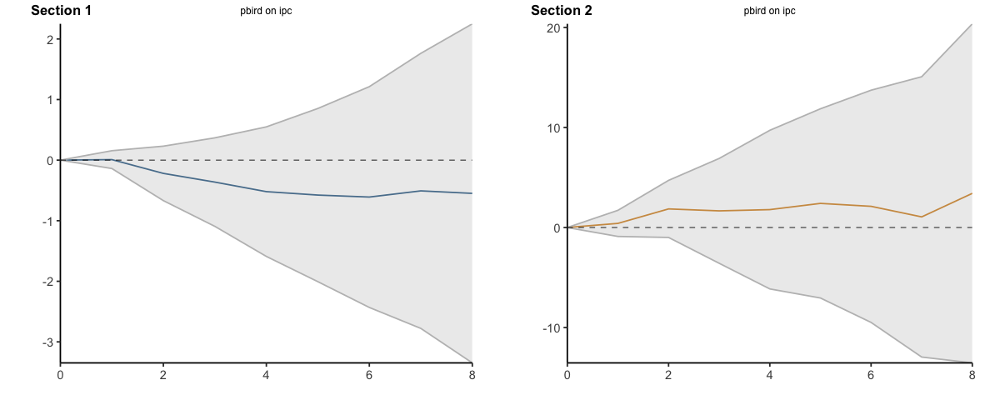

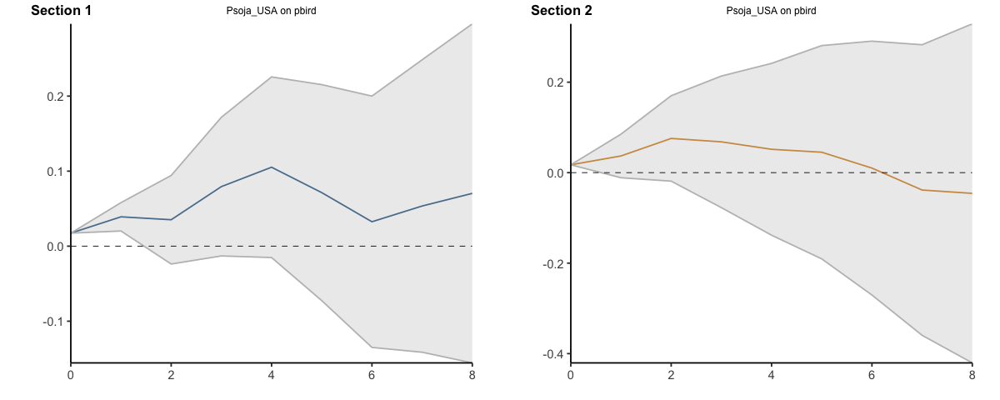

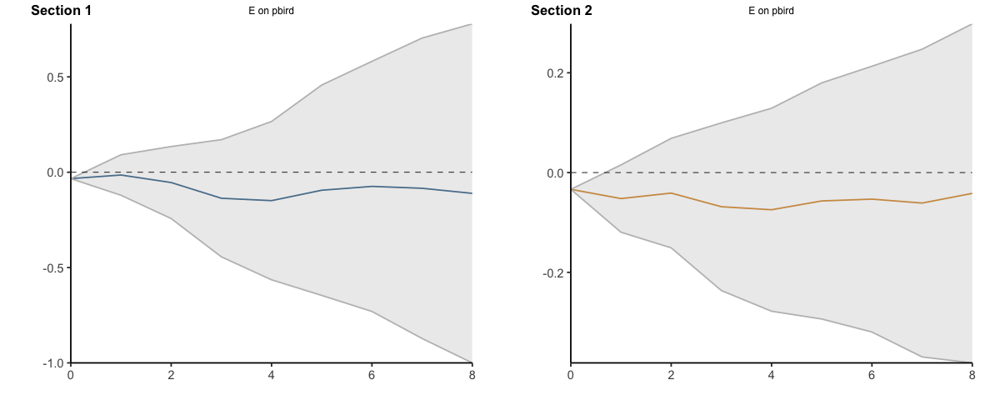

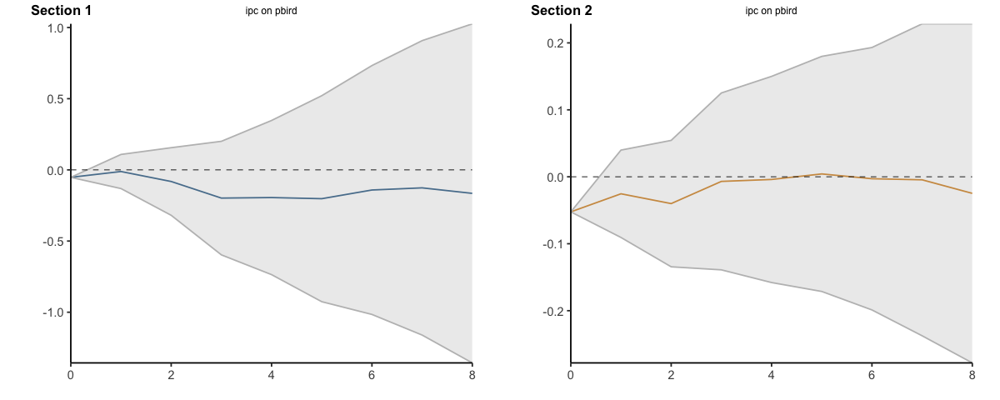

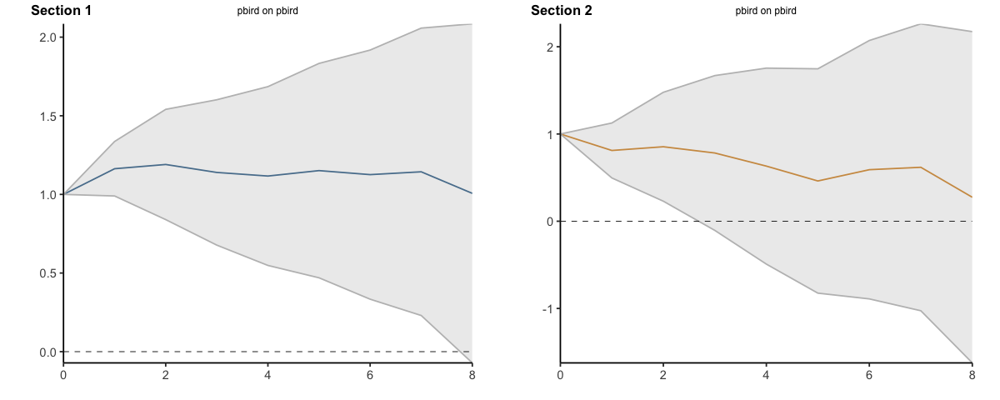

In [16]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-0.19460906,-0.19460906,-0.19460906,-0.19460906,-0.19460906,-0.1946091
2,1,-0.19015251,-0.28969246,-0.09061256,-0.11982417,-0.40354328,0.1638949
3,2,0.12651436,-0.14619745,0.39922617,-0.48136142,-1.14234051,0.1796177
4,3,0.03906881,-0.04246769,0.12060530,-0.09838576,-0.56197366,0.3652021
5,4,0.12353097,-0.09559491,0.34265685,0.32278085,-0.56472605,1.2102878
6,5,-0.09330899,-0.33810595,0.15148797,0.29746559,-0.57090927,1.1658405
7,6,-0.11183596,-0.31804547,0.09437355,0.39825481,-0.35806609,1.1545757
8,7,0.05738021,-0.23440652,0.34916694,0.65905691,0.12601185,1.1921020
9,8,-0.03121255,-0.26542706,0.20300196,0.82869545,0.07214574,1.5852452


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.028387373,-0.02838737,-0.02838737,-0.02838737,-0.02838737,-0.02838737
11,1,0.015445111,-0.01448380,0.04537402,0.04066086,-0.17177875,0.25310047
12,2,0.020246791,-0.01520523,0.05569881,-0.33508114,-0.72073606,0.05057379
13,3,0.032981500,-0.01701124,0.08297424,-0.13048811,-0.53673799,0.27576177
14,4,0.105002440,-0.05245945,0.26246433,0.26329943,-0.32959196,0.85619082
15,5,0.003642634,-0.05746857,0.06475384,0.23575220,-0.52159591,0.99310031
16,6,0.057762660,-0.05431959,0.16984491,0.38828680,-0.15607721,0.93265080
17,7,0.007521375,-0.19364003,0.20868278,0.49716698,-0.09116412,1.08549808
18,8,-0.068817601,-0.22788204,0.09024684,0.38751376,-0.12262655,0.89765406


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.00000000,0.0000000,0.00000000,0.0000000,0.00000000,0.000000
92,1,-0.69092759,-1.3277596,-0.05409555,-0.6925502,-3.12688836,1.741788
93,2,-0.99597916,-1.9725200,-0.01943833,1.4433406,-0.03150225,2.918183
94,3,-0.48822621,-1.1381175,0.16166504,-0.9653819,-4.18528025,2.254516
95,4,-0.21751811,-0.7831156,0.34807942,-0.5986433,-3.93942885,2.742142
96,5,0.50254421,-0.3957775,1.40086596,1.1228868,-0.97930658,3.225080
97,6,-0.02067908,-0.5975935,0.55623528,-1.7034633,-4.89996301,1.493037
98,7,-0.17023023,-1.0852484,0.74478789,-0.5929860,-2.50561774,1.319646
99,8,-0.57260665,-1.3783767,0.23316341,3.4064129,-0.52076471,7.333590


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.000000000,0.0000000,0.0000000,0.0000000,0.0000000,0.000000
101,1,0.008389923,-0.1386759,0.1554558,0.4124866,-0.8944198,1.719393
102,2,-0.227307486,-0.5298119,0.0751969,1.4459706,-0.1006785,2.992620
103,3,-0.143733273,-0.4247961,0.1373296,-0.1946084,-2.5824396,2.193223
104,4,-0.157630558,-0.4962056,0.1809445,0.1246750,-2.5617557,2.811106
105,5,-0.056501661,-0.4168088,0.3038054,0.6221915,-0.9075730,2.151956
106,6,-0.032732892,-0.4258749,0.3604091,-0.2926132,-2.4421134,1.856887
107,7,0.101986423,-0.3457894,0.5497623,-1.0567943,-3.4608471,1.347258
108,8,-0.041154582,-0.5694483,0.4871391,2.3515201,-0.5847155,5.287756


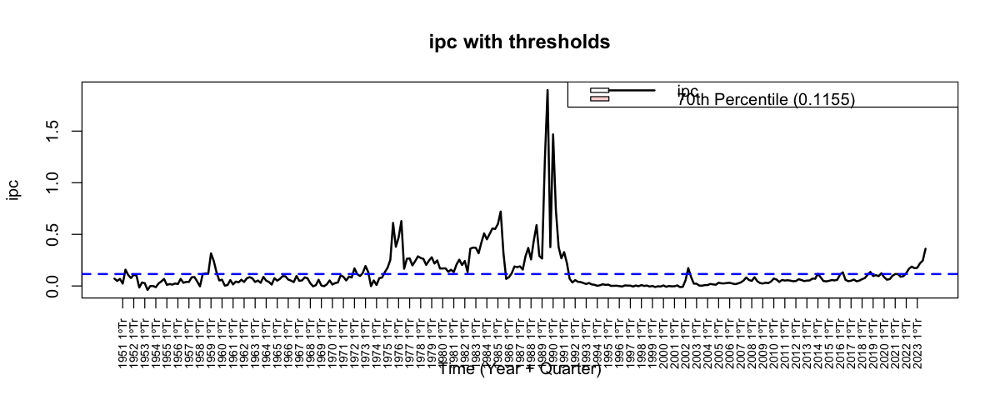

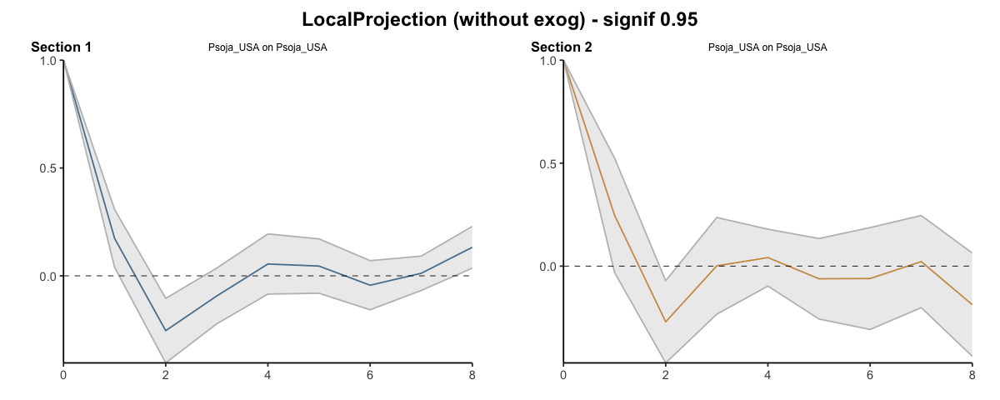

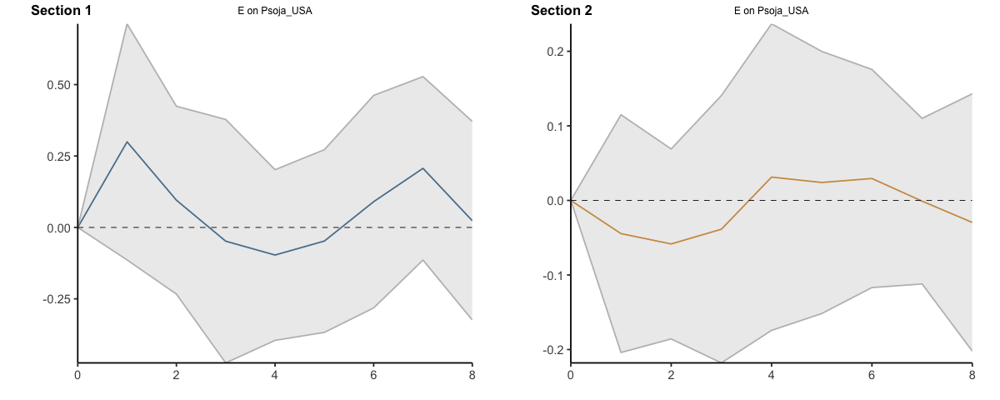

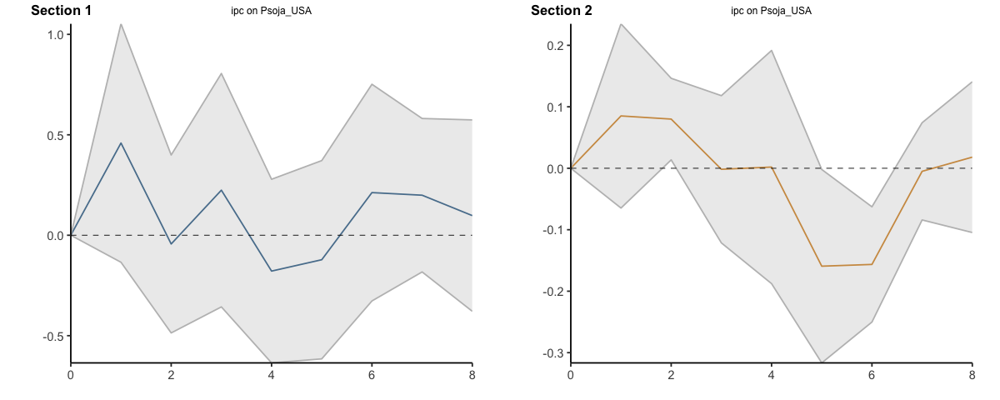

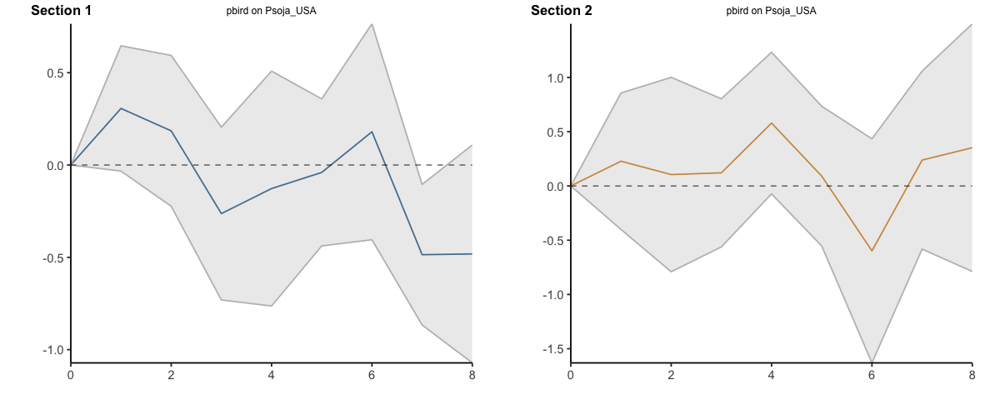

...

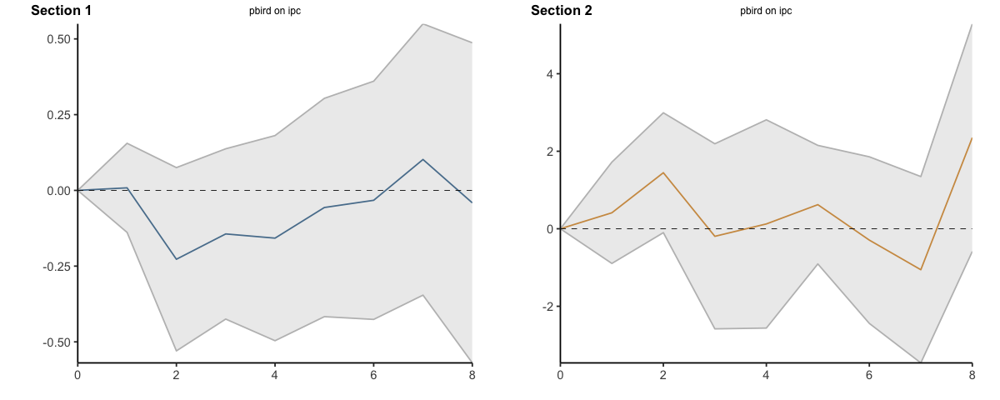

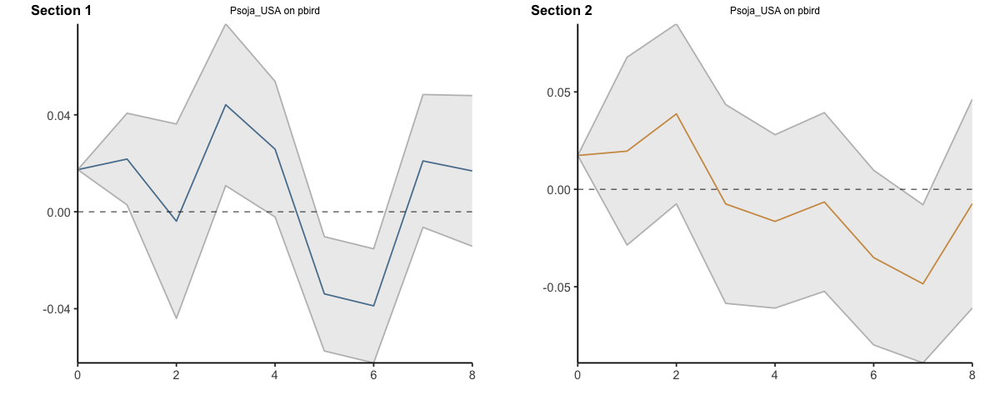

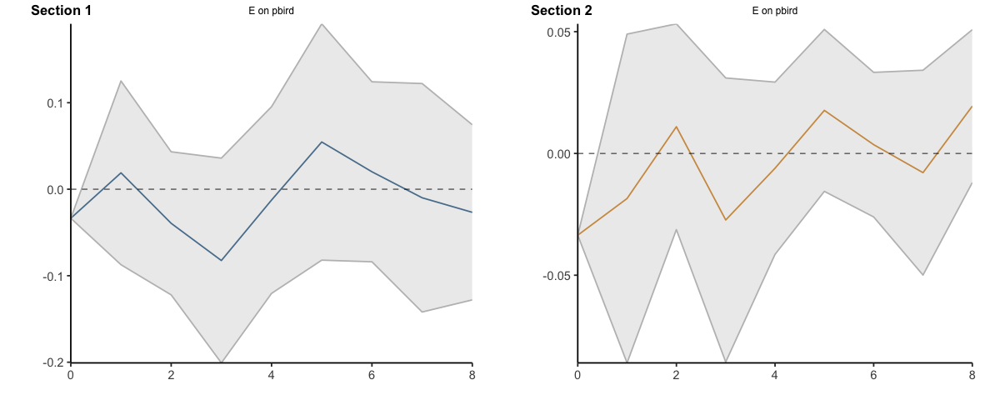

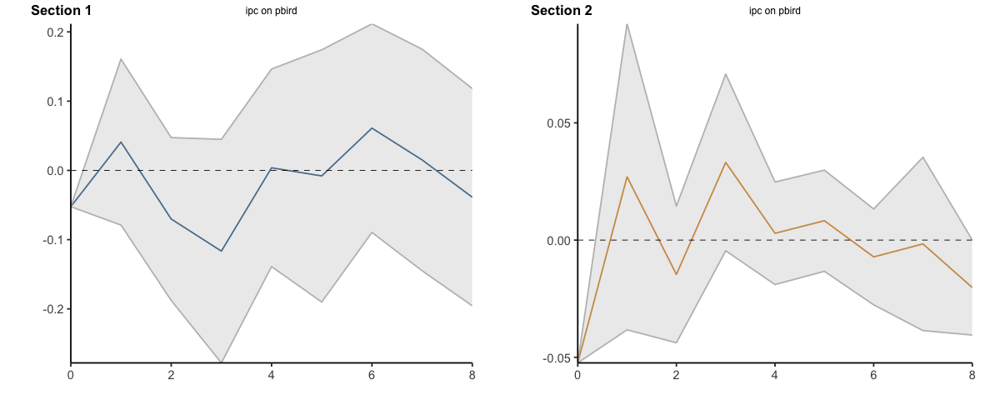

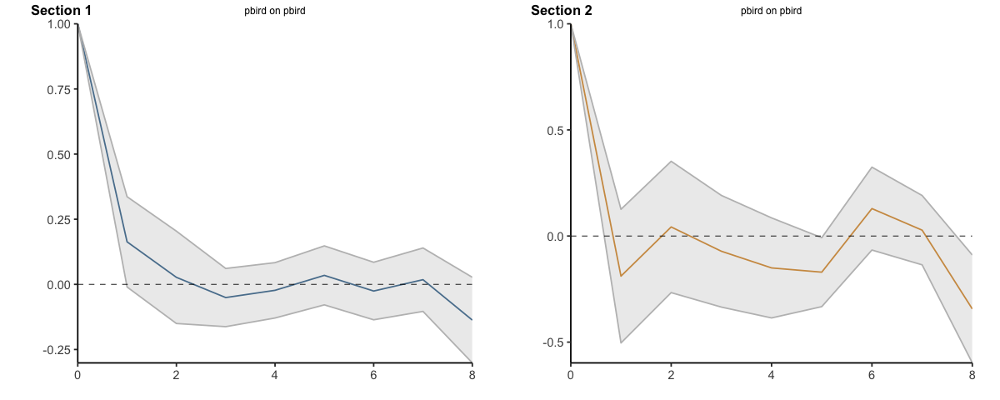

In [17]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 2, horizons=8, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.7)

#### Percentile 70 - 2 lags

Umbral: ipc > 0.1155 (percentil 70 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 206 | encima del umbral (dummy = 1) = 89 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, umbral: ipc > 0,115, 89 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.7998         0.5703       1.4023
         2              1.0247         0.6472       1.5834
         3              1.1648         0.8239       1.4138
         4              1.2569         0.9444       1.3309
         5              1.2313         0.9658       1.2749
         6              1.1871         1.0966       1.0825
         7              1.1938         1.4074       0.8482
         8              0.9756         3.1228       0.3124
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.3436             0.1141
                  0.2250             0.0769
                  0.1

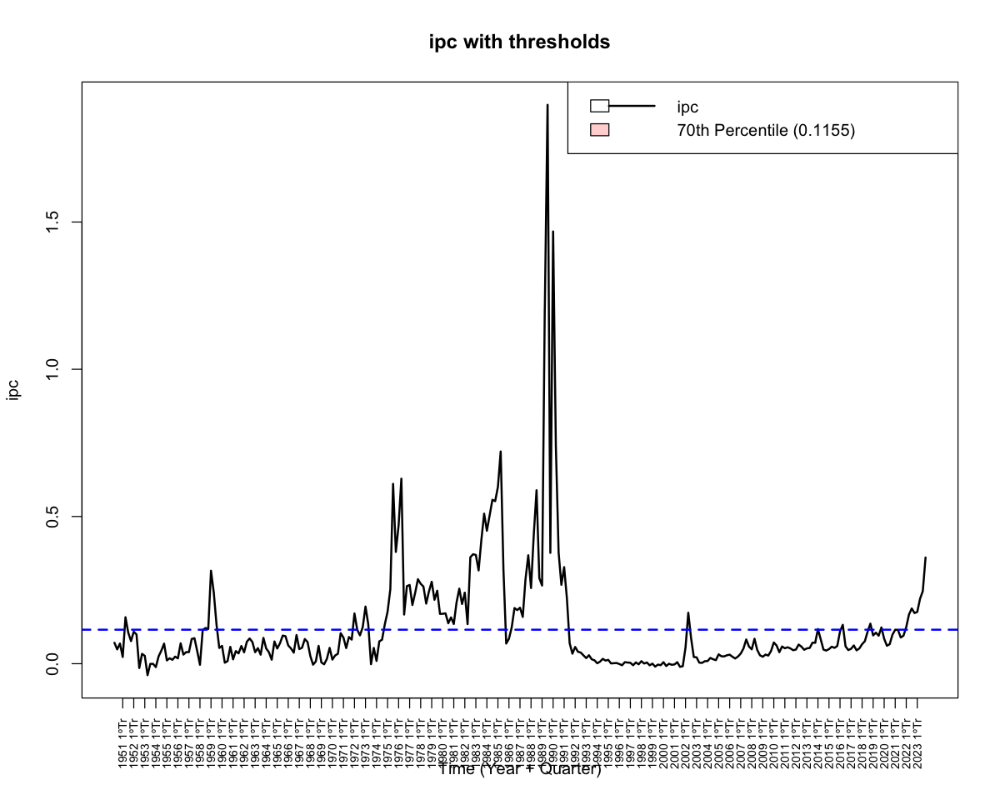

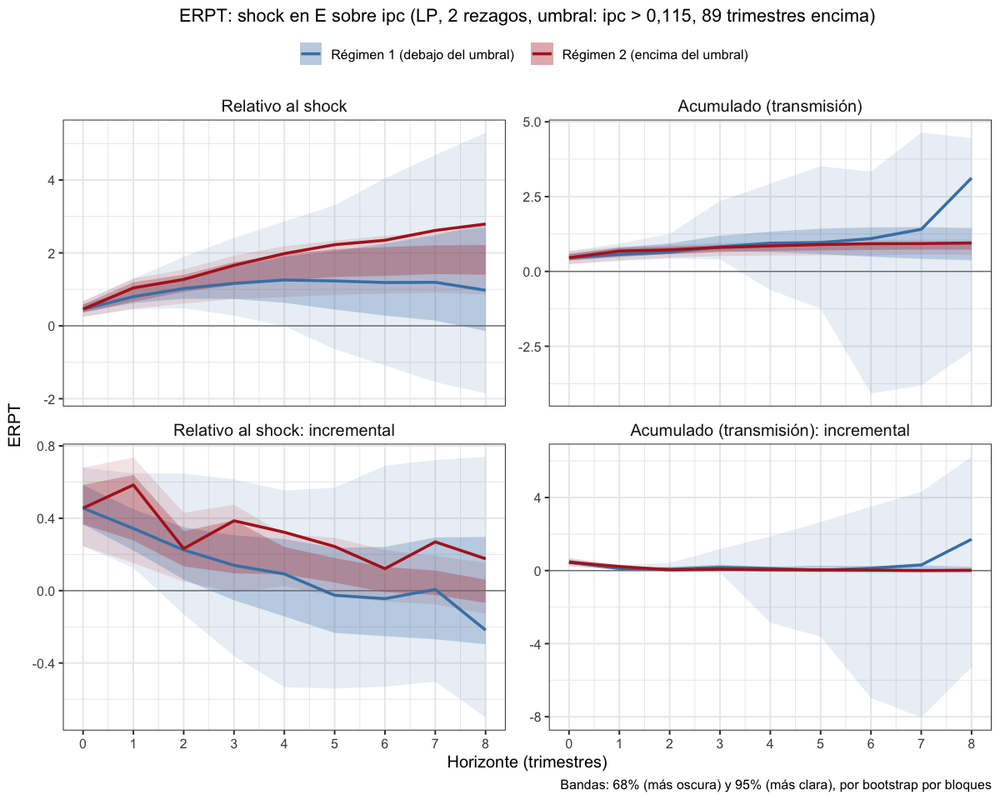

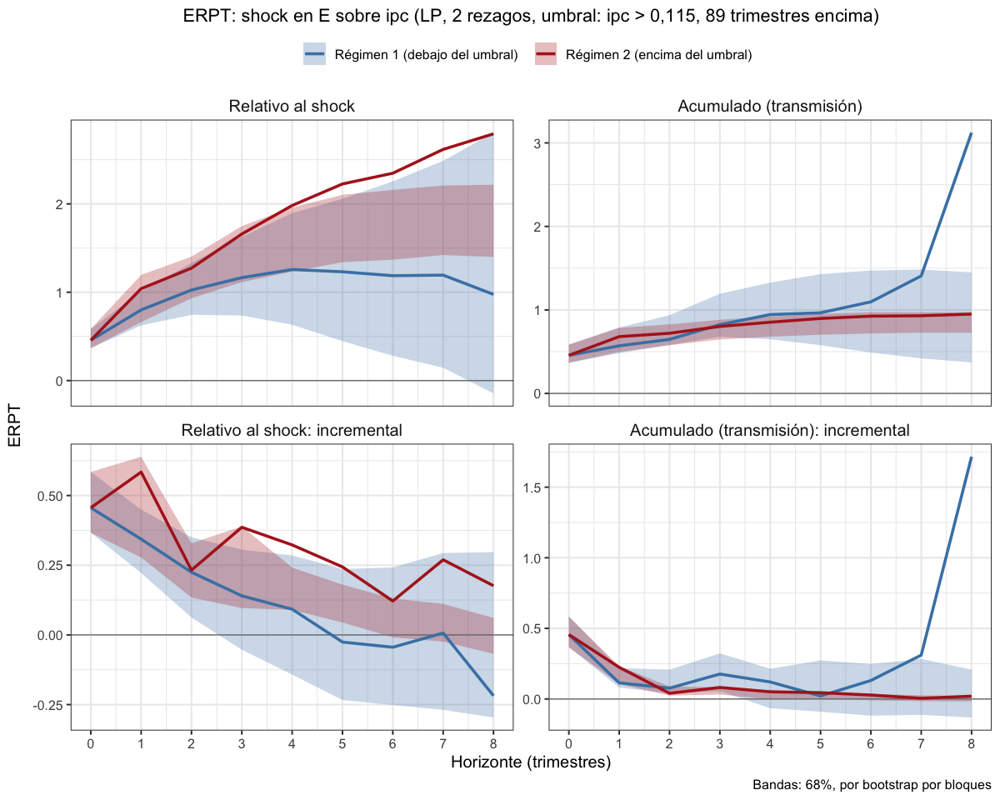

In [9]:
# Todas endógenas con umbral en el percentil 70 del ipc, 2 rezagos
lp_erpt_endog_p2_u70 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                fixed_lags = 2, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.7)
saveRDS(lp_erpt_endog_p2_u70, "lp_erpt_endog_p2_u70.rds")
graficar_erpt_lp(lp_erpt_endog_p2_u70, archivo = "lp_erpt_endog_p2_u70")
graficar_erpt_lp(lp_erpt_endog_p2_u70, niveles = 0.68, archivo = "lp_erpt_endog_p2_u70_68")

#### Encuentro percentil de umbral de inflación 12,5% y 37,6% trimestral

In [19]:
p_vlstar <- ecdf(df_ERPT_Arg$ipc)(0.125)   # percentil del umbral de los VLSTAR
p_tvar   <- ecdf(df_ERPT_Arg$ipc)(0.376)   # percentil del umbral del TVAR-indt
p_vlstar; p_tvar

# Chequeo: cuántos trimestres quedan por encima de cada umbral
sum(df_ERPT_Arg$ipc > 0.125, na.rm = TRUE)
sum(df_ERPT_Arg$ipc > 0.376, na.rm = TRUE)

[1] 0.7254237

[1] 0.9322034

[1] 81

[1] 20

#### No hace falta correr run_lp_model (excepto que quiera tener las IRF entre todas las variables). No hace falta poner el percentil; con p_vlstar lo encuentra.

#### Percentile 0.725423728813559 (12,5% inflación trimestral) - quedan 81 trimestres por encima del umbral


Umbral: ipc > 0.1265 (percentil 72.5 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 214 | encima del umbral (dummy = 1) = 81 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, umbral: ipc > 0,127, 81 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.8625         0.6199       1.3914
         2              1.1674         0.7247       1.6110
         3              1.3431         0.8904       1.5085
         4              1.4502         1.0241       1.4160
         5              1.4742         1.0495       1.4046
         6              1.5067         1.1367       1.3254
         7              1.5484         1.3389       1.1565
         8              1.4255         1.8495       0.7707
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.4064             0.1637
                  0.3049             0.1048
                  0.1

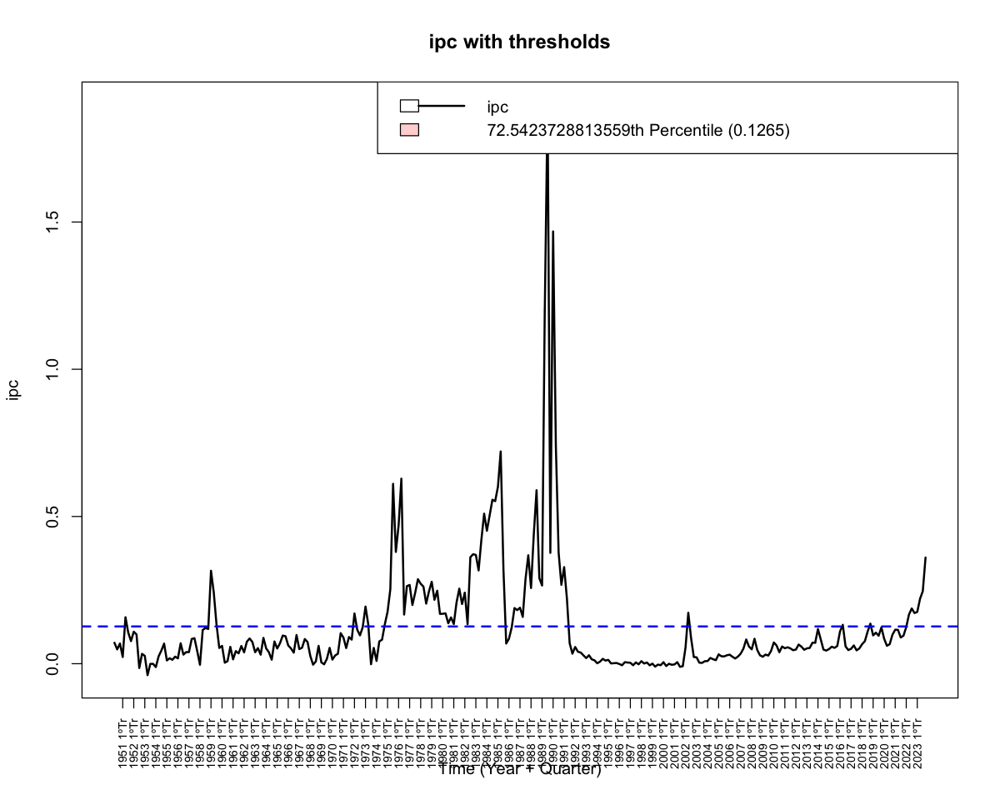

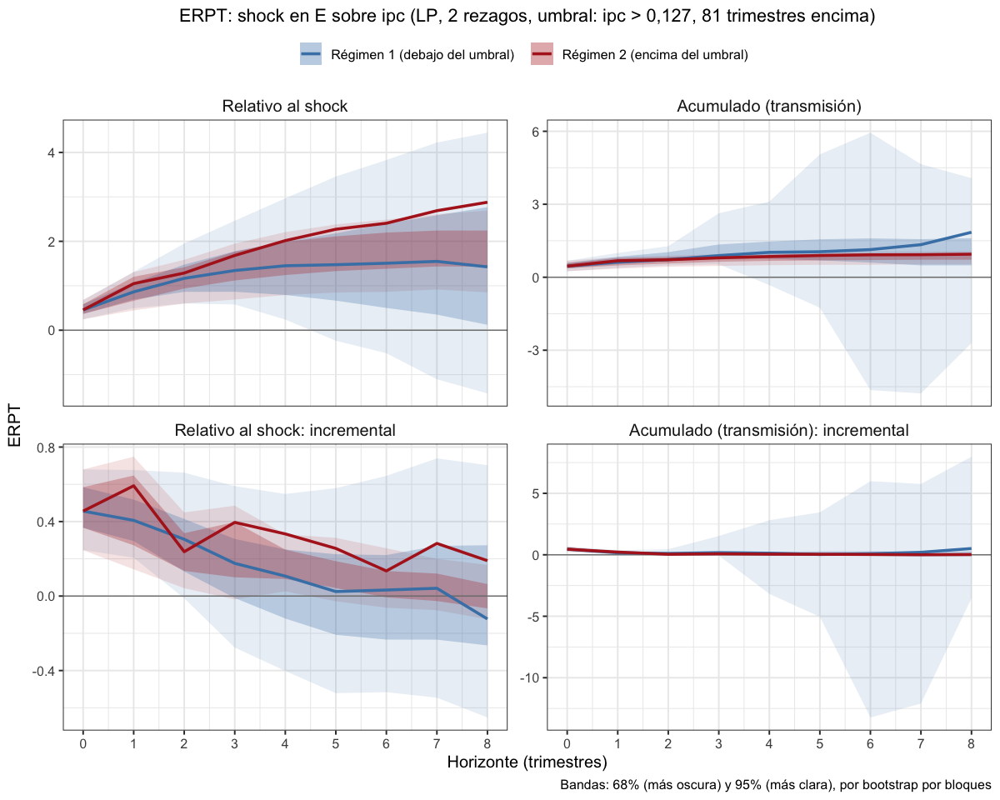

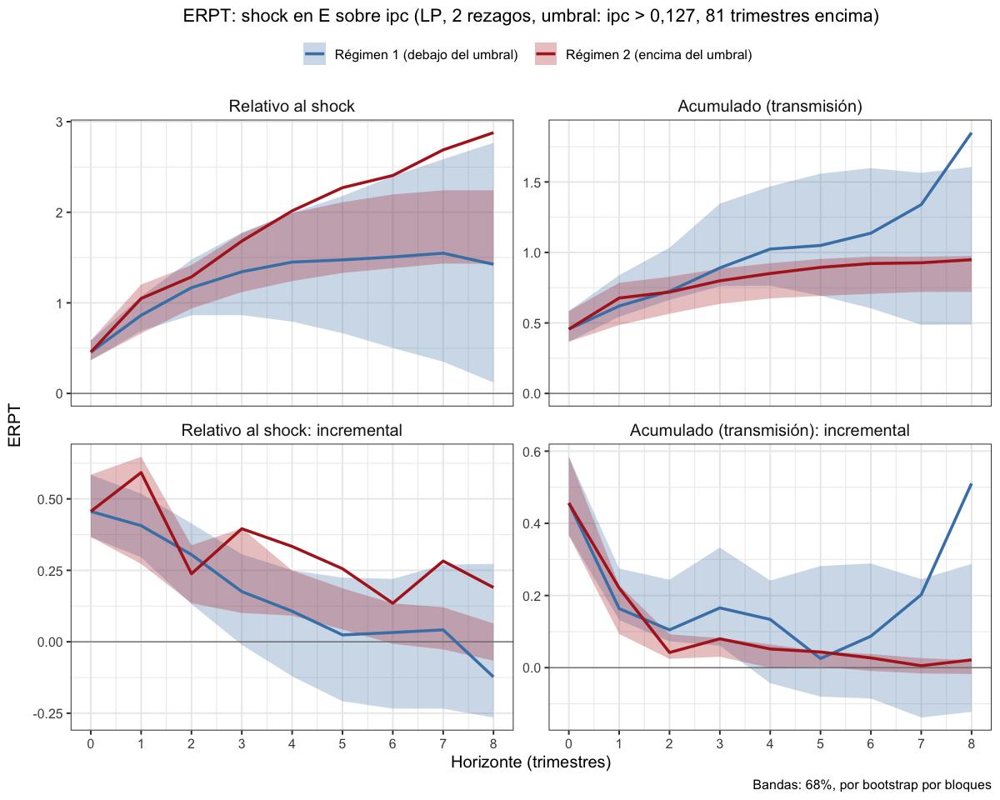

In [10]:
lp_erpt_endog_p2_tvar12.5 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                     fixed_lags = 2, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.725423728813559)
saveRDS(lp_erpt_endog_p2_tvar12.5, "lp_erpt_endog_p2_tvar12.5.rds")
graficar_erpt_lp(lp_erpt_endog_p2_tvar12.5, archivo = "lp_erpt_endog_p2_tvar12.5")
graficar_erpt_lp(lp_erpt_endog_p2_tvar12.5, niveles = 0.68, archivo = "lp_erpt_endog_p2_tvar12.5_68")

#### Percentile 0.932203389830508 (37,6% de inflación trimestral) - quedan 20 trimestres por encima del umbral (son pocos)

Umbral: ipc > 0.3722 (percentil 93.2 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 275 | encima del umbral (dummy = 1) = 20 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%


3 réplicas fallaron y se descartaron.



ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, umbral: ipc > 0,372, 20 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4562         0.4562       1.0000
         1              0.9273         0.5914       1.5681
         2              1.3443         0.7027       1.9130
         3              1.6426         0.7671       2.1414
         4              2.0857         0.8536       2.4434
         5              2.3899         0.8936       2.6746
         6              2.7799         0.9105       3.0533
         7              3.4027         0.9262       3.6738
         8              3.9018         0.9348       4.1739
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4562             0.4562
                  0.4711             0.1352
                  0.4170             0.1114
                  0.2983             0.0643
                  0.4431             0.0866
             

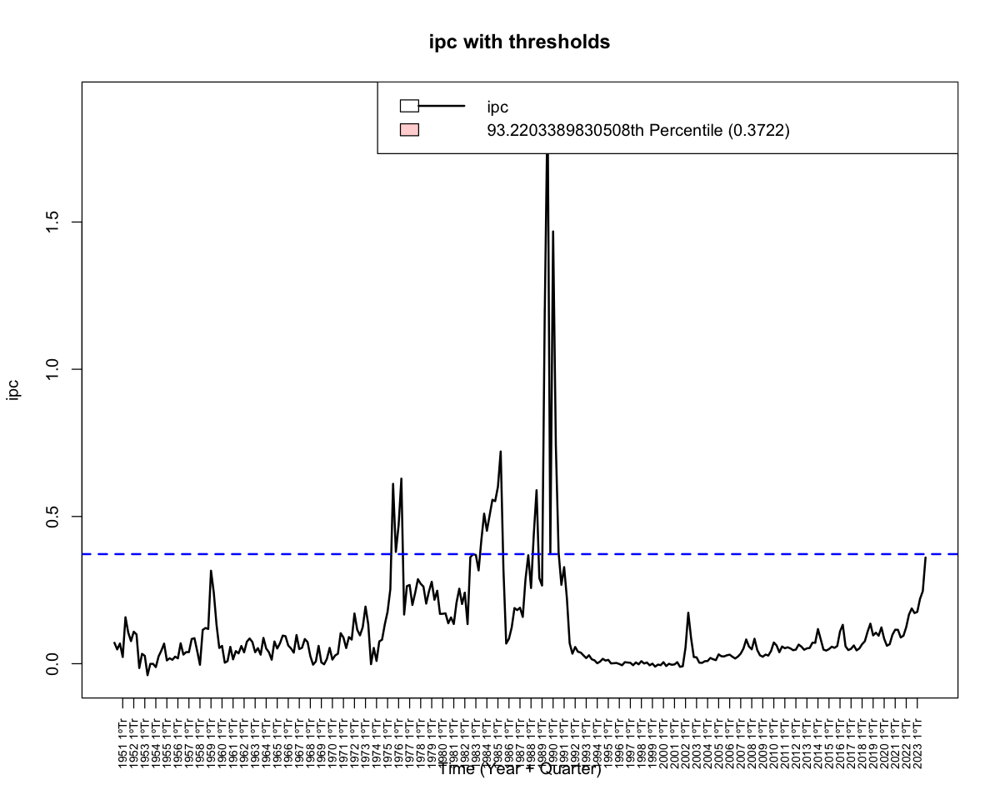

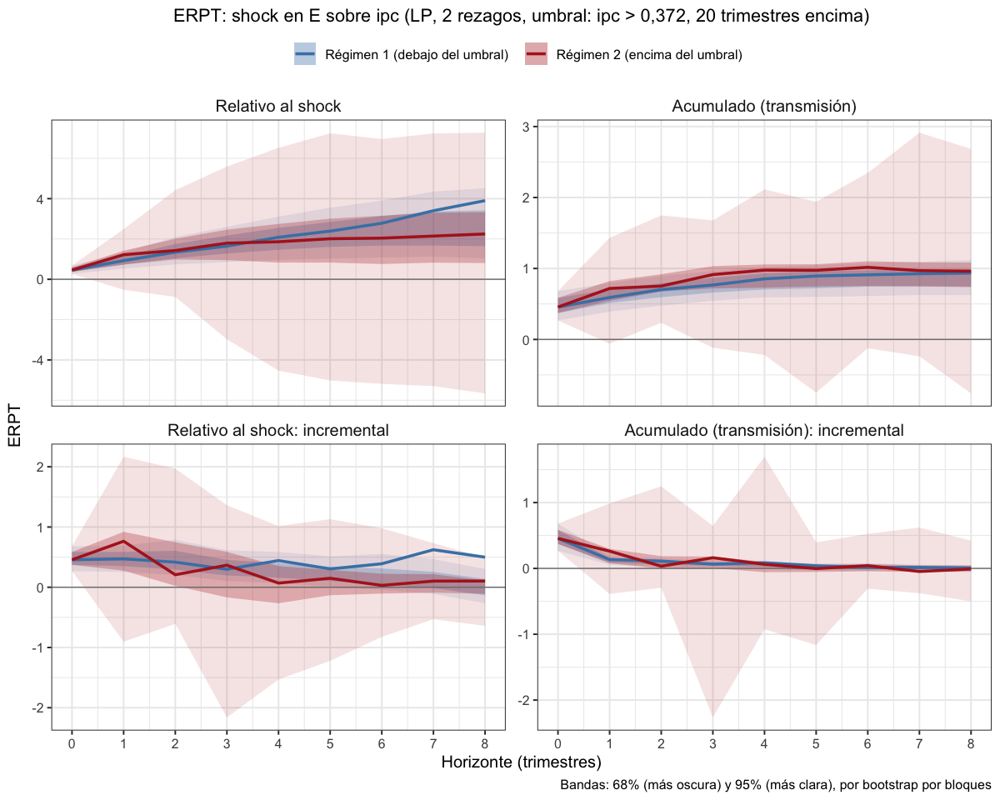

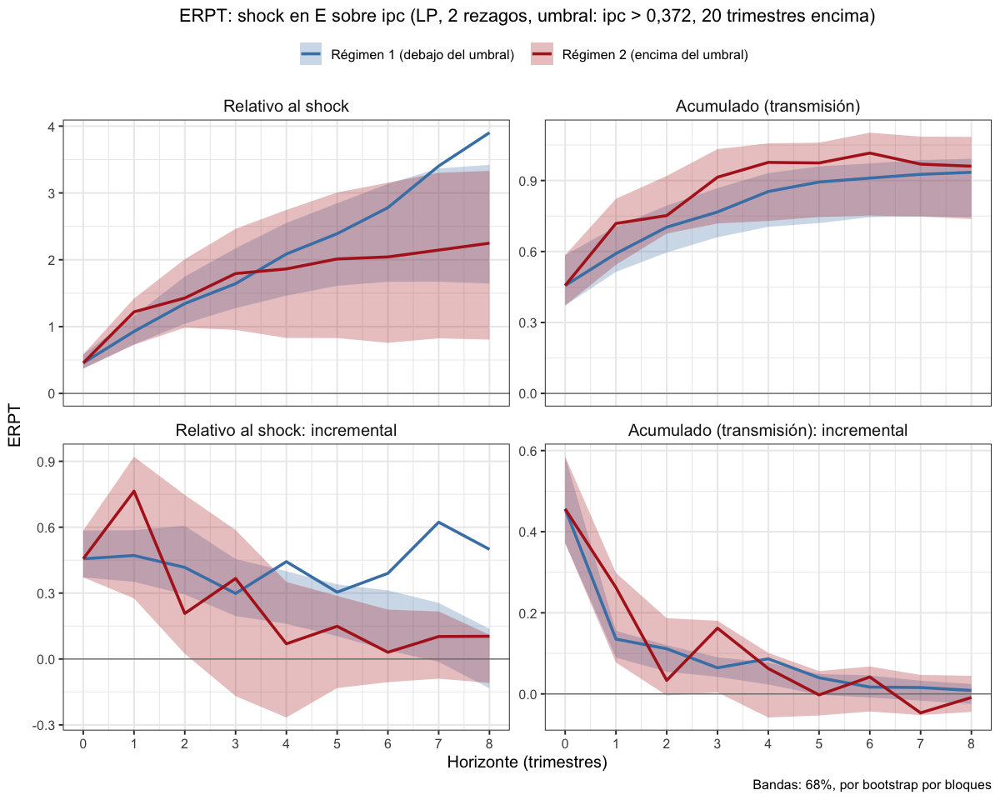

In [11]:
# Todas endógenas con umbral en 37,6% de inflación trimestral (umbral del TVAR-indt), 2 rezagos
lp_erpt_endog_p2_tvar37.6 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                     fixed_lags = 2, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.932203389830508)
saveRDS(lp_erpt_endog_p2_tvar37.6, "lp_erpt_endog_p2_tvar37.6.rds")
graficar_erpt_lp(lp_erpt_endog_p2_tvar37.6, archivo = "lp_erpt_endog_p2_tvar37.6")
graficar_erpt_lp(lp_erpt_endog_p2_tvar37.6, niveles = 0.68, archivo = "lp_erpt_endog_p2_tvar37.6_68")

#### Otros percentiles (sin actualizar, son viejos con psoja)


Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.19460906,-0.1946091,-0.1946091,-0.1946091,-0.1946091,-0.1946091
2,2,-0.38919650,-0.4967647,-0.2816283,-0.3824255,-0.5819266,-0.1829244
3,3,-0.25324193,-0.6612851,0.1548013,-0.8346927,-1.5449205,-0.1244649
4,4,-0.21589586,-0.6932765,0.2614848,-0.9333860,-1.9909816,0.1242096
5,5,-0.07261882,-0.7810548,0.6358171,-0.7144333,-2.4912743,1.0624077
6,6,-0.16688502,-1.1271021,0.7933320,-0.4931996,-2.9796269,1.9932277
7,7,-0.28894835,-1.4470896,0.8691929,-0.1850469,-3.2595827,2.8894889
8,8,-0.23710449,-1.7097765,1.2355675,0.2675465,-3.2155303,3.7506232
9,9,-0.26538707,-1.9841112,1.4533371,0.9151092,-3.1942369,5.0244552


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.028387373,-0.02838737,-0.02838737,-0.02838737,-0.02838737,-0.02838737
13,2,-0.004031917,-0.03142829,0.02336446,-0.05202429,-0.21218876,0.10814019
14,3,0.015422113,-0.04718067,0.07802490,-0.36277477,-0.78745393,0.06190438
15,4,0.057423344,-0.05316634,0.16801302,-0.51930970,-1.23489927,0.19627987
16,5,0.162009258,-0.10058189,0.42460041,-0.33345930,-1.54149094,0.87457235
17,6,0.154674873,-0.14309532,0.45244507,-0.15873319,-1.97798658,1.66052019
18,7,0.189315573,-0.20576124,0.58439239,0.17973370,-2.08403562,2.44350303
19,8,0.171537999,-0.41973801,0.76281401,0.54073219,-2.21939699,3.30086137
20,9,0.087518713,-0.67071443,0.84575186,0.79779689,-2.37767045,3.97326422


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.000000,0.000000,0.00000000,0.0000000,0.000000,0.0000000
112,2,-0.599547,-1.287054,0.08795953,-1.0595455,-2.886165,0.7670734
113,3,-1.712218,-3.466702,0.04226644,0.1905250,-2.769535,3.1505854
114,4,-2.277038,-4.764662,0.21058610,-0.5594193,-5.864326,4.7454870
115,5,-2.525552,-5.623386,0.57228261,-1.1997963,-9.217340,6.8177476
116,6,-2.050070,-6.110592,2.01045233,-0.1098688,-9.798061,9.5783233
117,7,-2.180099,-6.914278,2.55407991,-1.2243055,-13.411433,10.9628216
118,8,-2.535089,-8.268475,3.19829693,-1.6857795,-15.342965,11.9714057
119,9,-3.235860,-9.752159,3.28043912,0.8732901,-15.678984,17.4255637


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.00000000,0.00000000,0.0000000,0.000000
123,2,-0.06417718,-0.2198717,0.09151736,0.07910029,-0.9936633,1.151864
124,3,-0.36062277,-0.7987336,0.07748805,1.32660015,-0.9814100,3.634610
125,4,-0.56364562,-1.2781163,0.15082509,1.19353027,-2.8531950,5.240256
126,5,-0.80047741,-1.8420738,0.24111902,1.24052315,-4.9390788,7.420125
127,6,-0.91615145,-2.3253878,0.49308490,1.68224942,-5.6690509,9.033550
128,7,-1.04411448,-2.8748594,0.78663045,1.69768626,-7.2785814,10.673954
129,8,-1.08149384,-3.4061059,1.24311824,0.87891823,-10.3844761,12.142313
130,9,-1.28667371,-4.1764795,1.60313207,2.82574551,-10.5491943,16.200685


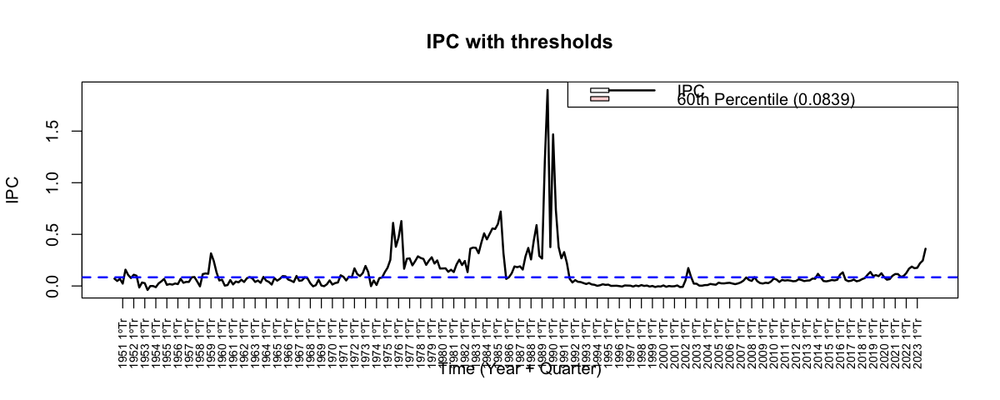

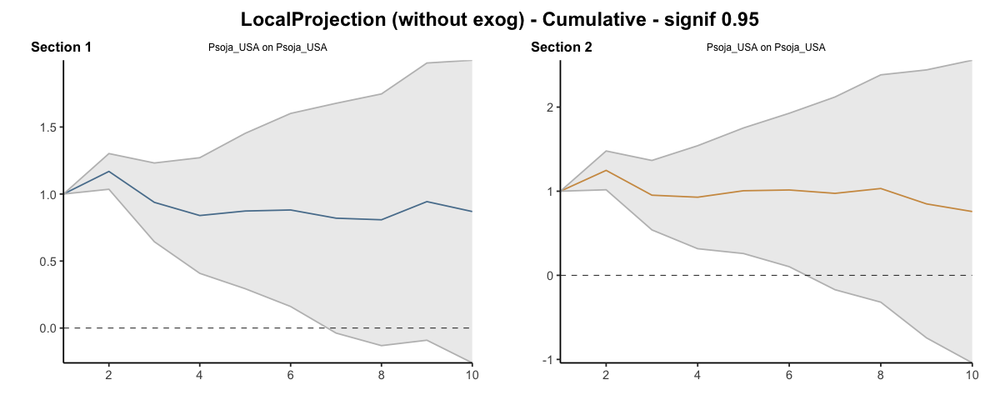

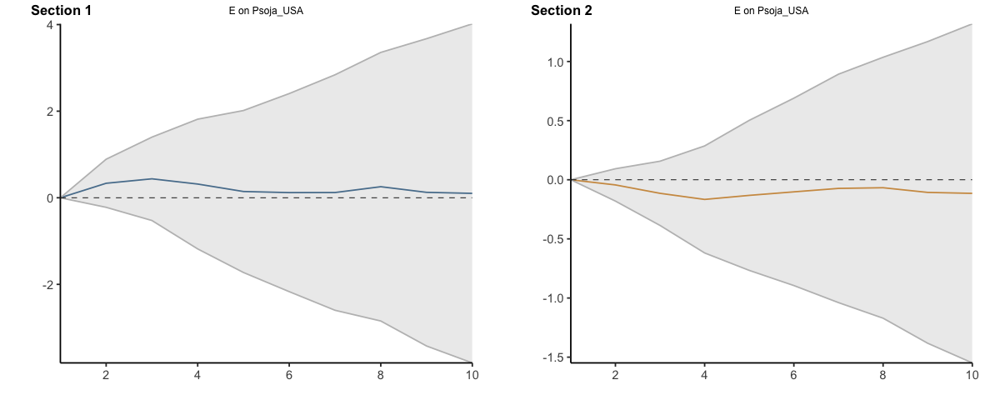

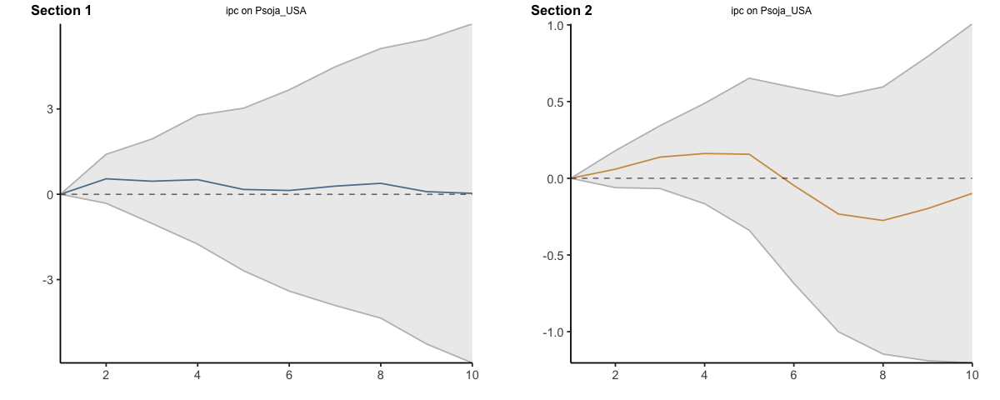

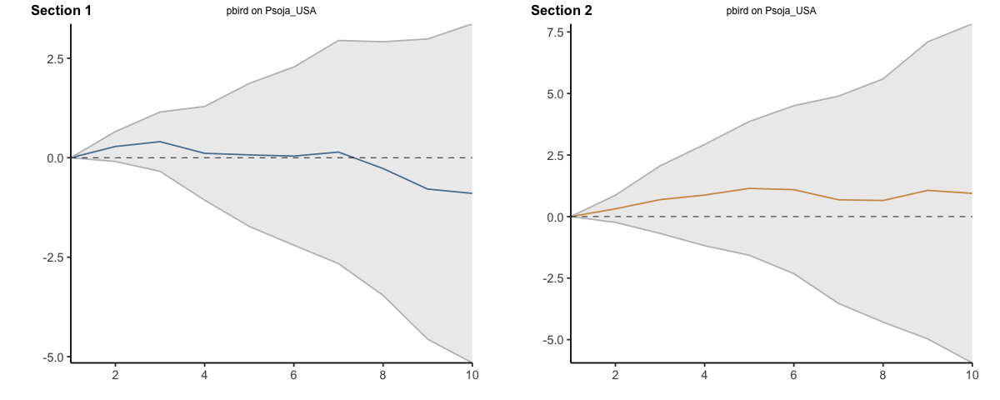

...

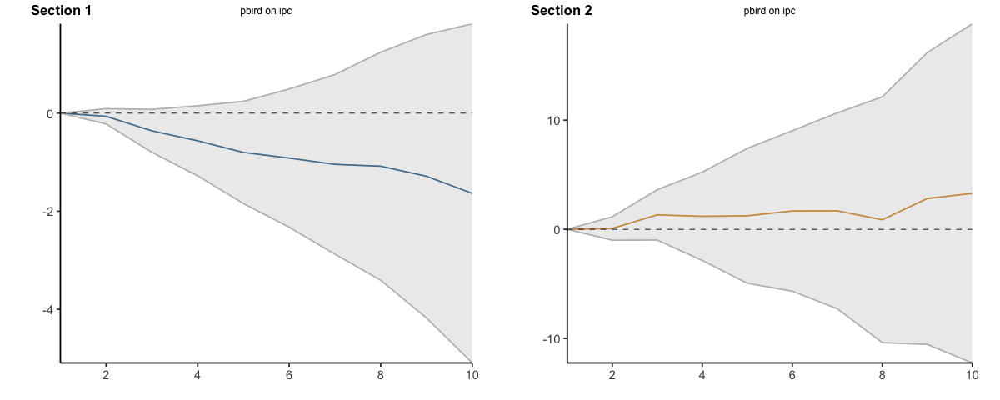

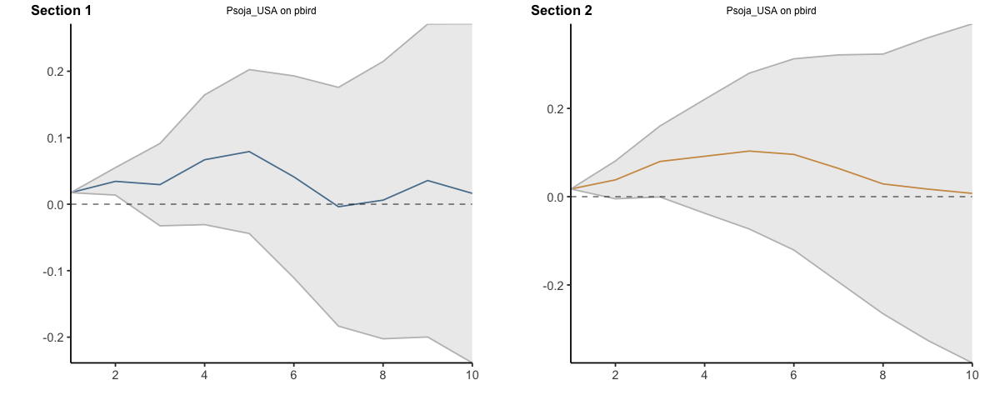

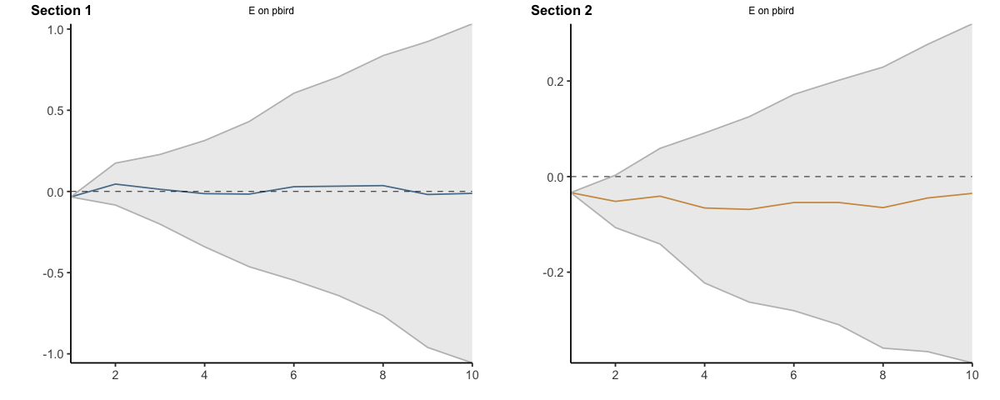

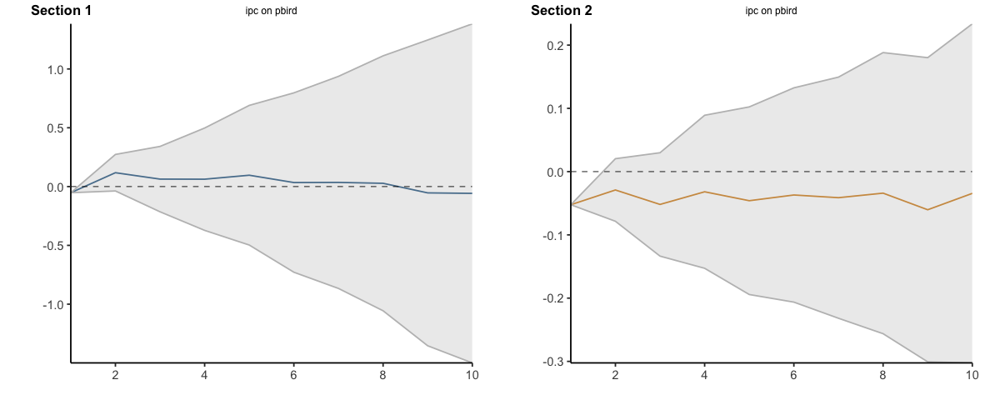

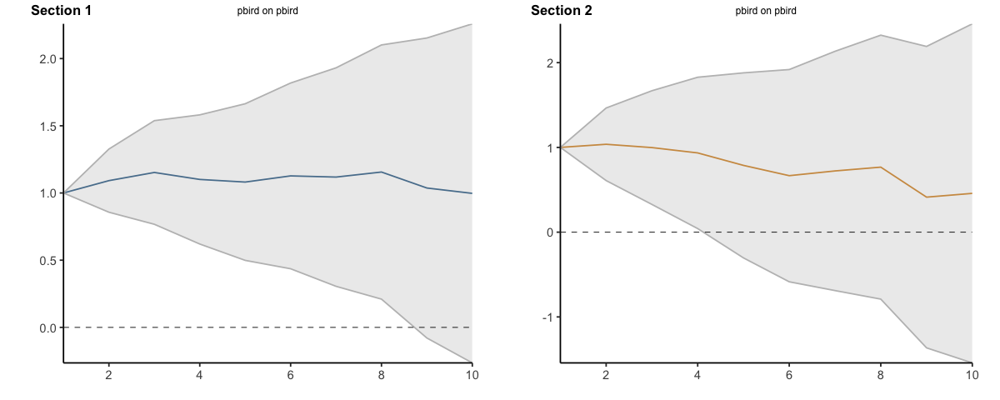

In [8]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 2, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.6, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.1946091,-0.1946091,-0.19460906,-0.19460906,-0.1946091,-0.19460906
2,2,-0.4030290,-0.5501023,-0.25595570,-0.38849947,-0.5426089,-0.23439007
3,3,-0.4536399,-0.7409116,-0.16636817,-0.58788048,-1.2701073,0.09434636
4,4,-0.4480023,-0.8507812,-0.04522343,-0.65691680,-1.6191852,0.30535165
5,5,-0.3263970,-0.8545727,0.20177879,-0.44262774,-2.0465653,1.16130978
6,6,-0.4387649,-1.2586351,0.38110535,-0.26652411,-2.4471234,1.91407521
7,7,-0.5919286,-1.6802087,0.49635143,-0.02808319,-2.6693233,2.61315689
8,8,-0.6237872,-2.1112051,0.86363078,0.41248026,-2.5350732,3.36003374
9,9,-0.6095572,-2.4109181,1.19180365,0.89323048,-2.5655076,4.35196855


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.028387373,-0.02838737,-0.02838737,-0.028387373,-0.02838737,-0.02838737
13,2,-0.002229777,-0.02055537,0.01609582,-0.041100532,-0.17116964,0.08896858
14,3,0.020975531,-0.03388903,0.07584009,-0.287654656,-0.62236943,0.04706012
15,4,0.033080450,-0.05401882,0.12017972,-0.386748886,-0.94806478,0.17456701
16,5,0.045377323,-0.08427049,0.17502514,-0.144466808,-1.13472559,0.84579198
17,6,0.035080963,-0.15485305,0.22501498,0.001310009,-1.47479039,1.47741041
18,7,0.025053598,-0.23867121,0.28877841,0.316629209,-1.51661614,2.14987455
19,8,-0.100654131,-0.54693081,0.34562255,0.686247007,-1.54447701,2.91697103
20,9,-0.162280999,-0.81043599,0.48587399,0.862717049,-1.70787331,3.43330740


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.00000000,0.00000000,0.000000,0.000000
112,2,-0.7987768,-1.656900,0.05934670,-0.52162191,-1.625860,0.582616
113,3,-2.2209184,-4.483966,0.04212904,0.11647502,-1.733625,1.966575
114,4,-2.9662090,-6.262701,0.33028279,-0.14955543,-3.424939,3.125828
115,5,-3.5309195,-7.594185,0.53234644,-0.05487953,-4.840776,4.731017
116,6,-2.5977210,-7.871440,2.67599808,0.88506601,-5.061153,6.831285
117,7,-2.7441014,-8.939915,3.45171184,0.43925596,-6.929775,7.808286
118,8,-2.9738582,-10.675800,4.72808375,0.55800855,-7.650559,8.766576
119,9,-3.9902623,-12.670685,4.69016011,2.42007930,-7.831933,12.672091


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000
123,2,-0.04921724,-0.2956643,0.1972299,0.2205836,-0.3526189,0.7937861
124,3,-0.44345109,-0.9897227,0.1028205,0.9282214,-0.2868532,2.1432960
125,4,-0.71079974,-1.6134881,0.1918886,1.0435723,-1.1722650,3.2594097
126,5,-0.85863524,-2.1858974,0.4686269,1.2602788,-2.1299513,4.6505089
127,6,-0.86449167,-2.6596431,0.9306598,1.7511373,-2.3776703,5.8799449
128,7,-0.92703652,-3.2767146,1.4226416,1.9625989,-3.1111612,7.0363590
129,8,-0.89841110,-3.8834697,2.0866475,1.9194850,-4.2850545,8.1240245
130,9,-1.05023411,-4.8723007,2.7718324,3.3716923,-4.3727822,11.1161669


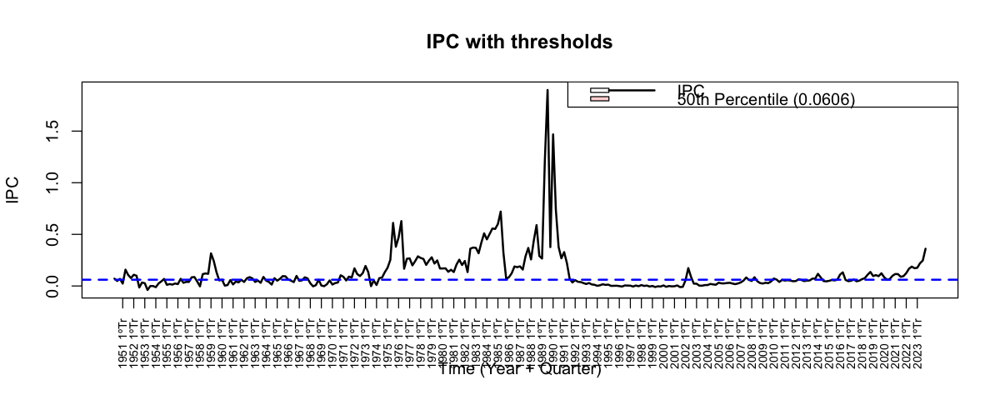

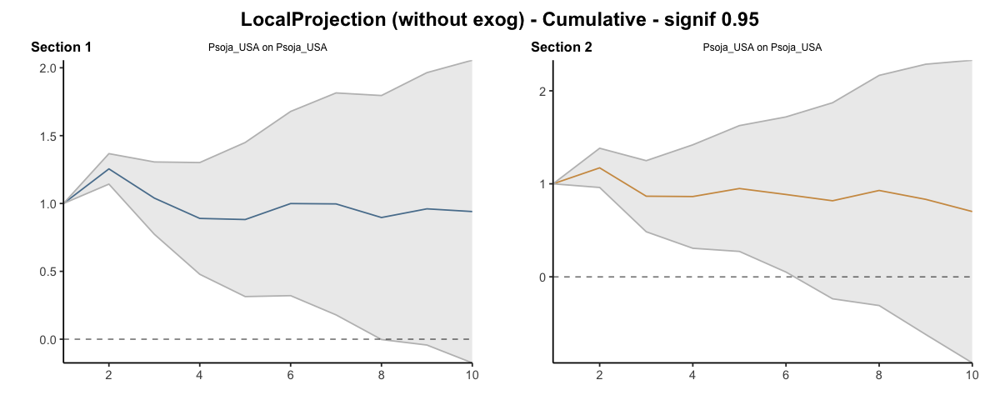

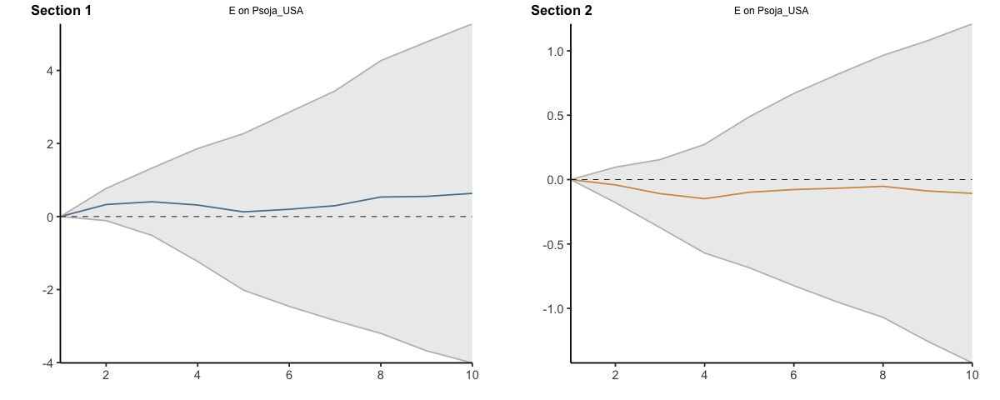

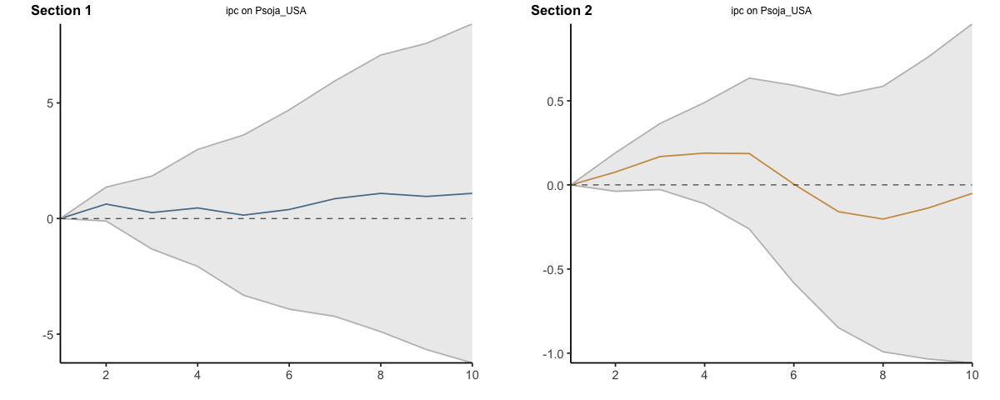

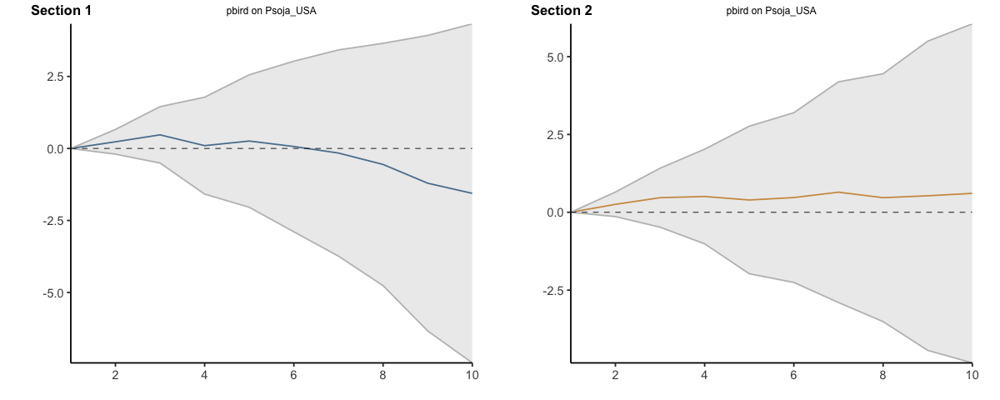

...

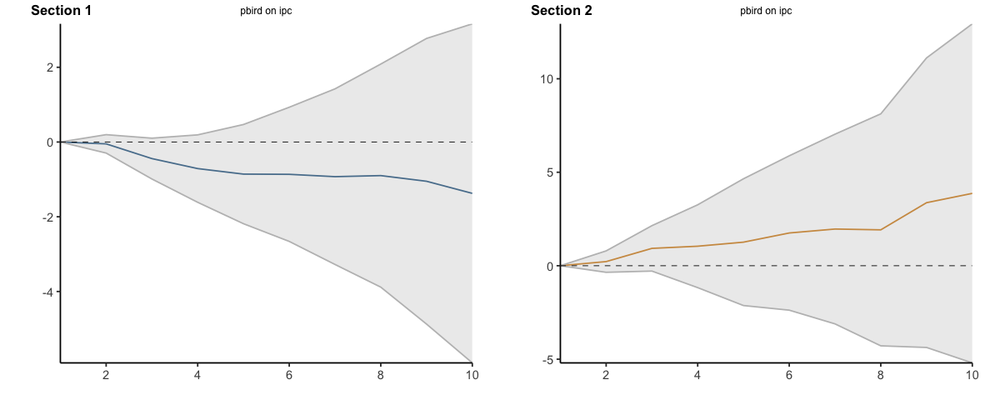

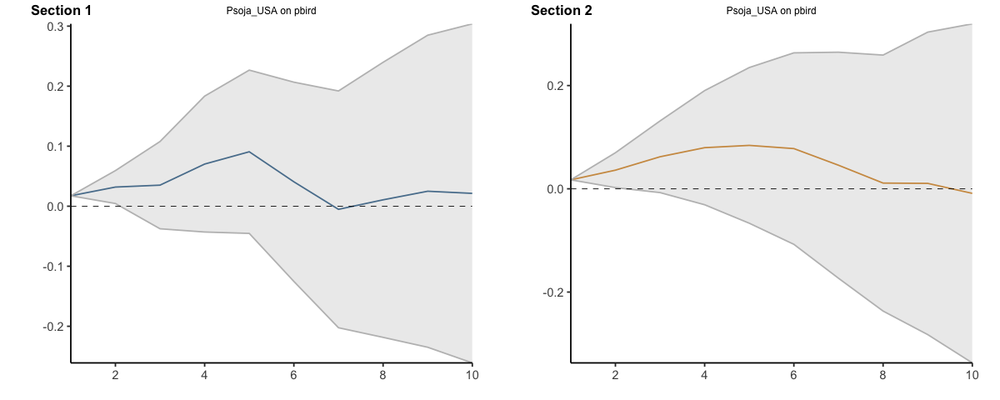

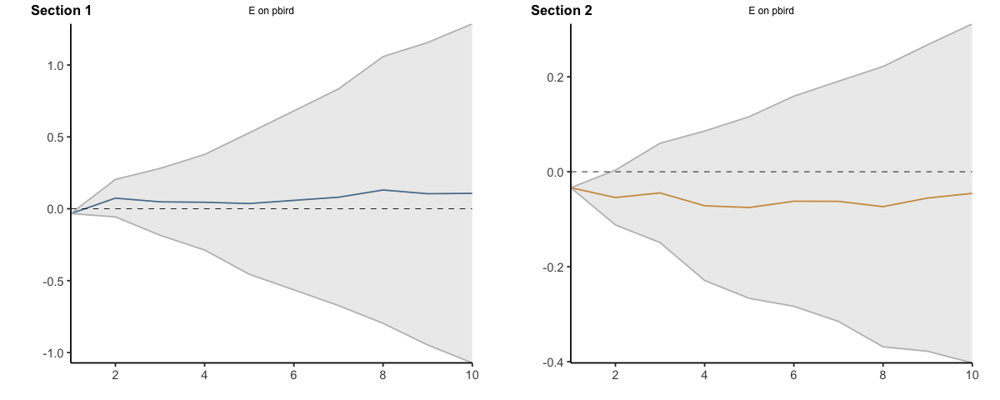

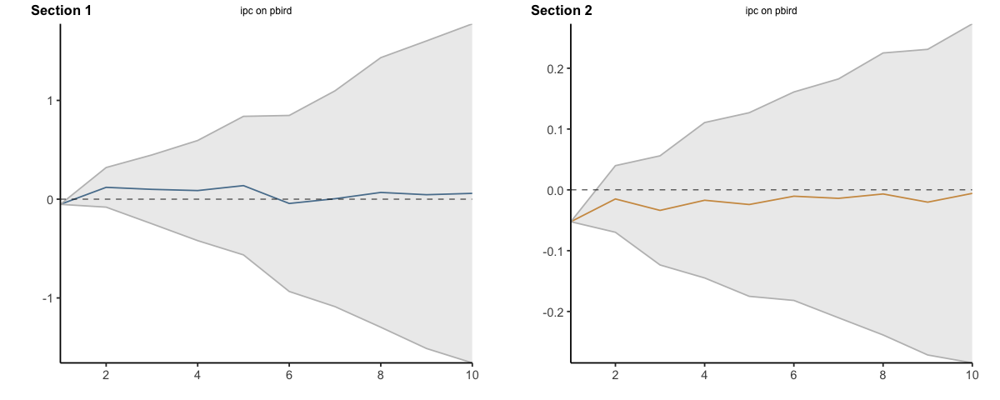

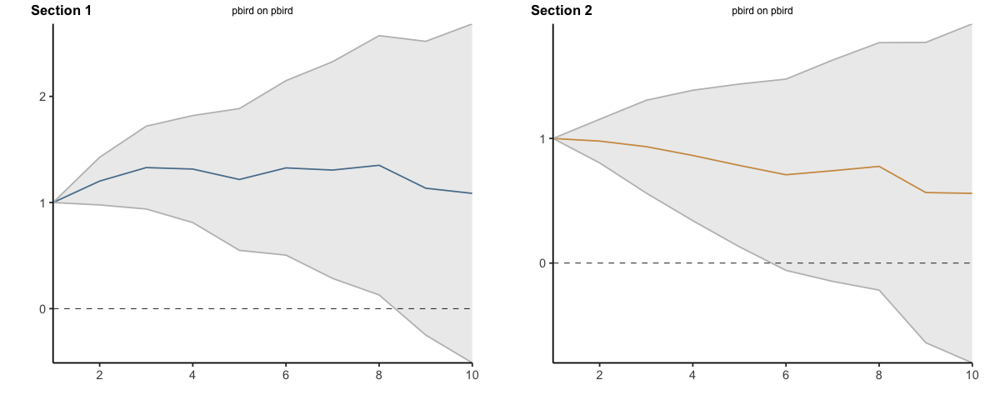

In [9]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 2, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.5, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.19460906,-0.1946091,-0.19460906,-0.1946091,-0.1946091,-0.1946091
2,2,-0.38194811,-0.5441151,-0.21978109,-0.3824023,-0.5303822,-0.2344224
3,3,-0.42104799,-0.7635723,-0.07852372,-0.5805799,-1.1903198,0.0291601
4,4,-0.41511368,-0.8807590,0.05053167,-0.6869479,-1.5447596,0.1708639
5,5,-0.35096549,-0.9437998,0.24186887,-0.4818816,-1.9056170,0.9418538
6,6,-0.33020511,-1.1441985,0.48378827,-0.4486096,-2.4590734,1.5618541
7,7,-0.38646149,-1.3487339,0.57581095,-0.2998684,-2.7919277,2.1921910
8,8,-0.22347061,-1.4046274,0.95768621,-0.0204891,-2.8039544,2.7629762
9,9,-0.09020261,-1.4007957,1.22039052,0.3423665,-2.8903884,3.5751214


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.028387373,-0.02838737,-0.02838737,-0.02838737,-0.02838737,-0.02838737
13,2,0.008564871,-0.02051847,0.03764821,-0.03875647,-0.15072018,0.07320724
14,3,0.040922206,-0.02876624,0.11061066,-0.26943334,-0.54890245,0.01003578
15,4,0.068835403,-0.03497284,0.17264365,-0.39815954,-0.89021558,0.09389650
16,5,0.099571400,-0.05335382,0.25249662,-0.20658809,-1.06295065,0.64977447
17,6,0.107866908,-0.10820021,0.32393403,-0.11319267,-1.40990850,1.18352316
18,7,0.127216502,-0.19052967,0.44496268,0.12448723,-1.49417638,1.74315084
19,8,0.117146300,-0.28750074,0.52179333,0.37441836,-1.65980873,2.40864546
20,9,0.152047989,-0.34668332,0.65077930,0.47149379,-1.89906131,2.84204890


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.0000000,0.00000000,0.000000,0.0000000
112,2,-0.6650413,-1.582434,0.2523518,-0.63546751,-1.683450,0.4125149
113,3,-1.7966863,-4.147732,0.5543596,-0.35159630,-2.080326,1.3771332
114,4,-2.5224760,-6.119219,1.0742675,-0.64376095,-3.700928,2.4134060
115,5,-3.0046481,-7.385158,1.3758616,-0.75101549,-5.147438,3.6454072
116,6,-2.3245003,-7.994689,3.3456888,0.19198530,-5.247402,5.6313725
117,7,-2.7599342,-9.468201,3.9483328,-0.06482907,-6.787256,6.6575974
118,8,-3.2801221,-11.563372,5.0031283,0.14473133,-7.334891,7.6243539
119,9,-4.5001742,-13.873827,4.8734787,1.71926886,-7.390645,10.8291827


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000
123,2,0.09454746,-0.1230737,0.3121686,0.2152986,-0.2707423,0.7013395
124,3,-0.21769358,-0.7926678,0.3572807,0.6937814,-0.2761230,1.6636858
125,4,-0.44815757,-1.3873793,0.4910642,0.7793691,-1.1191353,2.6778735
126,5,-0.63205236,-2.0260452,0.7619405,0.9512095,-1.9764616,3.8788805
127,6,-0.61239555,-2.4698985,1.2451074,1.3147175,-2.2938220,4.9232570
128,7,-0.78267707,-3.1863574,1.6210032,1.4825775,-2.9568425,5.9219976
129,8,-1.04072267,-4.0564346,1.9749893,1.5847717,-3.8802190,7.0497625
130,9,-1.25500568,-5.1644534,2.6544420,2.8166786,-3.9014052,9.5347624


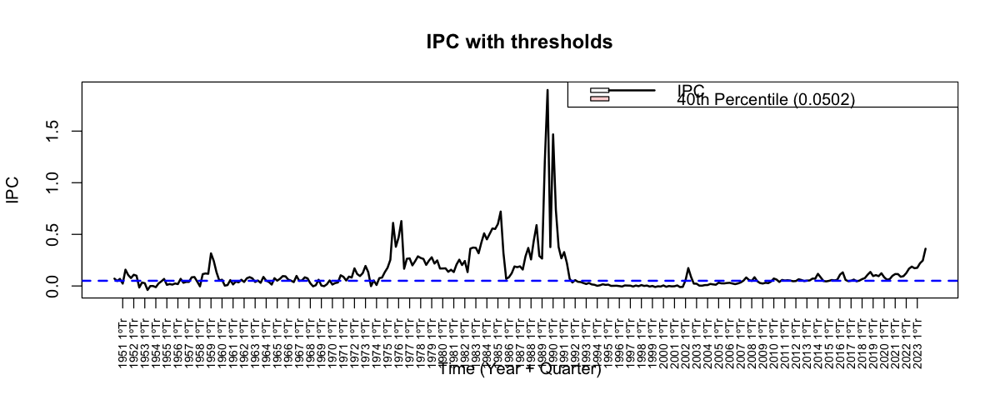

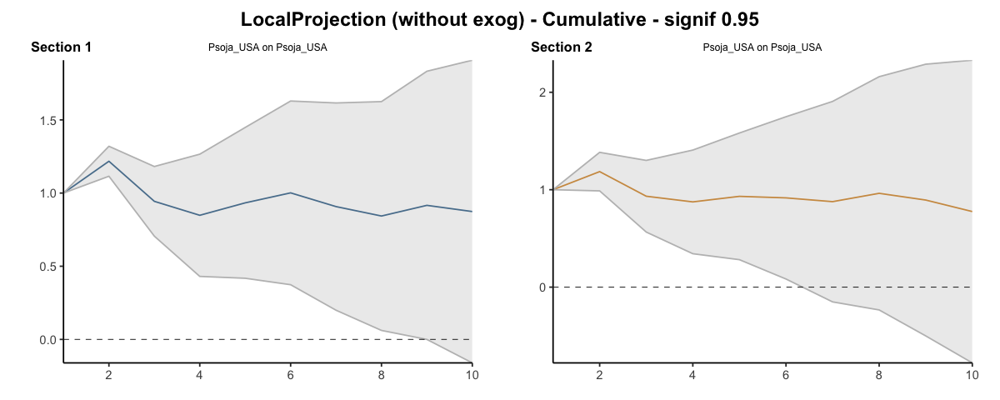

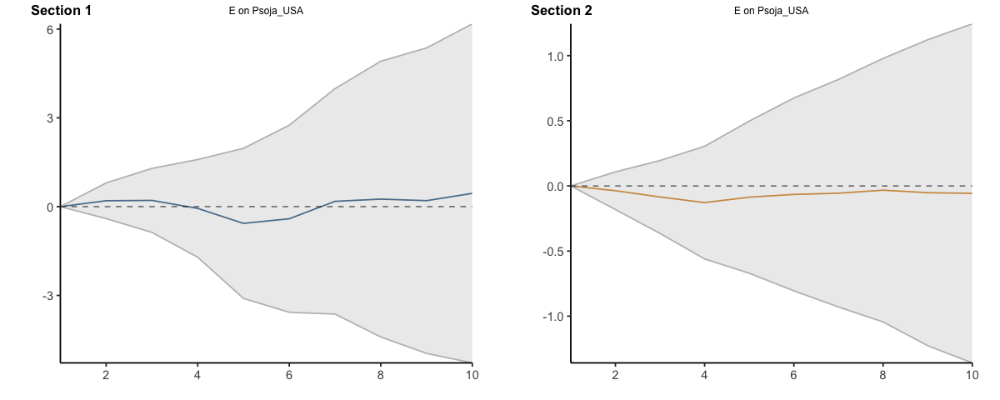

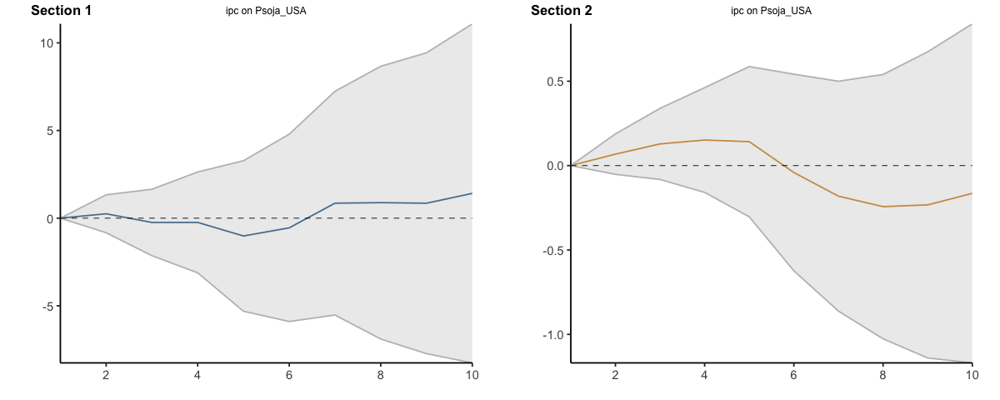

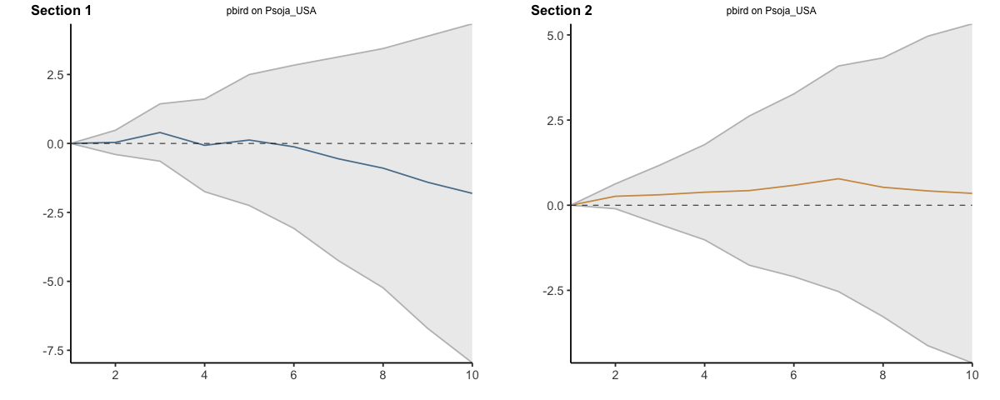

...

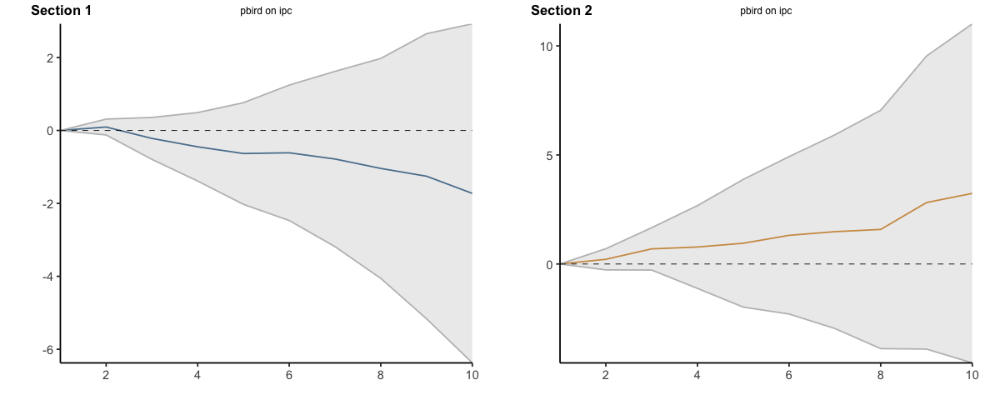

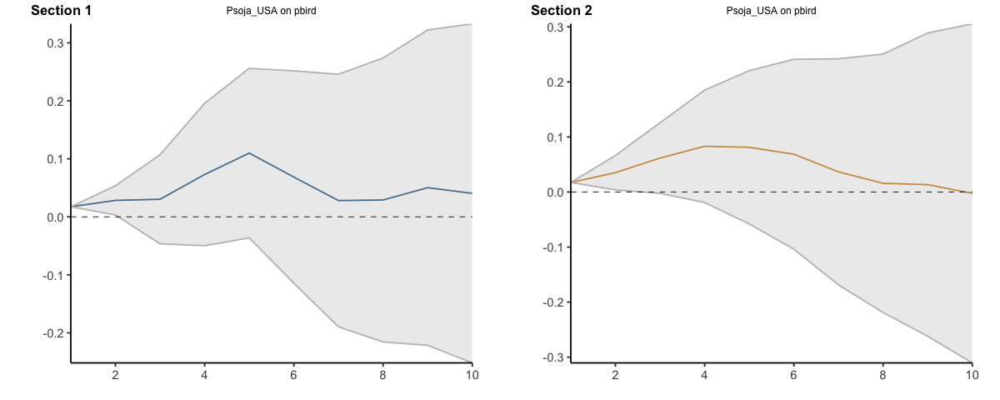

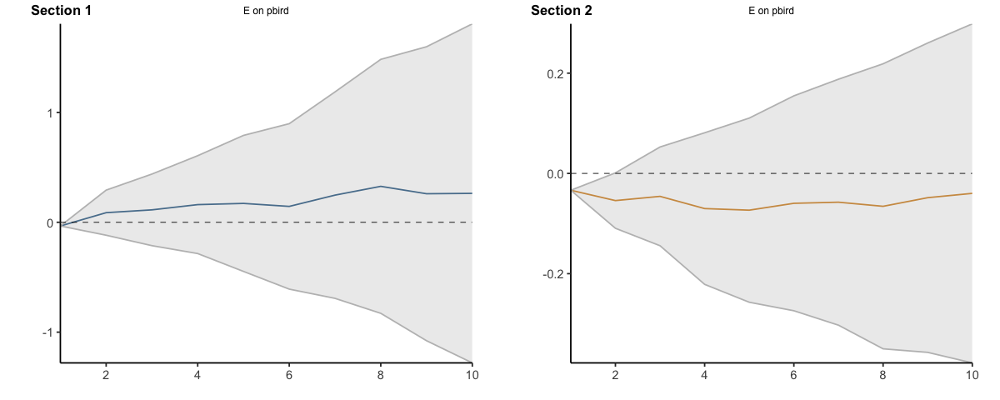

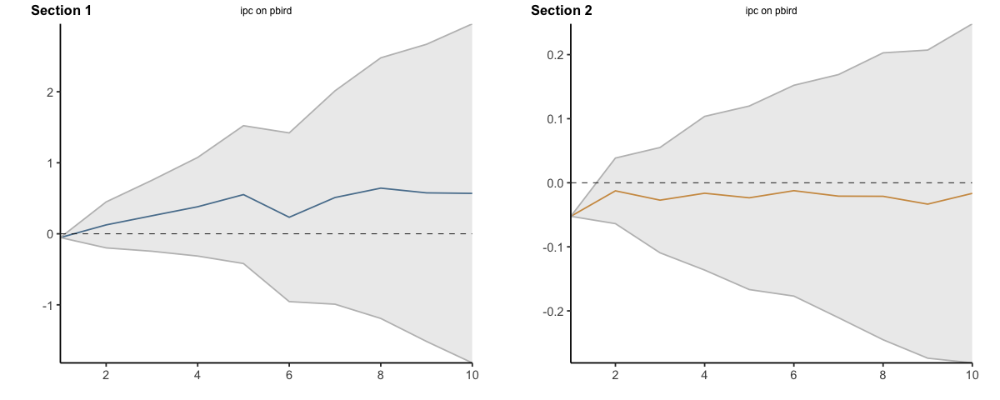

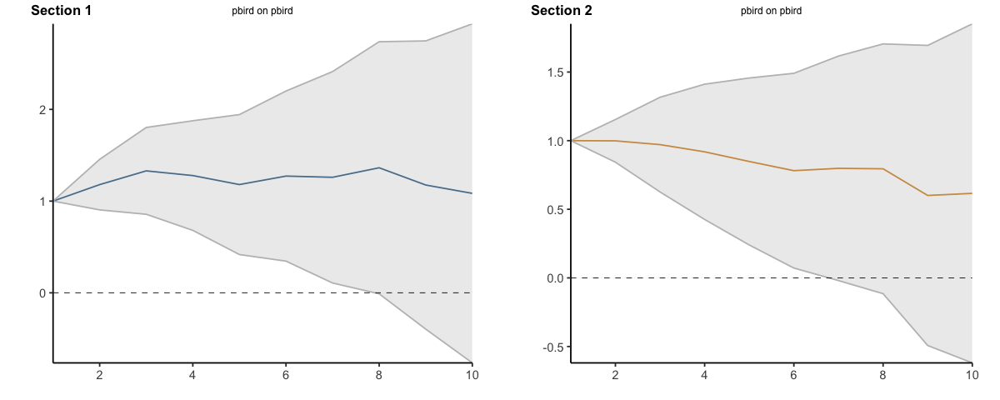

In [10]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 2, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.4, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.2031619,-0.2031619,-0.20316193,-0.2031619,-0.2031619,-0.203161932
2,2,-0.5054087,-0.6000980,-0.41071937,-0.3225011,-0.6435403,-0.001461912
3,3,-0.5169573,-0.8310243,-0.20289029,-0.5948227,-1.4777461,0.288100639
4,4,-0.6357022,-1.0779623,-0.19344211,-0.2863767,-1.8176150,1.244861582
5,5,-0.6623650,-1.2800057,-0.04472440,0.7964255,-2.1486494,3.741500352
6,6,-0.7517063,-1.5453430,0.04193045,1.8827092,-2.3077647,6.073183173
7,7,-0.8437578,-1.8360337,0.14851800,2.9816156,-2.2814839,8.244715104
8,8,-0.6572751,-1.8474765,0.53292636,3.7103096,-2.3647346,9.785353746
9,9,-0.5048788,-1.9053024,0.89554467,4.5260087,-2.3643024,11.416319765


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.02370532,-0.02370532,-0.023705316,-0.023705316,-0.02370532,-0.02370532
13,2,-0.05032992,-0.09734897,-0.003310877,-0.008002339,-0.31046435,0.29445967
14,3,-0.12862814,-0.20877831,-0.048477962,-0.098201525,-0.65463152,0.45822847
15,4,-0.17904624,-0.31605415,-0.042038333,0.067119397,-0.81372713,0.94796592
16,5,-0.14667116,-0.39052963,0.097187310,0.936065020,-1.01286000,2.88499004
17,6,-0.25338931,-0.56339734,0.056618713,1.862994974,-1.10686860,4.83285854
18,7,-0.22833198,-0.61975307,0.163089107,2.883942318,-0.99719376,6.76507839
19,8,-0.21162872,-0.71913789,0.295880449,3.835009376,-0.90255681,8.57257557
20,9,-0.25784649,-0.88734972,0.371656739,4.365219973,-1.25242814,9.98286809


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.0000000,0.0000000,0.000000,0.000000
112,2,-0.8382338,-1.645845,-0.0306231,-0.7662315,-3.399384,1.866921
113,3,-1.5912654,-3.286638,0.1041077,-0.1555492,-5.654143,5.343045
114,4,-1.9392802,-4.343648,0.4650876,-3.6413570,-14.123221,6.840507
115,5,-2.1788575,-5.179824,0.8221086,-6.0834630,-22.201517,10.034591
116,6,-1.5866259,-5.337370,2.1641185,-6.8435729,-26.552055,12.864909
117,7,-1.6532694,-6.136185,2.8296462,-11.0442728,-35.366484,13.277939
118,8,-1.9518543,-7.251983,3.3482742,-12.5856999,-39.408163,14.236763
119,9,-1.8924866,-8.068920,4.2839468,-9.9179410,-39.360099,19.524217


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.000000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
123,2,0.024868309,-0.1639373,0.2136739,-0.3295540,-2.435012,1.775904
124,3,-0.083905247,-0.5630532,0.3952427,0.7449447,-3.212415,4.702304
125,4,-0.142819188,-0.9225259,0.6368875,-1.3152625,-8.542950,5.912425
126,5,-0.239626683,-1.3288361,0.8495827,-2.9564630,-15.249070,9.336144
127,6,-0.153140519,-1.6087042,1.3024231,-4.1995459,-19.488099,11.089008
128,7,-0.158832663,-2.0101761,1.6925108,-6.5842108,-24.875495,11.707073
129,8,-0.178762151,-2.4755941,2.1180698,-9.3653567,-31.748934,13.018221
130,9,-0.001353373,-2.8354046,2.8326979,-6.8953949,-31.899963,18.109174


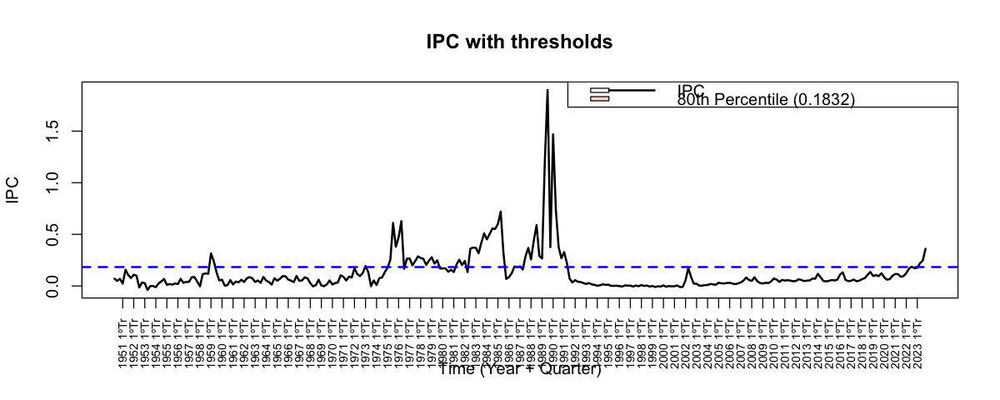

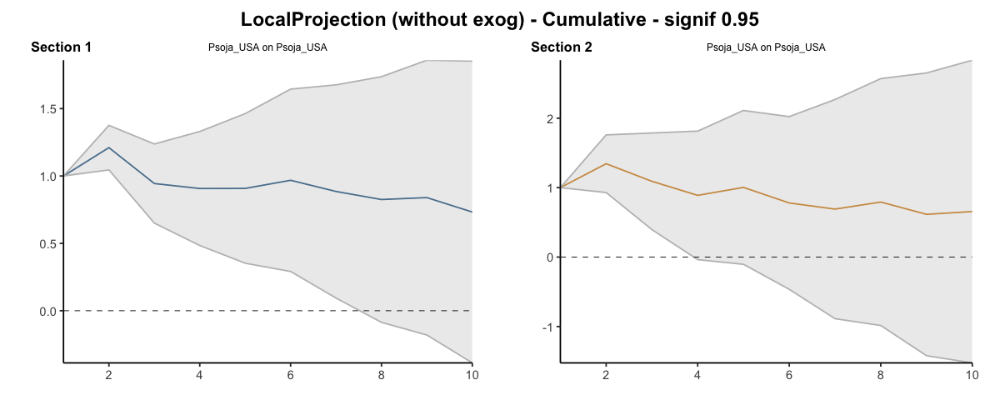

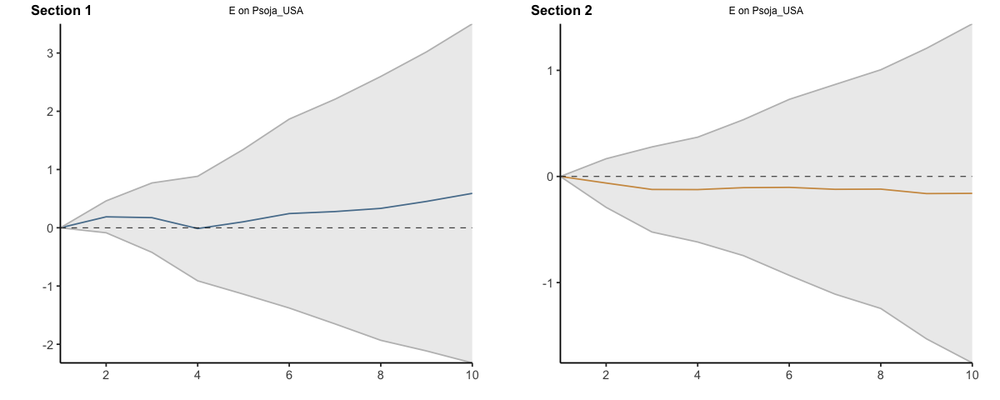

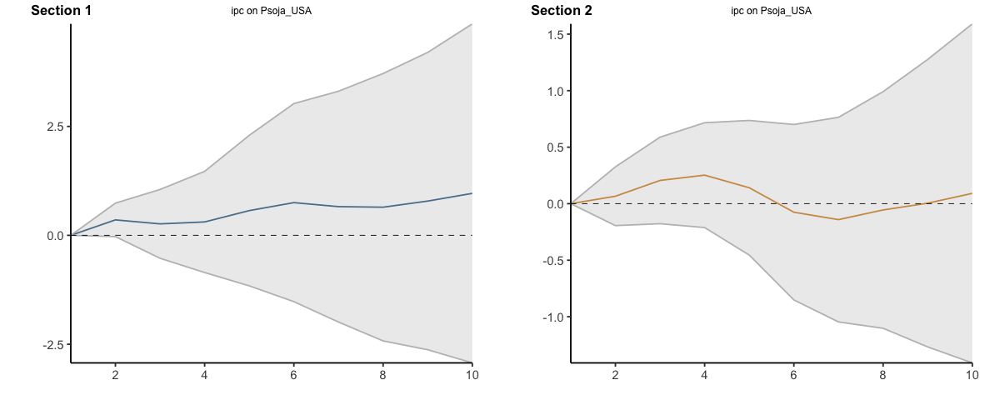

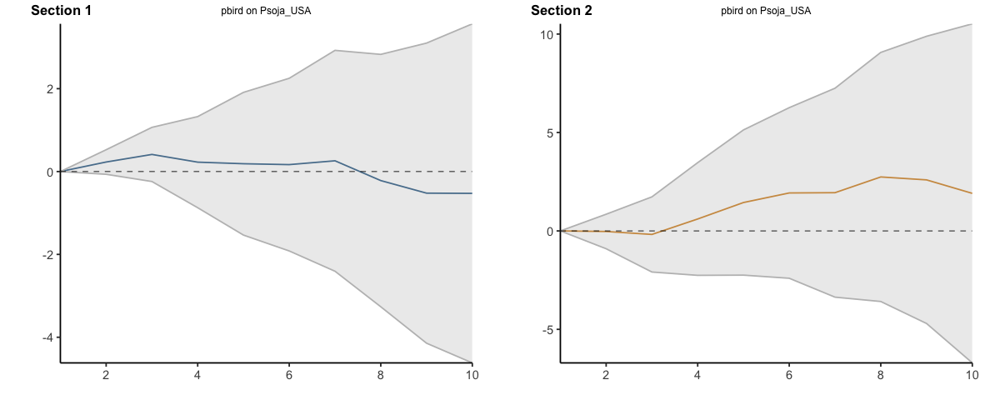

...

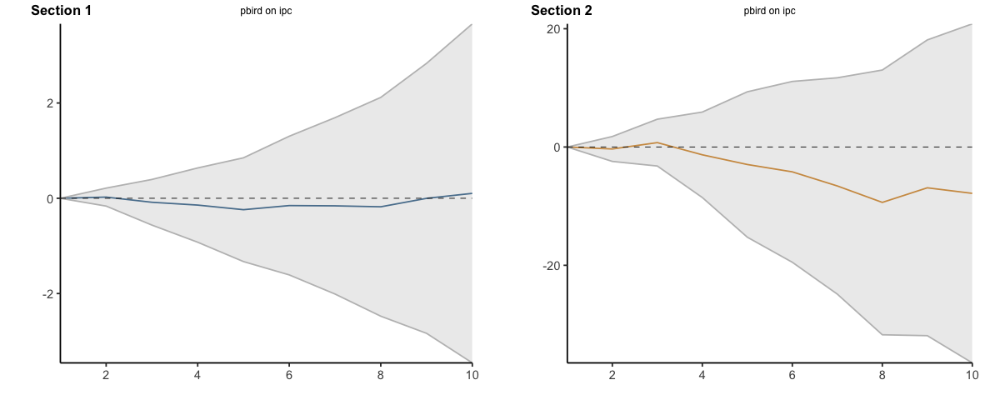

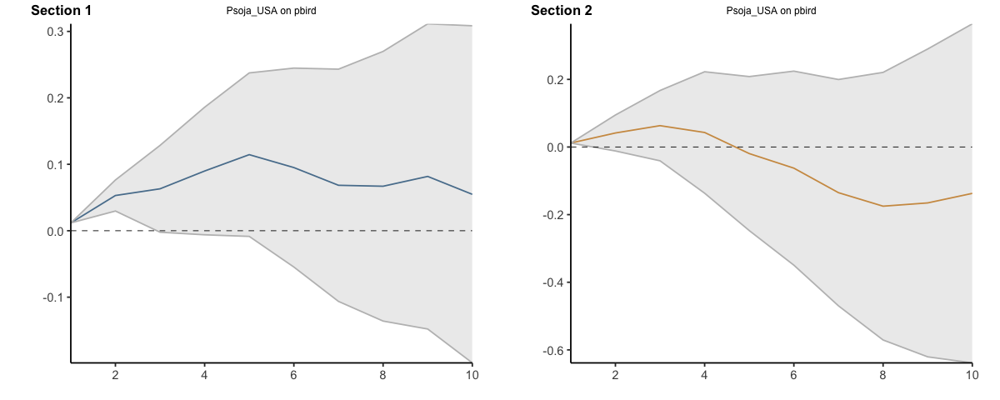

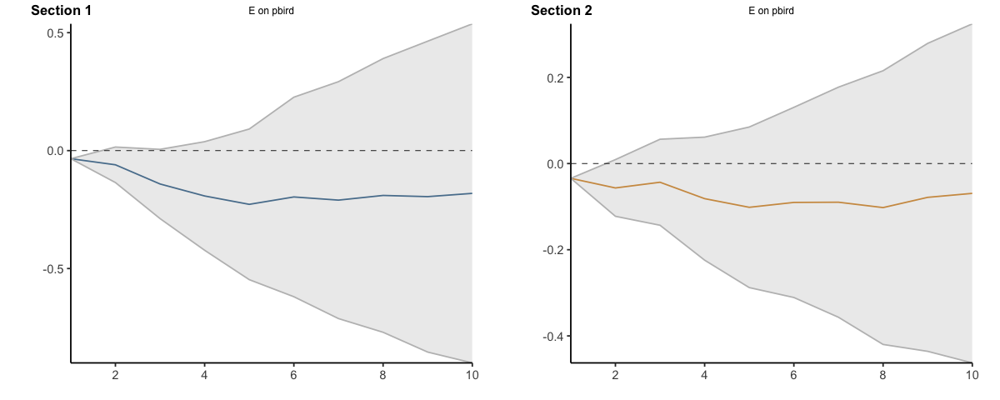

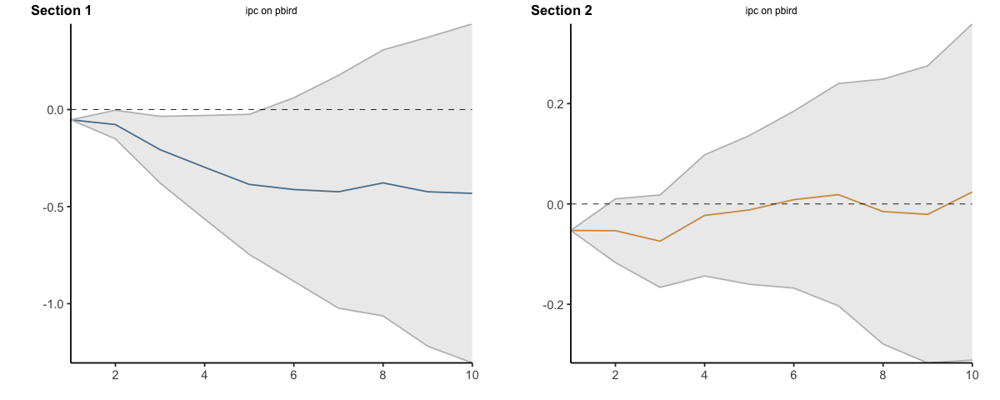

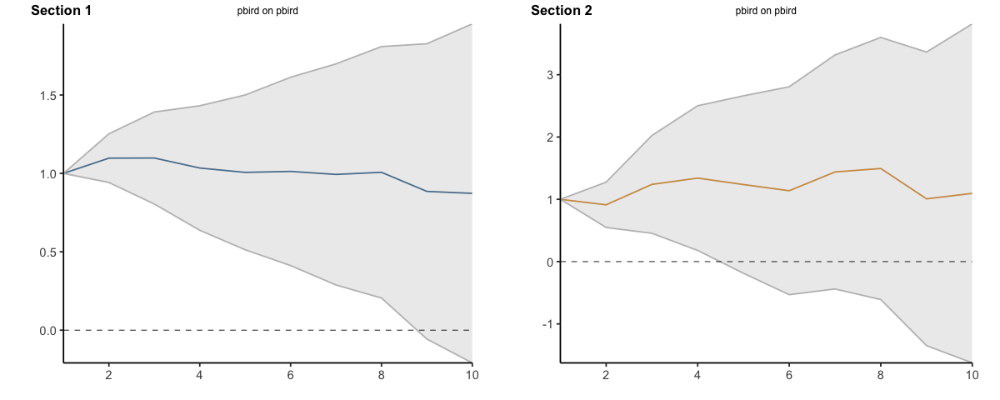

In [11]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.8, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.203161932,-0.2031619,-0.2031619,-0.2031619,-0.2031619,-0.20316193
2,2,-0.421877077,-0.5199427,-0.3238115,-0.2373330,-0.5372104,0.06254444
3,3,-0.278783566,-0.7124163,0.1548491,-0.5282303,-1.2276471,0.17118644
4,4,-0.294421334,-0.8406422,0.2517995,-0.4043345,-1.7153889,0.90671980
5,5,-0.204483949,-0.9387665,0.5297986,0.1932552,-2.2439426,2.63045297
6,6,-0.227720027,-1.1379638,0.6825237,0.7543403,-2.6792204,4.18790093
7,7,-0.256857958,-1.3395017,0.8257858,1.4146489,-3.0118684,5.84116608
8,8,-0.105863224,-1.3848192,1.1730928,2.1485398,-2.8260580,7.12313770
9,9,-0.020529999,-1.4964881,1.4554282,2.9552662,-2.7489351,8.65946737


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.0237053165,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532
13,2,0.0006910667,-0.03085159,0.03223373,0.04848698,-0.15868904,0.25566299
14,3,0.0355715561,-0.04336485,0.11450797,-0.11091933,-0.50992383,0.28808518
15,4,0.0900451814,-0.04973469,0.22982505,-0.08242744,-0.84093432,0.67607943
16,5,0.2280505334,-0.07425446,0.53035552,0.44000273,-1.18432619,2.06433166
17,6,0.2322149502,-0.14357010,0.60800000,0.93593993,-1.47896545,3.35084530
18,7,0.3204273876,-0.16121530,0.80207008,1.54413151,-1.62689813,4.71516116
19,8,0.4072593245,-0.19715039,1.01166904,2.21184747,-1.68957598,6.11327092
20,9,0.3762992855,-0.38852497,1.14112354,2.62962740,-1.87826483,7.13751963


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.00000000,0.0000000,0.000000,0.000000
112,2,-0.7128816,-1.349397,-0.07636620,-0.9855123,-3.492883,1.521859
113,3,-1.7106664,-3.313059,-0.10827333,0.2909120,-3.902819,4.484643
114,4,-2.2242053,-4.517940,0.06952986,-1.0871687,-8.518434,6.344096
115,5,-2.4301050,-5.286932,0.42672158,-2.0847691,-12.943490,8.773952
116,6,-1.8938164,-5.668934,1.88130088,-1.9676748,-15.139793,11.204443
117,7,-1.9127614,-6.255919,2.43039605,-5.2857790,-21.830592,11.259034
118,8,-2.1563361,-7.423147,3.11047463,-6.2099937,-24.382577,11.962590
119,9,-2.7636148,-8.814951,3.28772138,-2.9790483,-25.737341,19.779244


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
123,2,-0.01608947,-0.1668186,0.1346397,0.3830337,-0.901939,1.668006
124,3,-0.25069142,-0.6887647,0.1873818,1.5527863,-1.159318,4.264891
125,4,-0.44937781,-1.1574171,0.2586614,1.0831705,-3.832872,5.999213
126,5,-0.61018644,-1.6114409,0.3910681,0.6830570,-7.399191,8.765305
127,6,-0.69171193,-2.0420432,0.6586194,0.6599312,-9.366493,10.686355
128,7,-0.72926901,-2.4287259,0.9701879,-0.9618085,-13.322615,11.398998
129,8,-0.68639167,-2.7719120,1.3991287,-2.6921544,-17.178888,11.794579
130,9,-0.74799149,-3.3578761,1.8618931,-0.7181079,-18.467130,17.030914


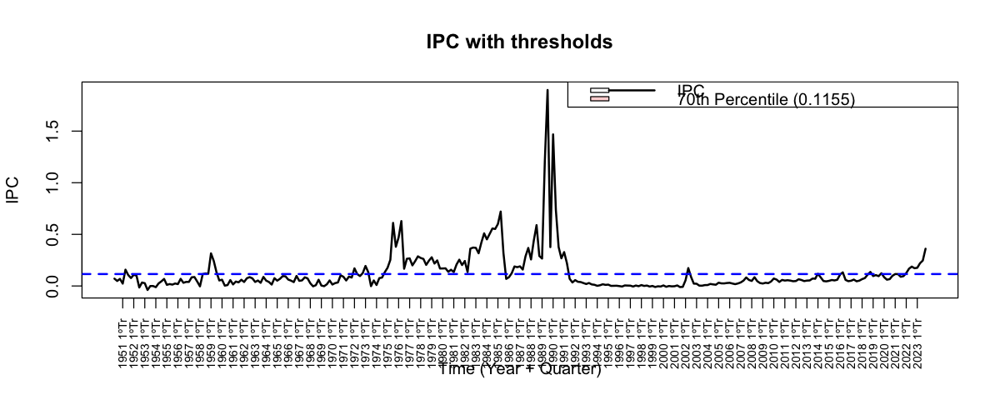

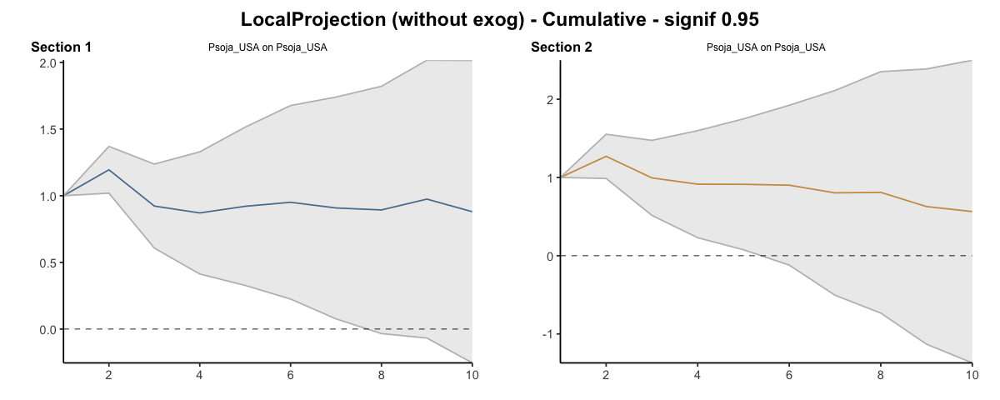

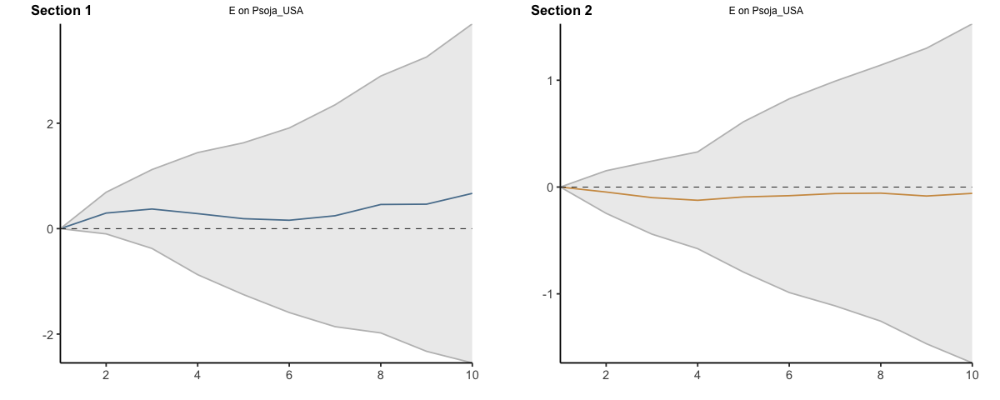

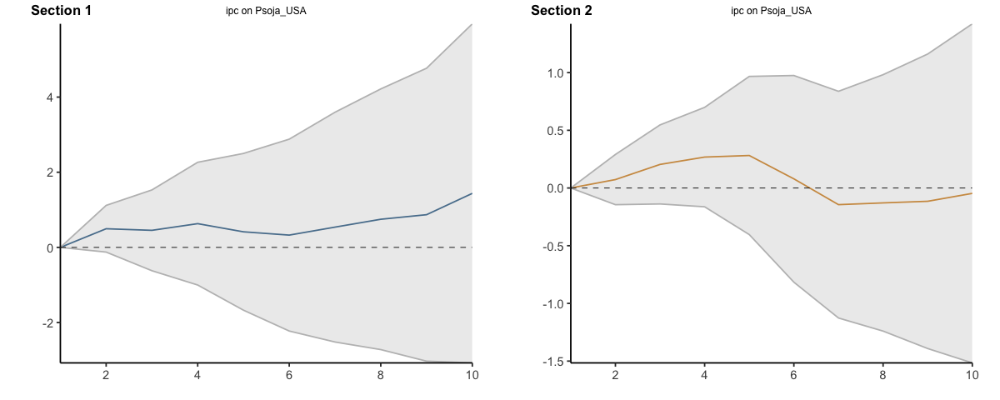

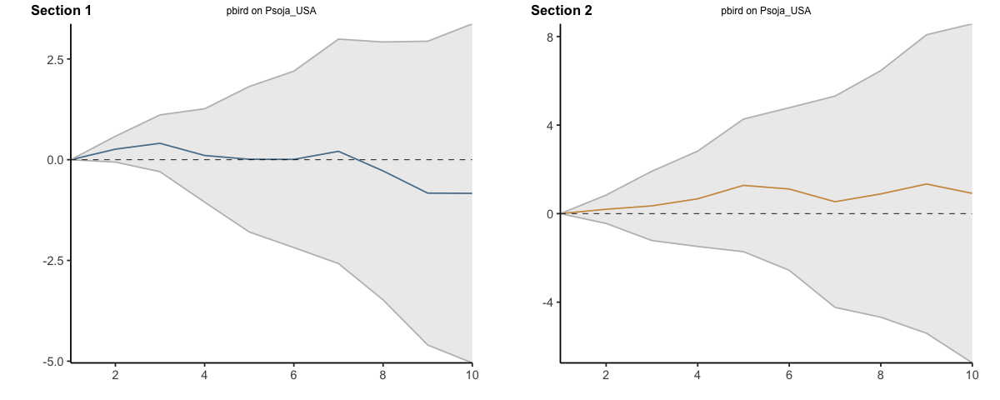

...

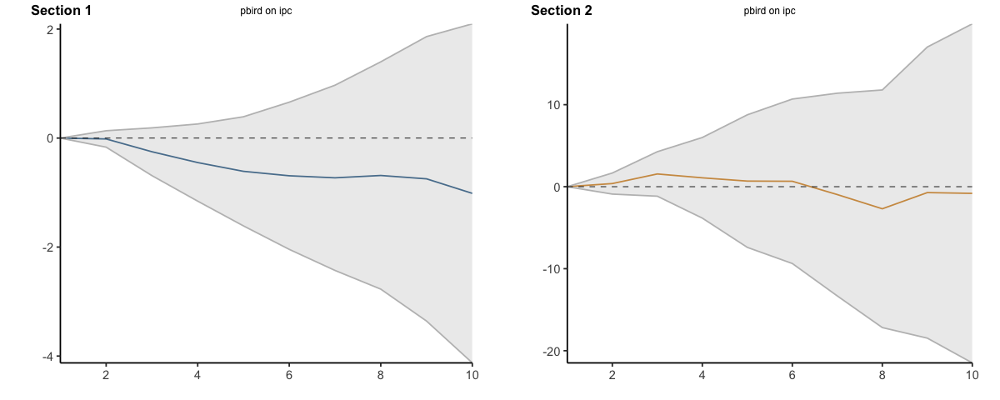

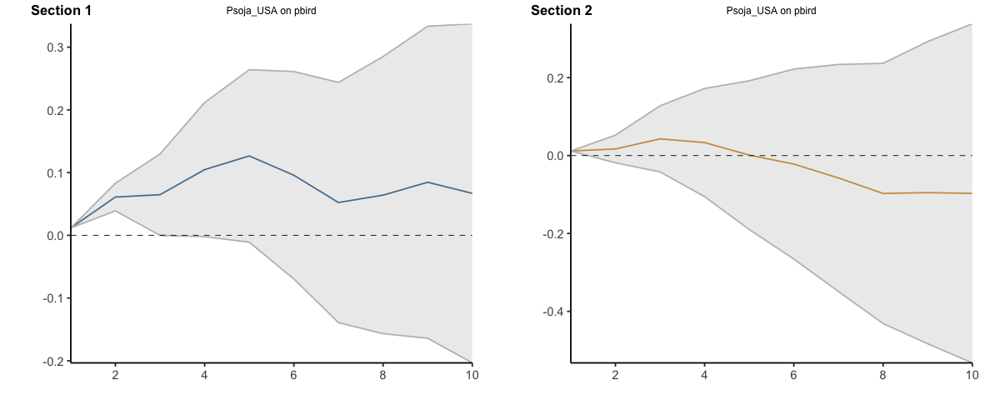

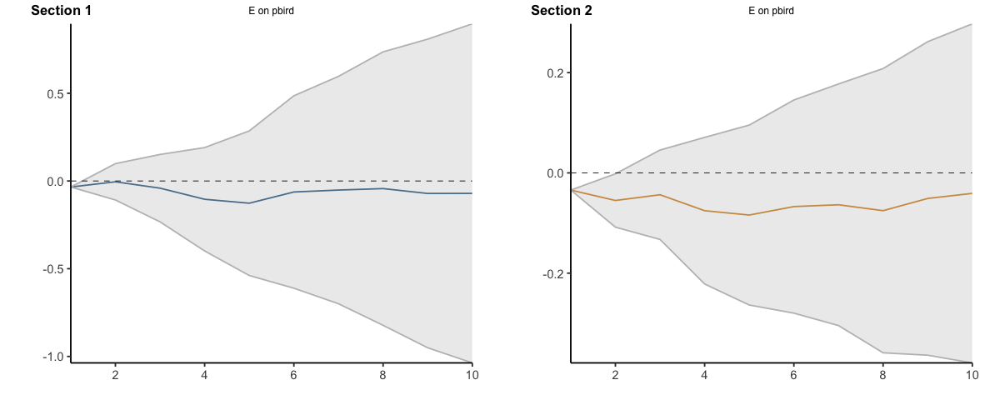

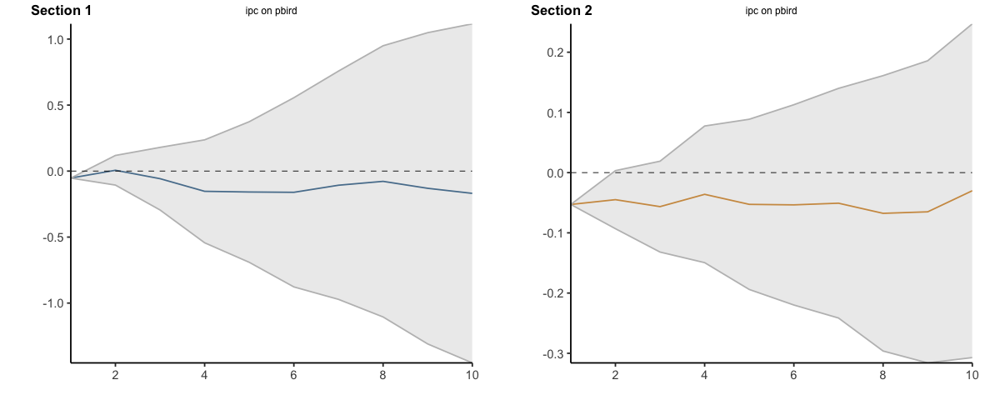

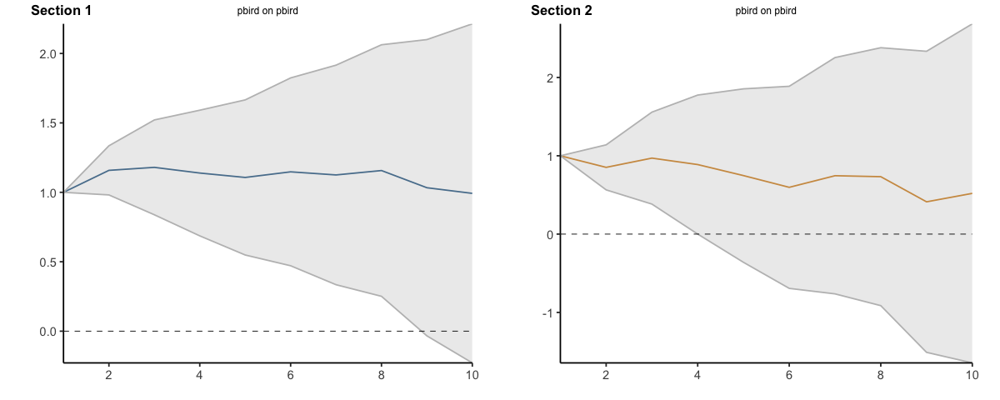

In [12]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.203161932,-0.2031619,-0.20316193,-0.2031619,-0.2031619,-0.2031619
2,2,-0.443921757,-0.5014092,-0.38643429,-0.3307426,-0.4637939,-0.1976914
3,3,-0.298615176,-0.5341080,-0.06312232,-0.6341037,-0.9094291,-0.3587782
4,4,-0.330189618,-0.6195406,-0.04083867,-0.5923189,-1.0850926,-0.0995452
5,5,-0.241970134,-0.6285665,0.14462622,-0.1612046,-1.1060684,0.7836592
6,6,-0.252026192,-0.7242404,0.22018806,0.2316308,-1.1203401,1.5836017
7,7,-0.296102566,-0.8572363,0.26503112,0.6580858,-1.0497197,2.3658913
8,8,-0.156705730,-0.8142477,0.50083626,1.1520867,-0.7922141,3.0963874
9,9,-0.066339721,-0.8232020,0.69052259,1.7838486,-0.4880981,4.0557954


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.0237053165,-0.02370532,-0.02370532,-0.023705316,-0.02370532,-0.02370532
13,2,0.0009762219,-0.01226947,0.01422191,-0.009529632,-0.08587608,0.06681681
14,3,0.0219590457,-0.01210700,0.05602509,-0.175421724,-0.31812511,-0.03271834
15,4,0.0760194632,0.01854158,0.13349734,-0.229526461,-0.50025103,0.04119811
16,5,0.2063044733,0.07429928,0.33830966,0.151374409,-0.45881891,0.76156773
17,6,0.1858091169,0.03514352,0.33647472,0.519764705,-0.42685391,1.46638332
18,7,0.2375418467,0.04134099,0.43374271,0.971877065,-0.26102626,2.20478039
19,8,0.2904673809,0.04399728,0.53693748,1.442165395,-0.09493664,2.97926743
20,9,0.2368813766,-0.08385574,0.55761850,1.713972892,-0.07545739,3.50340317


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.000000000,0.000000000,0.000000,0.0000000
112,2,-0.6497387,-1.002429,-0.297047899,-1.204410709,-2.101554,-0.3072673
113,3,-1.7653471,-2.673418,-0.857275744,0.001109653,-1.514900,1.5171196
114,4,-2.3776902,-3.684195,-1.071185043,-0.842771213,-3.432664,1.7471217
115,5,-2.5955688,-4.209039,-0.982098416,-1.709521459,-5.747255,2.3282124
116,6,-2.0763589,-4.172276,0.019558095,-0.972995194,-5.891402,3.9454111
117,7,-2.2276200,-4.647701,0.192460579,-2.414303056,-8.579319,3.7507131
118,8,-2.6357095,-5.569370,0.297951352,-3.045716991,-9.867594,3.7761598
119,9,-3.3202004,-6.648385,0.007983962,-0.540226122,-8.878336,7.7978835


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.000000000,0.00000000,0.00000000,0.0000000
123,2,-0.07980645,-0.1623677,0.002754767,-0.04520018,-0.57449345,0.4840931
124,3,-0.36954629,-0.5902616,-0.148830944,1.08634147,0.03538794,2.1372950
125,4,-0.60548231,-0.9680066,-0.242958039,0.85699899,-0.98541463,2.6994126
126,5,-0.81826751,-1.3241278,-0.312407177,0.67776168,-2.34651167,3.7020350
127,6,-0.94496593,-1.6182053,-0.271726518,0.84010280,-2.88217214,4.5623777
128,7,-1.07860661,-1.9327592,-0.224454015,0.54076489,-4.00940385,5.0909336
129,8,-1.14716874,-2.2073347,-0.087002806,-0.52902326,-6.12844316,5.0703966
130,9,-1.34824518,-2.6708586,-0.025631722,1.28306174,-5.40547788,7.9716013


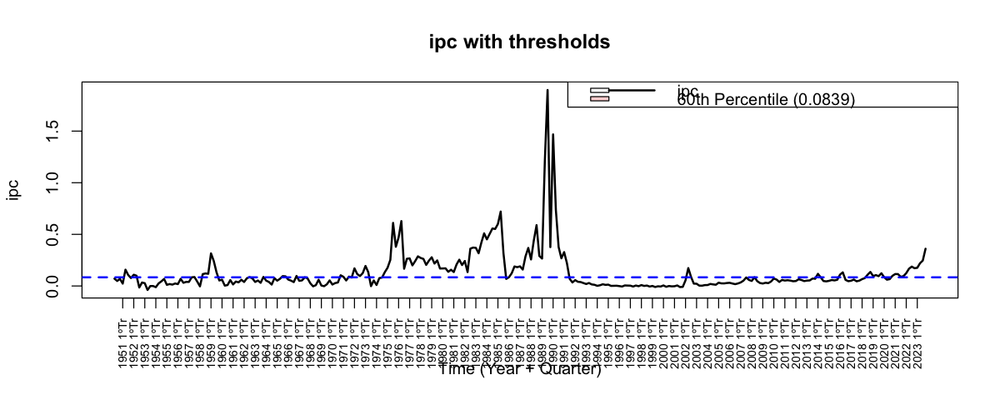

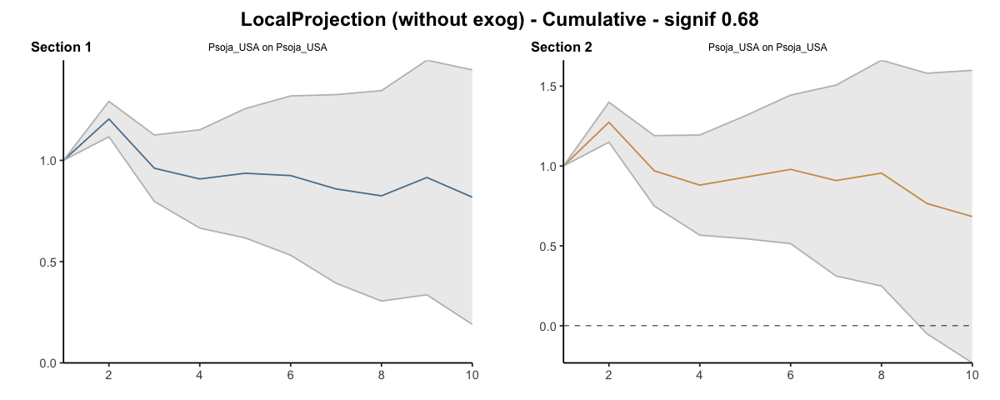

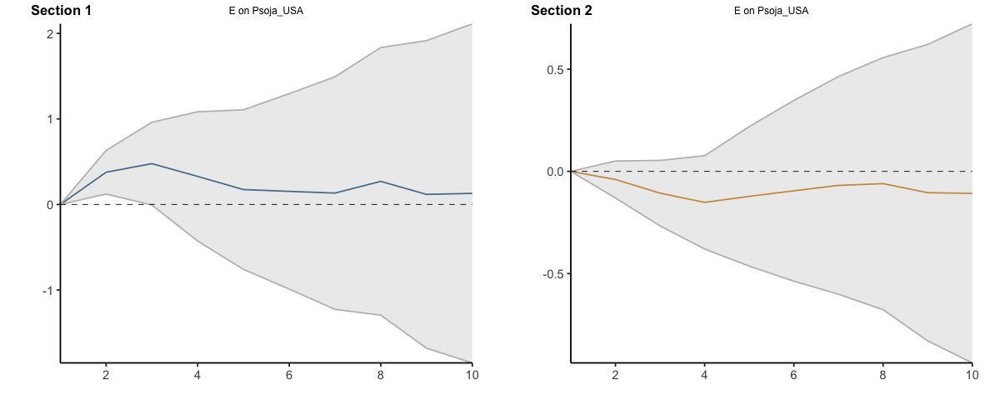

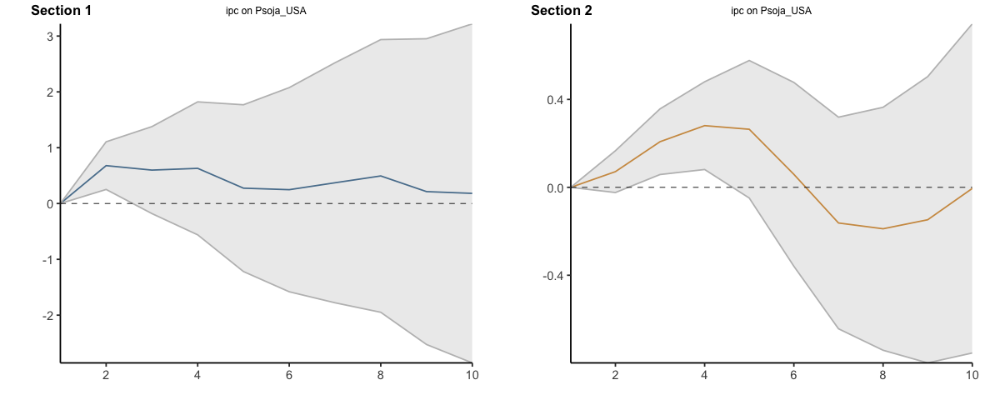

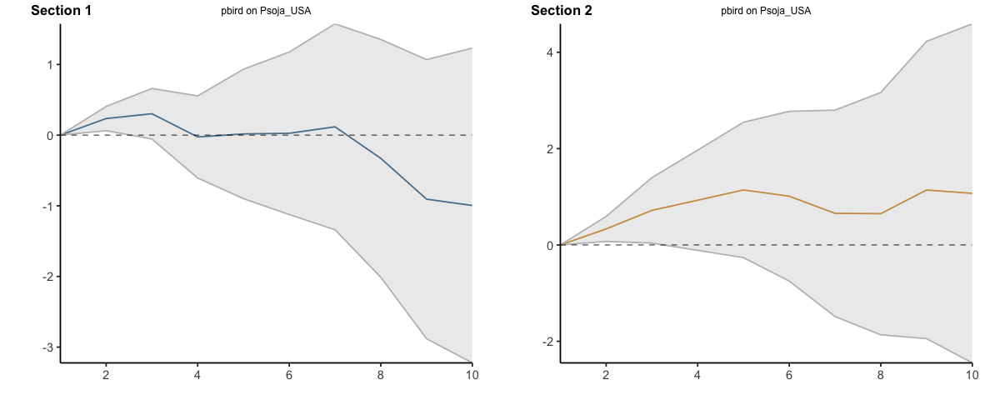

...

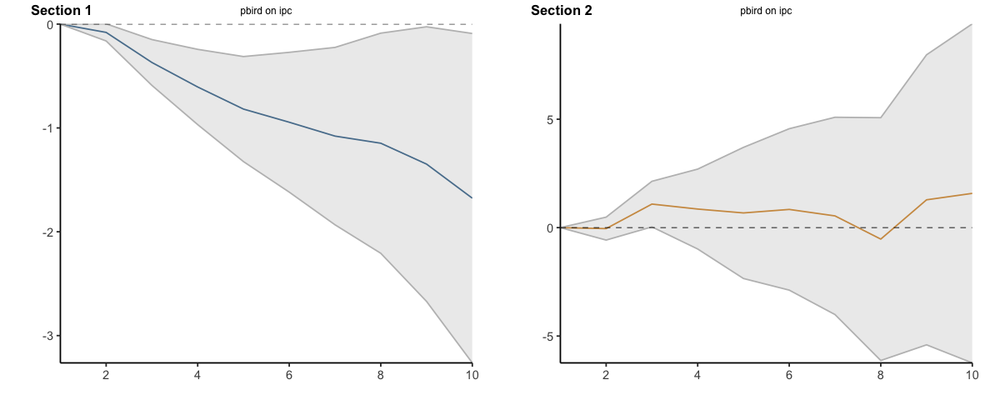

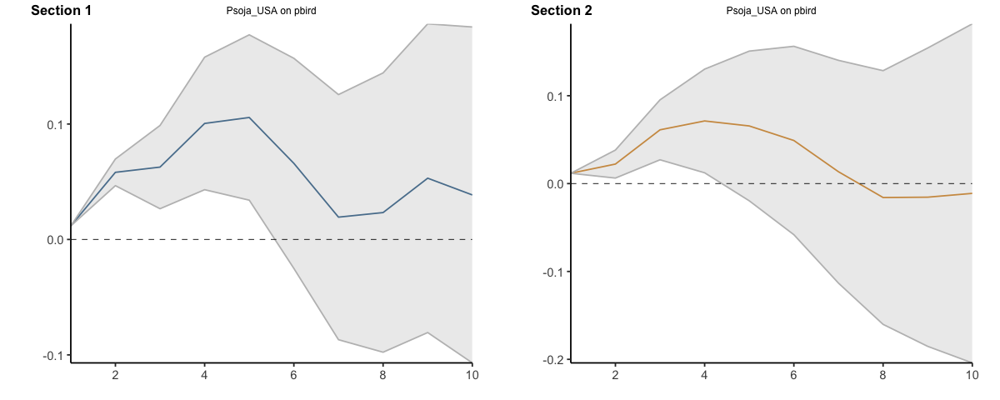

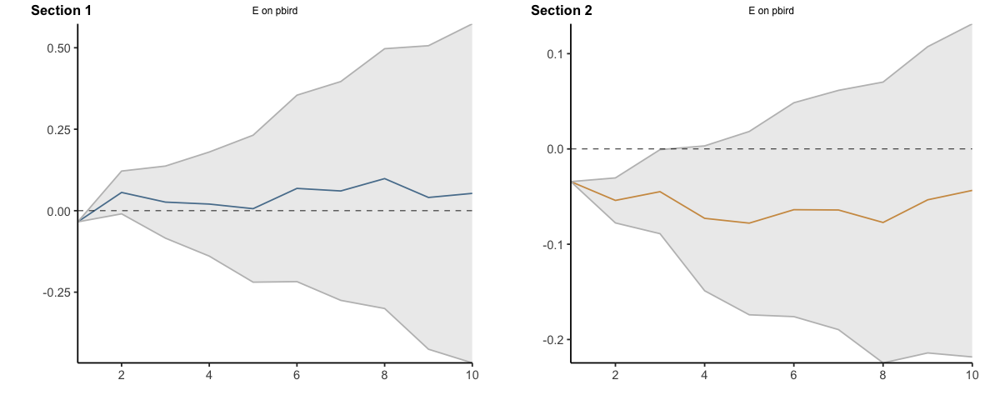

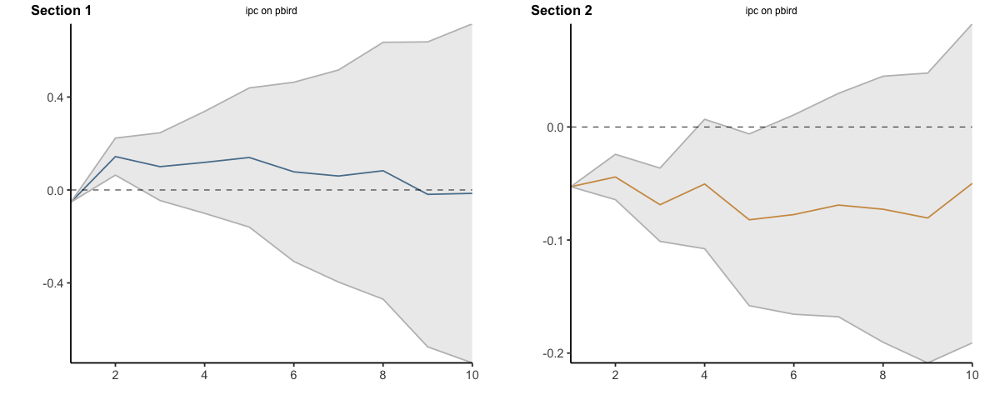

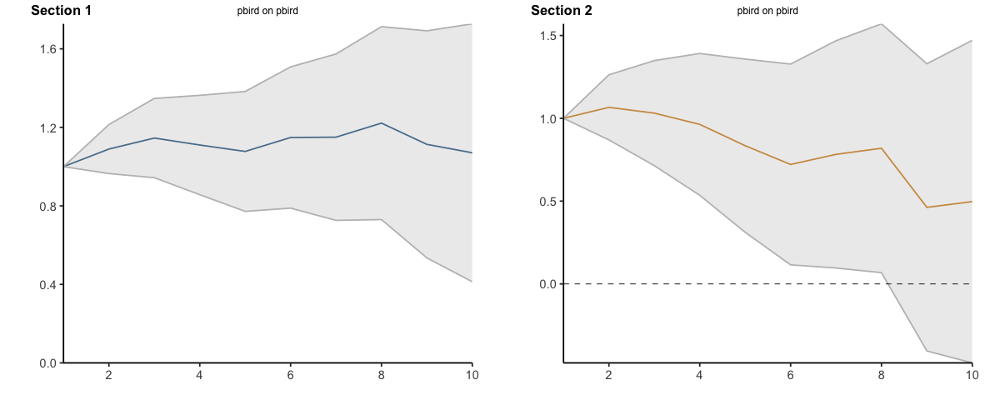

In [7]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.6, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.2031619,-0.2031619,-0.20316193,-0.2031619,-0.2031619,-0.2031619
2,2,-0.4907910,-0.6811373,-0.30044461,-0.3653428,-0.5476705,-0.1830151
3,3,-0.6111751,-1.0091920,-0.21315828,-0.4373304,-0.9792181,0.1045572
4,4,-0.6720821,-1.2339888,-0.11017550,-0.4527610,-1.3286179,0.4230959
5,5,-0.6303853,-1.3316646,0.07089402,-0.1147082,-1.6594162,1.4299998
6,6,-0.5987119,-1.5136427,0.31621893,0.1300835,-2.0369009,2.2970678
7,7,-0.6124577,-1.6912034,0.46628801,0.4101696,-2.3241766,3.1445158
8,8,-0.5369751,-1.8573995,0.78344919,0.8641419,-2.2054364,3.9337202
9,9,-0.3739514,-1.8969685,1.14906565,1.3249131,-2.2803613,4.9301875


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532
13,2,0.01118883,-0.01654097,0.03891863,-0.02042060,-0.12182437,0.08098316
14,3,0.02127180,-0.05899305,0.10153665,-0.16713756,-0.37884042,0.04456530
15,4,0.03503426,-0.09031721,0.16038573,-0.20319231,-0.60474814,0.19836352
16,5,0.07015479,-0.11423088,0.25454046,0.16123938,-0.71923826,1.04171701
17,6,0.06453652,-0.19589311,0.32496614,0.40211578,-0.99739637,1.80162793
18,7,0.08272034,-0.26615025,0.43159092,0.77741942,-1.02060035,2.57543920
19,8,0.04698062,-0.40103836,0.49499960,1.19758151,-1.03183613,3.42699915
20,9,0.02818927,-0.53410418,0.59048271,1.36103104,-1.23557968,3.95764176


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.000000000,0.00000000,0.000000,0.0000000
112,2,-0.8666024,-1.741572,0.008366829,-0.62605631,-1.736434,0.4843216
113,3,-2.3673895,-4.775660,0.040880723,-0.11561347,-2.122703,1.8914761
114,4,-3.1944082,-6.677602,0.288785866,-0.38107436,-3.762812,3.0006631
115,5,-3.7363265,-7.978221,0.505568326,-0.46681442,-5.447272,4.5136433
116,6,-2.5983178,-8.105382,2.908746559,0.30438007,-5.773467,6.3822268
117,7,-2.5874497,-9.081195,3.906295180,-0.18644271,-7.712804,7.3399187
118,8,-2.8158539,-11.014569,5.382860960,-0.08757429,-8.461277,8.2861282
119,9,-3.7850293,-12.889841,5.319782049,1.76434506,-8.682266,12.2109559


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.00000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000
123,2,-0.03682094,-0.2793105,0.2056686,0.1239661,-0.4295321,0.6774643
124,3,-0.41471734,-0.9469475,0.1175128,0.7158516,-0.3984482,1.8301514
125,4,-0.69947288,-1.5678932,0.1689475,0.7797718,-1.3024531,2.8619966
126,5,-0.81477678,-2.0376867,0.4081331,0.8325983,-2.4596819,4.1248785
127,6,-0.78289635,-2.4305739,0.8647812,1.1477259,-2.9663287,5.2617805
128,7,-0.80170178,-2.9653736,1.3619700,1.2682555,-3.8628652,6.3993761
129,8,-0.71614527,-3.4845689,2.0522783,1.1418224,-5.1079039,7.3915487
130,9,-0.81559178,-4.4478757,2.8166922,2.5577883,-5.2364168,10.3519934


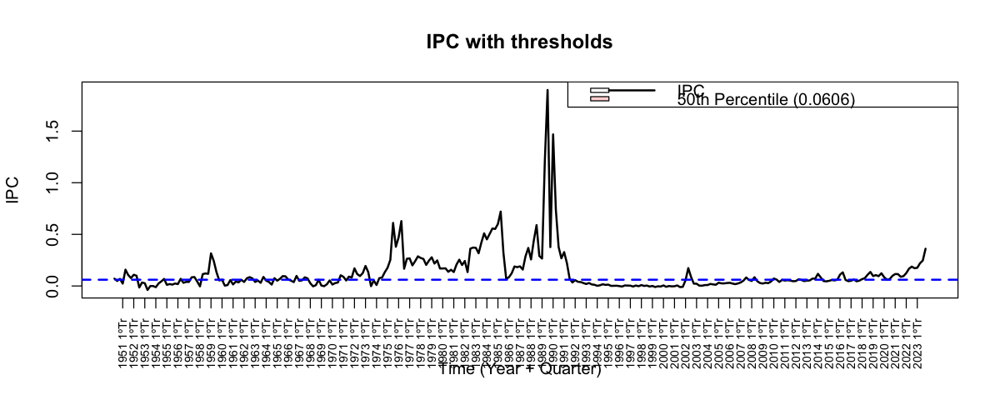

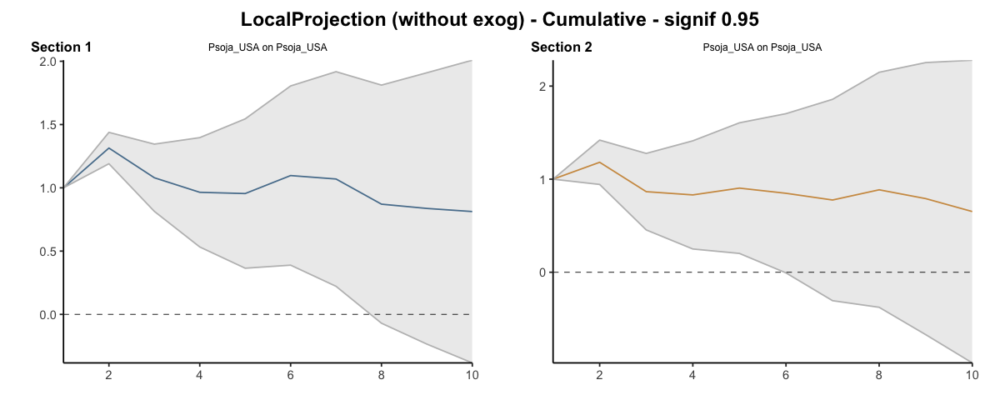

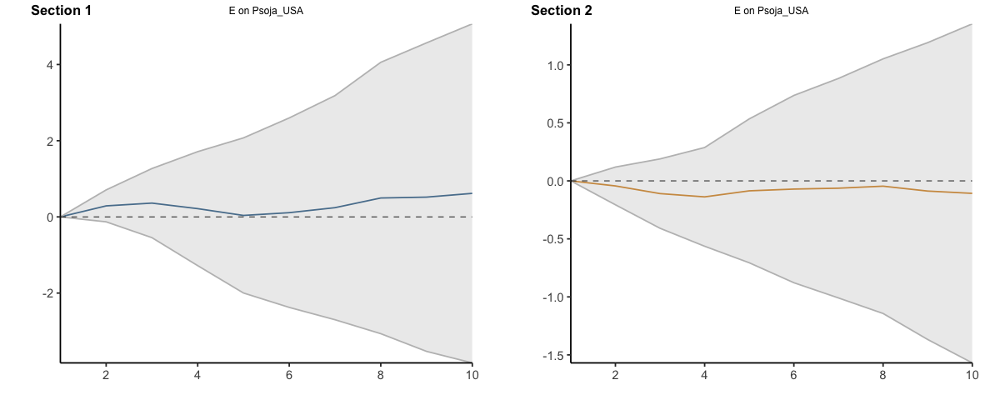

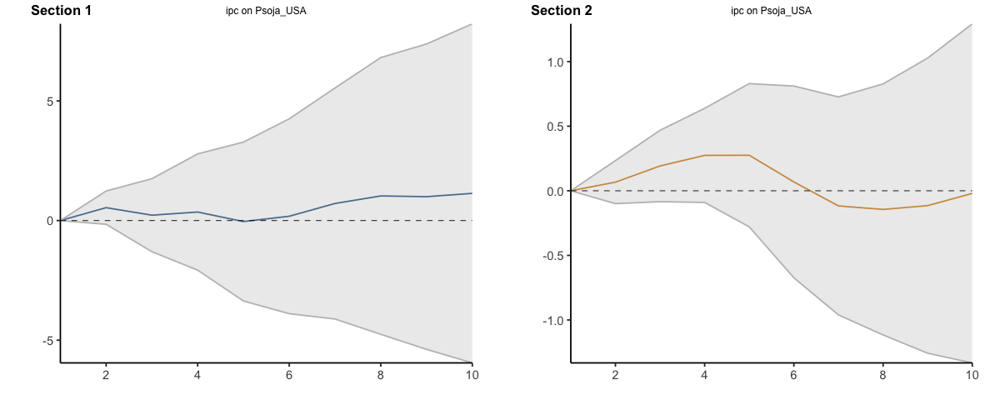

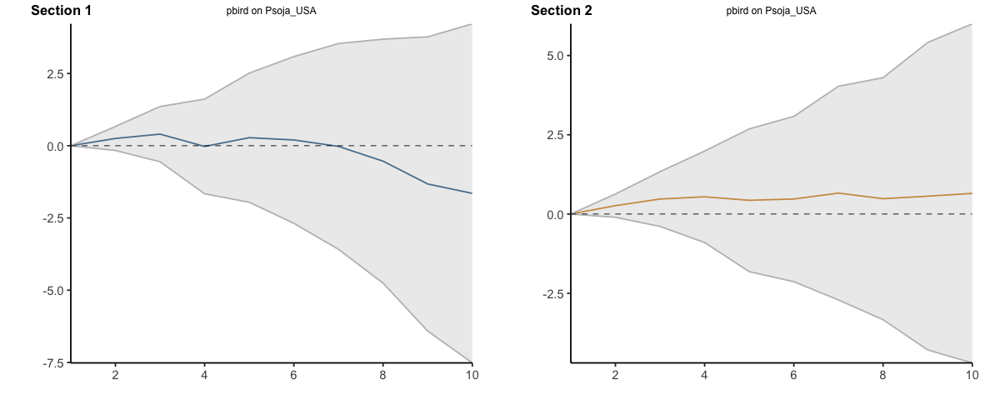

...

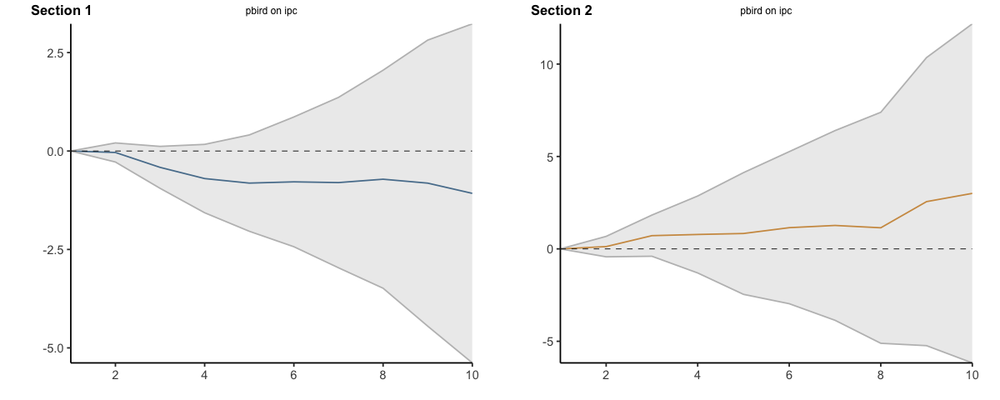

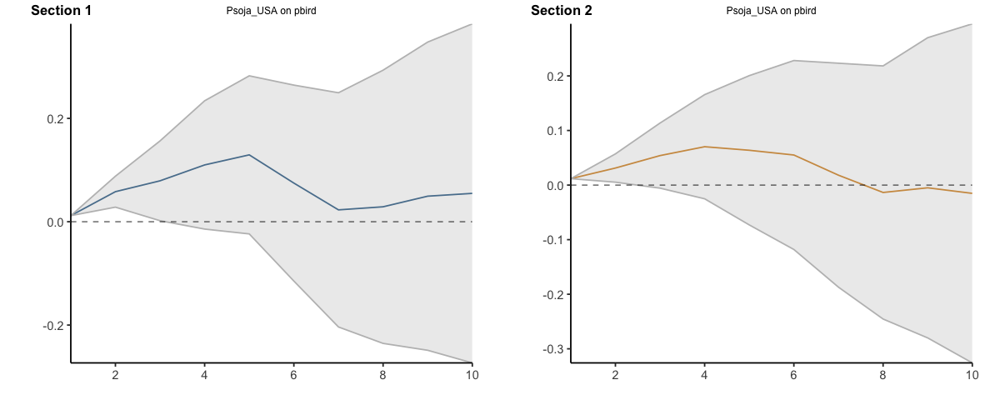

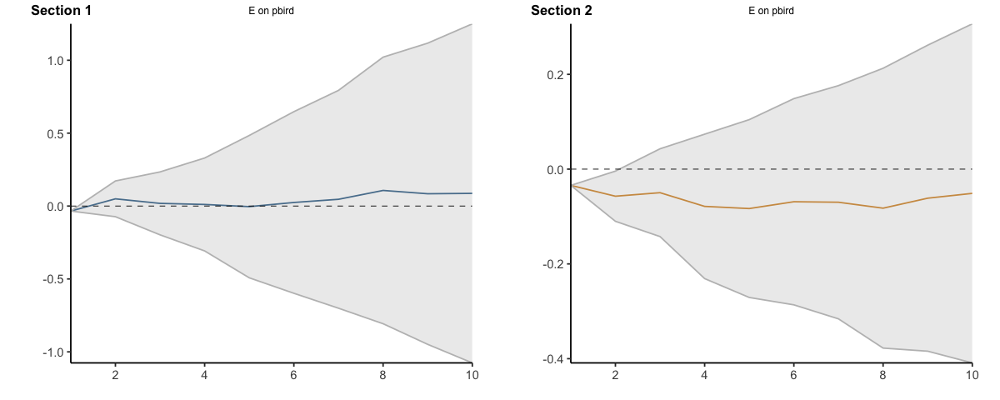

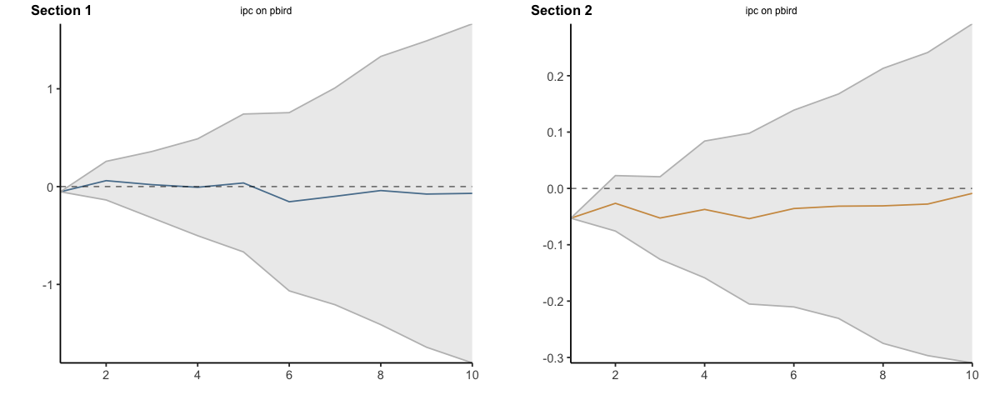

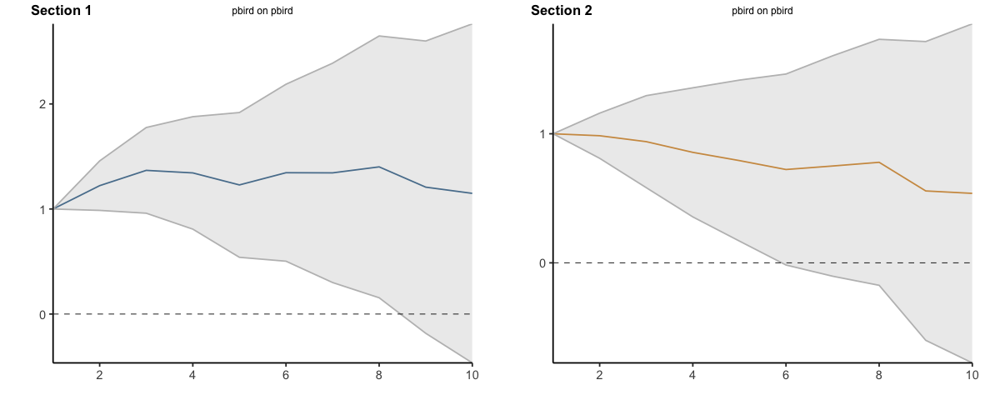

In [14]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.5, cumulative=TRUE)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.95,10,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"Psoja_USA, E, ipc, pbird",4


Impulse: Psoja_USA -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,1,-0.2031619,-0.2031619,-0.20316193,-0.20316193,-0.2031619,-0.2031619
2,2,-0.4527651,-0.6542814,-0.25124873,-0.36135274,-0.5330735,-0.1896319
3,3,-0.5712758,-1.0139618,-0.12858981,-0.44044257,-0.9485717,0.0676866
4,4,-0.5807506,-1.2124186,0.05091749,-0.51471722,-1.3071231,0.2776886
5,5,-0.6265131,-1.4115994,0.15857322,-0.18996468,-1.5765937,1.1966643
6,6,-0.5815703,-1.5775443,0.41440363,-0.05504432,-2.0038591,1.8937704
7,7,-0.5775026,-1.7443180,0.58931275,0.16038737,-2.3232230,2.6439977
8,8,-0.4285127,-1.7899859,0.93296064,0.49630553,-2.2872277,3.2798388
9,9,-0.2272732,-1.7606345,1.30608820,0.86718685,-2.4007686,4.1351422


Impulse: Psoja_USA -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
12,1,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532,-0.02370532
13,2,0.02976015,-0.01694559,0.07646588,-0.02037641,-0.10710256,0.06634974
14,3,0.04810902,-0.05477954,0.15099758,-0.15789320,-0.34388674,0.02810034
15,4,0.07890552,-0.07011094,0.22792198,-0.22820040,-0.57811405,0.12171325
16,5,0.12443404,-0.08350084,0.33236891,0.08296315,-0.68398910,0.84991540
17,6,0.11291032,-0.16575274,0.39157338,0.27359775,-0.96011564,1.50731114
18,7,0.12618193,-0.24433029,0.49669415,0.57792605,-0.99790789,2.15376000
19,8,0.11247685,-0.35167093,0.57662463,0.90741138,-1.07519638,2.89001914
20,9,0.12878898,-0.43202664,0.68960460,1.01112430,-1.31253956,3.33478816


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
111,1,0.0000000,0.000000,0.0000000,0.0000000,0.000000,0.0000000
112,2,-0.8074682,-1.747247,0.1323103,-0.7257771,-1.763639,0.3120847
113,3,-2.0654529,-4.510596,0.3796897,-0.5528222,-2.436099,1.3304549
114,4,-2.8811709,-6.631764,0.8694223,-0.8242928,-3.973384,2.3247989
115,5,-3.4429426,-7.921027,1.0351423,-1.0989940,-5.640900,3.4429121
116,6,-2.5651229,-8.203274,3.0730283,-0.3684444,-5.878907,5.1420179
117,7,-2.8119704,-9.509577,3.8856357,-0.7212152,-7.542807,6.1003766
118,8,-3.3281250,-11.628926,4.9726758,-0.5874452,-8.150038,6.9751471
119,9,-4.5308093,-13.962550,4.9009317,0.9296101,-8.283310,10.1425302


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
122,1,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000,0.0000000
123,2,0.1112930,-0.1228218,0.3454079,0.1366811,-0.3285277,0.6018899
124,3,-0.1868800,-0.7853494,0.4115895,0.5071816,-0.4587567,1.4731200
125,4,-0.4506227,-1.3947156,0.4934702,0.5450589,-1.3096373,2.3997551
126,5,-0.5995092,-1.9831321,0.7841137,0.5619570,-2.3554275,3.4793415
127,6,-0.5578704,-2.3746107,1.2588698,0.7625152,-2.8966928,4.4217233
128,7,-0.6800427,-3.0163532,1.6562678,0.8175735,-3.7950460,5.4301930
129,8,-0.9060999,-3.8228855,2.0106857,0.7967870,-4.7967332,6.3903072
130,9,-1.0701969,-4.8655654,2.7251716,1.9683055,-4.8696167,8.8062278


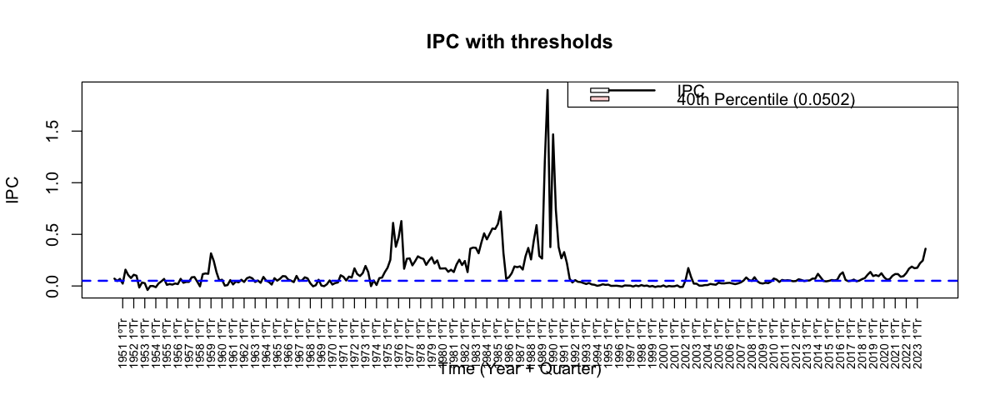

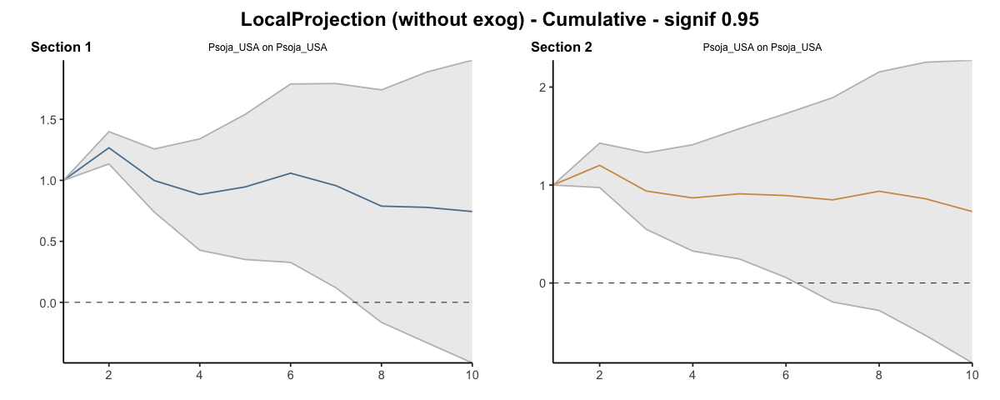

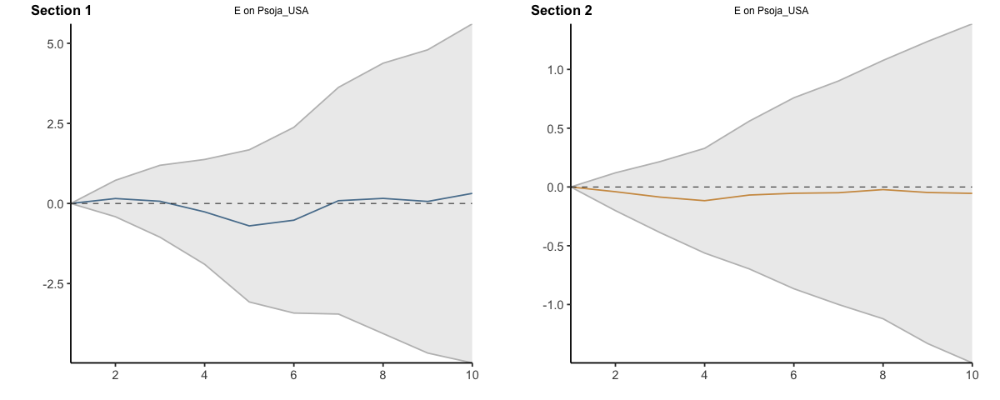

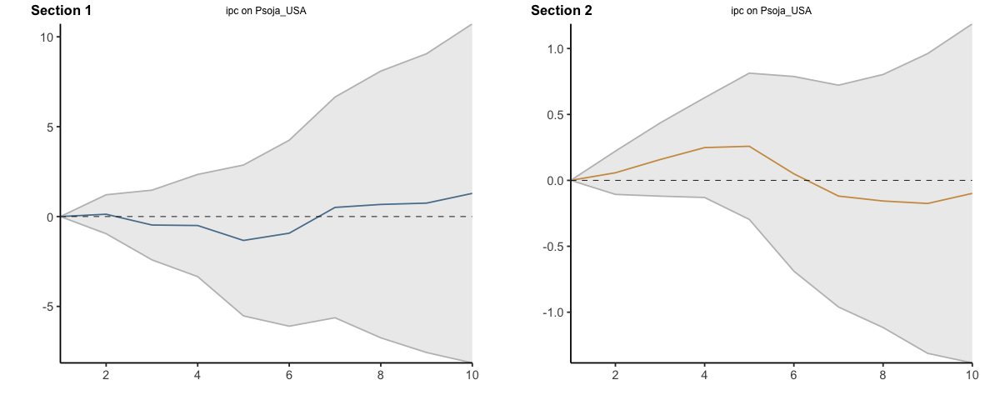

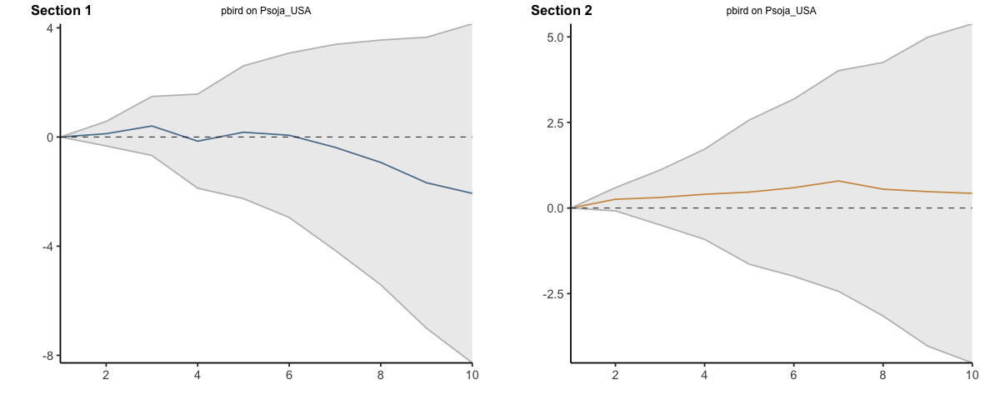

...

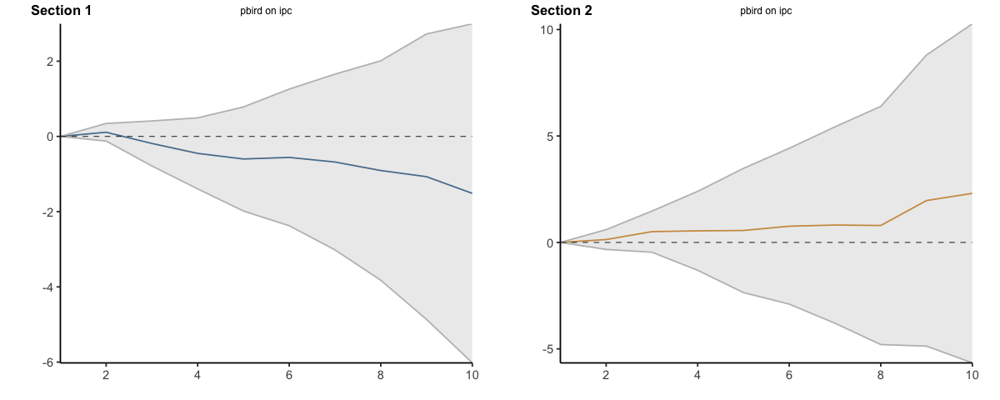

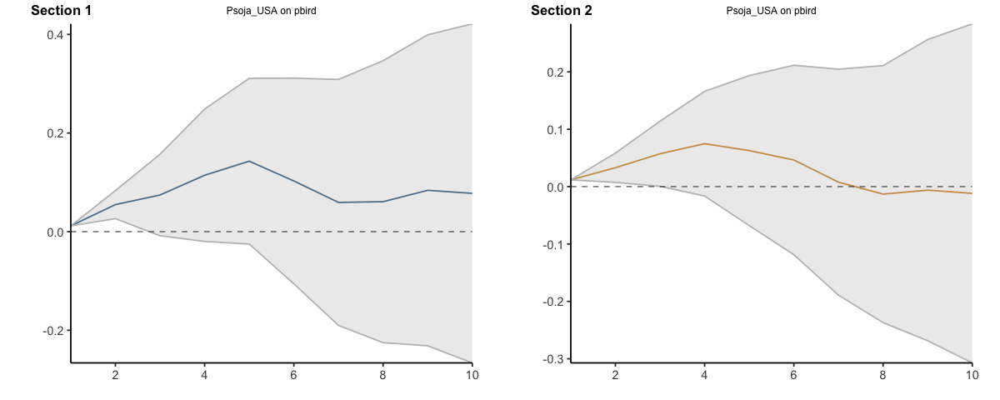

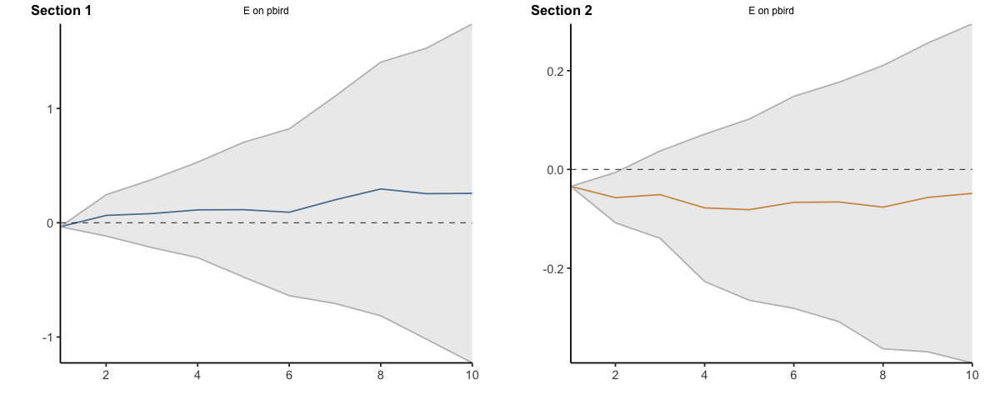

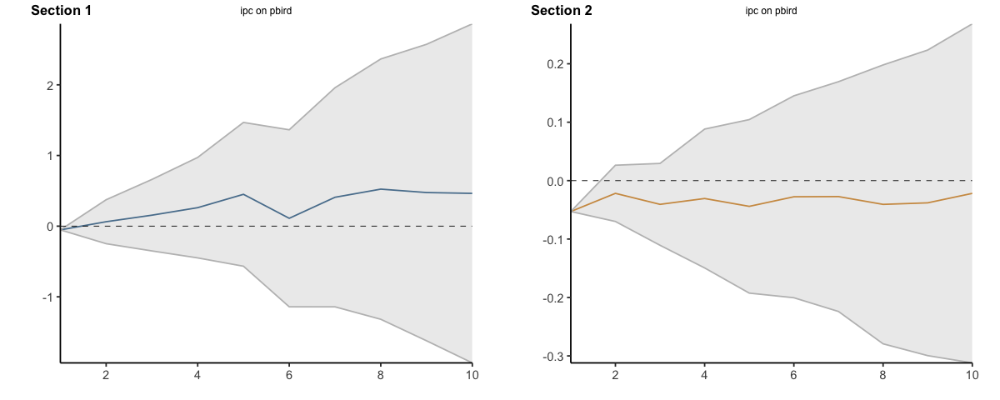

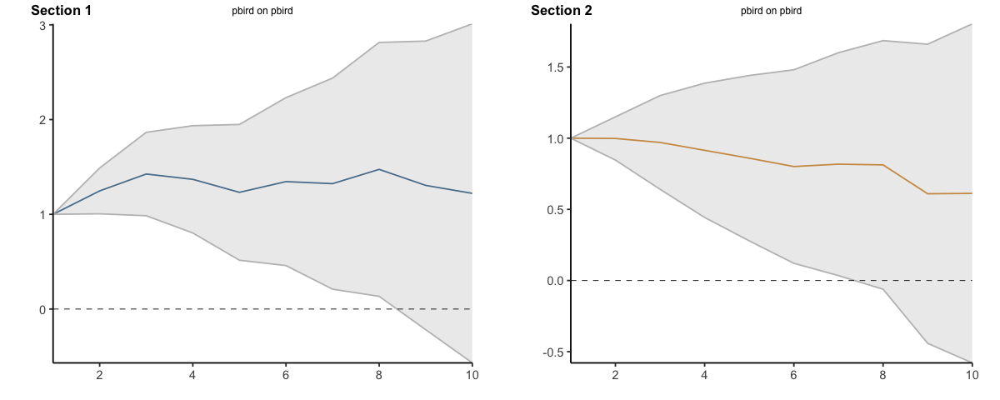

In [15]:
res <- run_lp_model(df_ERPT_Arg, endog=c("Psoja_USA", "E", "ipc", "pbird"), fixed_lags = 3, horizons=10, signif = 0.95, threshold_var = 'ipc', upper_threshold=0.4, cumulative=TRUE)

### Todas endógenas - 3 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4402723,-1.4402723,-1.4402723,-1.440272,-1.4402723,-1.4402723
2,1,-1.0235361,-1.1151577,-0.9319145,1.370368,-1.4309737,4.1717088
3,2,-0.7441868,-0.8776639,-0.6107096,2.442228,0.1085005,4.7759546
4,3,0.2258401,0.1181366,0.3335437,-1.699705,-3.1457098,-0.2537011
5,4,0.6228142,0.2000171,1.0456112,1.429821,-0.6437720,3.5034144
6,5,1.1087716,0.6783943,1.5391489,1.843603,0.4491519,3.2380539
7,6,1.4335911,1.0303022,1.8368800,-0.357756,-2.0857793,1.3702674
8,7,1.4918946,1.0011684,1.9826208,3.113535,1.8415192,4.3855501
9,8,1.2264662,1.1559545,1.2969779,4.645036,2.8744339,6.4156377


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.5899488,-0.58994884,-0.58994884,-0.58994884,-0.589948844,-0.5899488
11,1,-0.3697636,-0.34876017,-0.39076695,1.16440177,-0.001154038,2.3299576
12,2,-0.2870859,-0.30208429,-0.27208752,2.57180149,0.081661091,5.0619419
13,3,-0.0772734,-0.07479234,-0.07975447,-0.05680234,-1.183071583,1.0694669
14,4,0.1288550,0.11854676,0.13916326,2.16048405,0.397589479,3.9233786
15,5,0.3599272,0.23654548,0.48330895,2.13418245,0.521186467,3.7471784
16,6,0.6931553,0.31040894,1.07590168,0.41989688,-0.749604644,1.5893984
17,7,0.8100160,0.51420187,1.10583019,1.85557851,0.985100005,2.7260570
18,8,1.1228107,0.93035556,1.31526592,3.12649938,1.701249459,4.5517493


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000
92,1,-0.6066739,-0.9325594,-0.28078834,-1.4392757,-2.5218975,-0.3566540
93,2,-0.9137863,-1.4081975,-0.41937507,0.4971065,-0.5015688,1.4957819
94,3,-0.6450376,-1.0179130,-0.27216218,-0.2440557,-1.5616447,1.0735333
95,4,-0.4439821,-0.8206832,-0.06728092,-0.2534319,-1.6643659,1.1575020
96,5,0.1260479,-0.3514528,0.60354861,0.6455518,-0.5999926,1.8910962
97,6,-0.5123728,-0.8329467,-0.19179900,-2.2431866,-3.9853468,-0.5010263
98,7,-0.6200036,-1.0788298,-0.16117739,-0.4859968,-1.4744683,0.5024747
99,8,-0.8317665,-1.1970932,-0.46643984,2.3197522,0.3052029,4.3343015


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.000000000,0.00000000,0.00000000,0.00000000,0.0000000,0.00000000
101,1,-0.002054456,-0.07185289,0.06774397,-0.04805812,-0.7445247,0.64840844
102,2,-0.219648790,-0.34309092,-0.09620666,0.46301504,-0.2390252,1.16505524
103,3,-0.243592747,-0.38324538,-0.10394012,0.07069735,-1.0061287,1.14752338
104,4,-0.264713974,-0.44926987,-0.08015808,0.15144038,-0.9655205,1.26840128
105,5,-0.260192941,-0.48363415,-0.03675173,0.30106931,-0.6757650,1.27790365
106,6,-0.299102440,-0.53631477,-0.06189011,-0.59439381,-1.6980195,0.50923188
107,7,-0.267921843,-0.49945100,-0.03639269,-1.14291107,-2.2607510,-0.02507117
108,8,-0.388128875,-0.66886642,-0.10739133,1.76419718,0.3175711,3.21082323


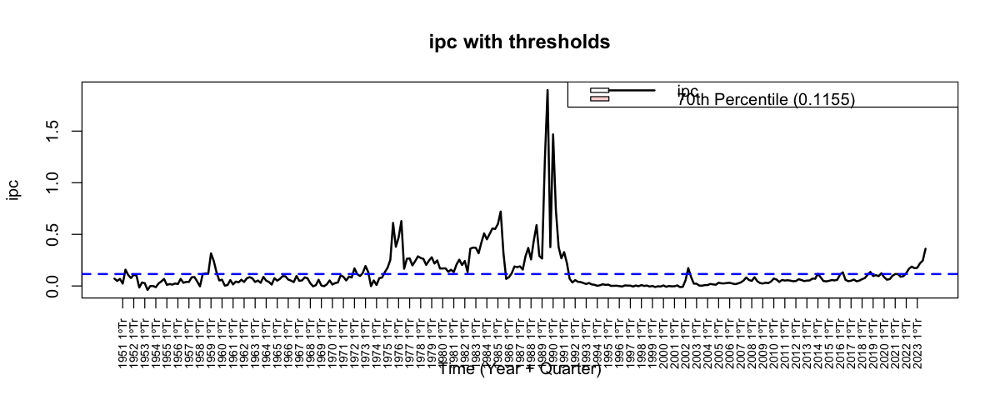

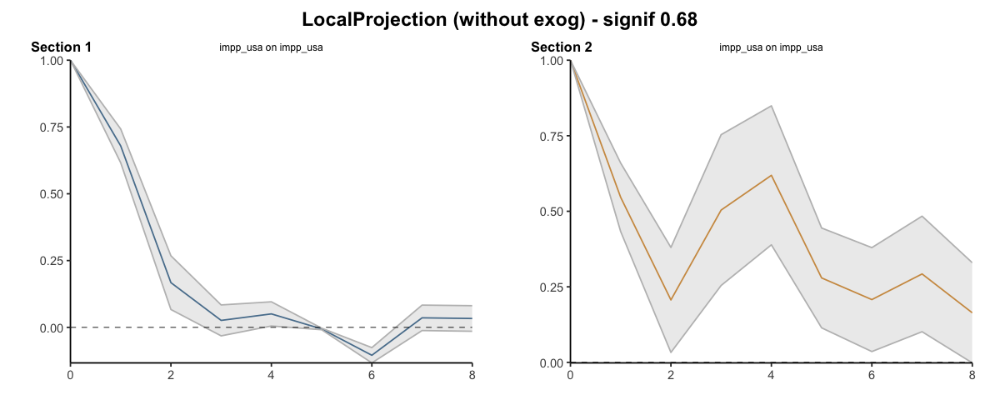

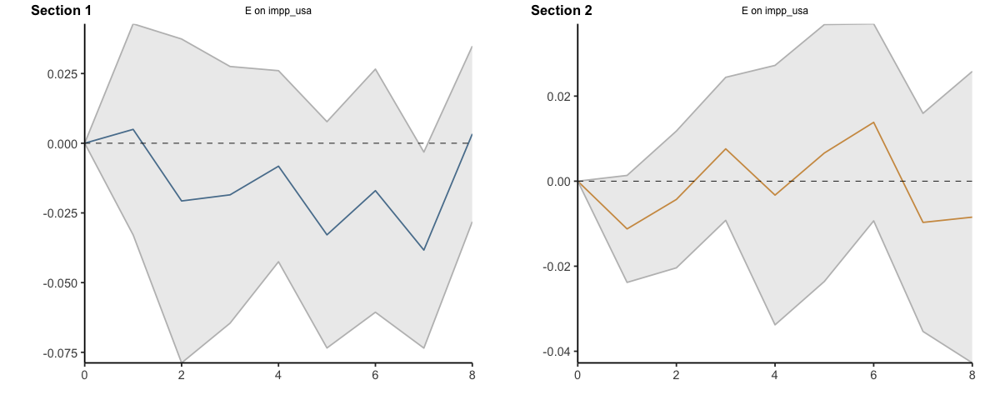

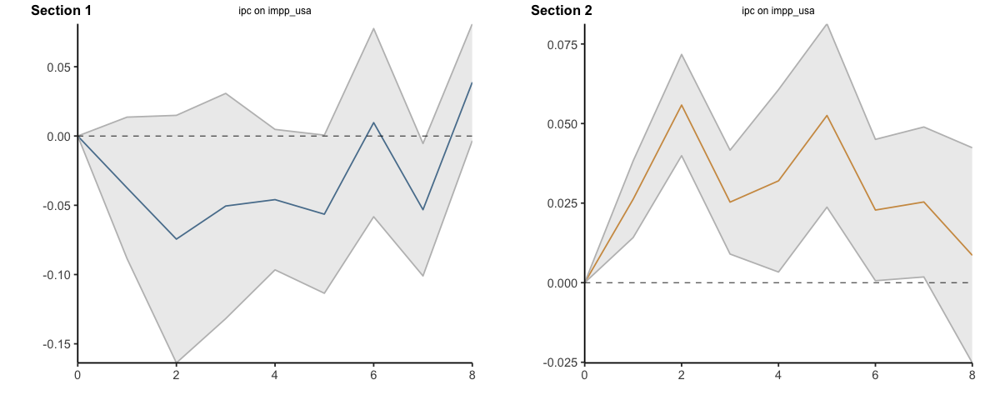

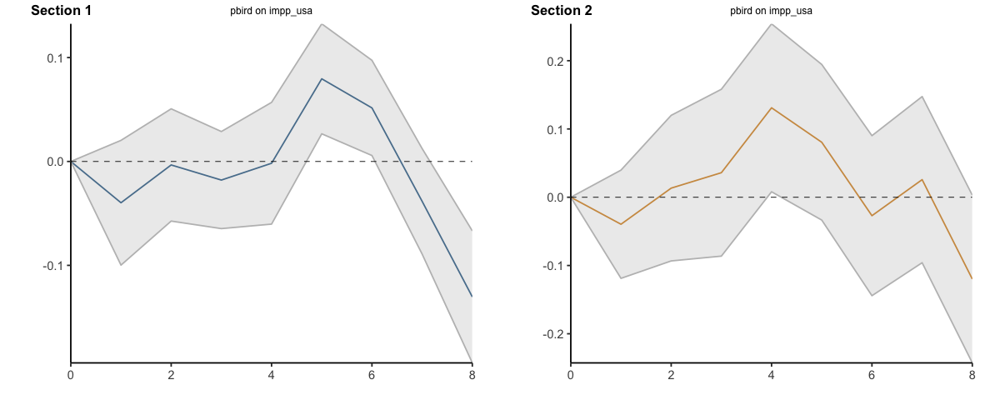

...

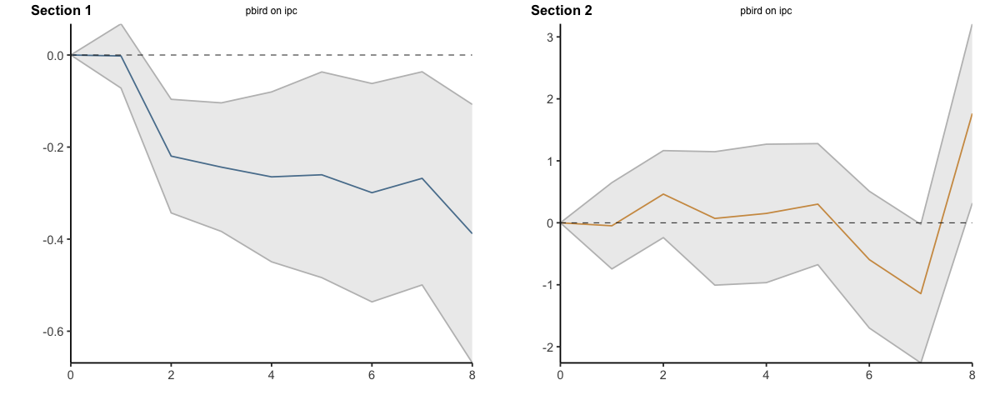

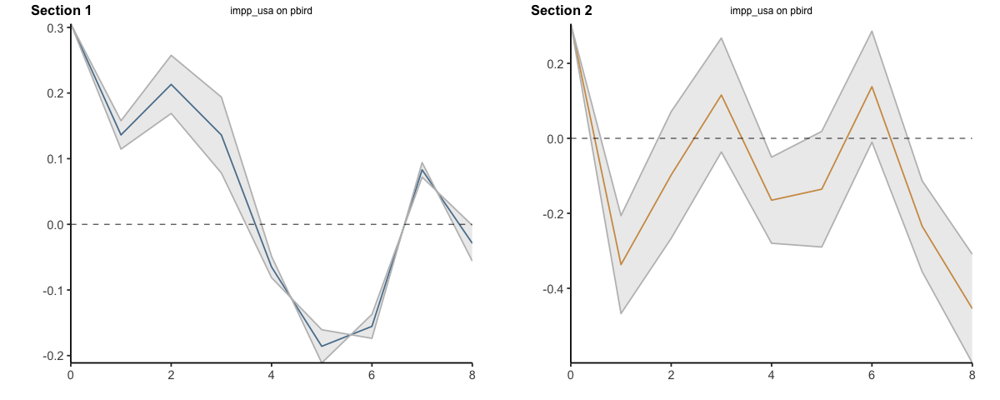

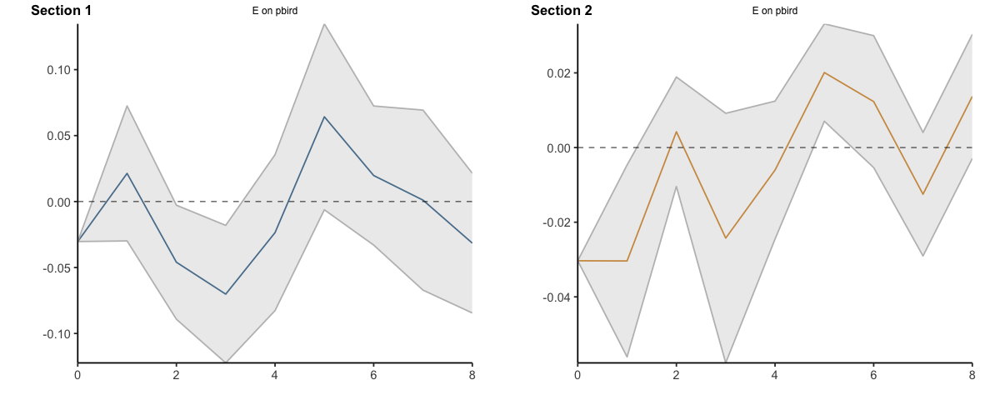

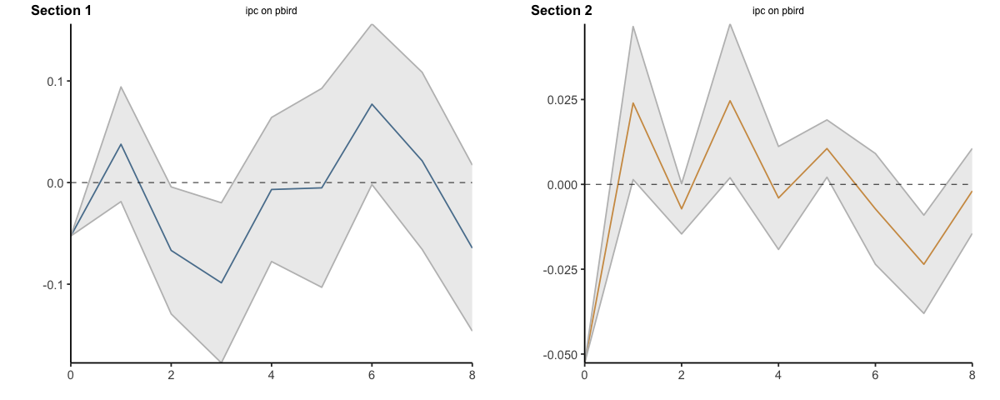

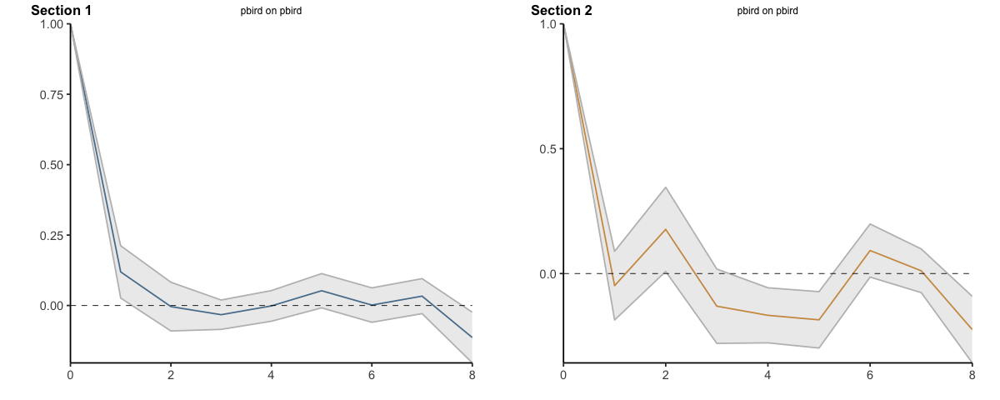

In [28]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
3,3,NaN,NA,NA,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"impp_usa, E, ipc, pbird",4


Impulse: impp_usa -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,-1.4402723,-1.4402723,-1.44027226,-1.4402723,-1.440272,-1.440272
2,1,-2.4638083,-2.5554299,-2.37218676,-0.0699047,-2.871246,2.731437
3,2,-3.2079951,-3.4330938,-2.98289638,2.3723229,-2.762745,7.507391
4,3,-2.9821550,-3.3149572,-2.64935268,0.6726174,-5.908455,7.253690
5,4,-2.3593408,-3.1149401,-1.60374150,2.1024386,-6.552227,10.757104
6,5,-1.2505692,-2.4365458,-0.06459257,3.9460415,-6.103075,13.995158
7,6,0.1830219,-1.4062436,1.77228742,3.5882855,-8.188855,15.365426
8,7,1.6749165,-0.4050752,3.75490820,6.7018202,-6.347336,19.750976
9,8,2.9013827,0.7508793,5.05188606,11.3468560,-3.472902,26.166614


Impulse: impp_usa -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.5899488,-0.5899488,-0.5899488,-0.5899488,-0.5899488,-0.5899488
11,1,-0.9597124,-0.9387090,-0.9807158,0.5744529,-0.5911029,1.7400087
12,2,-1.2467983,-1.2407933,-1.2528033,3.1462544,-0.5094418,6.8019506
13,3,-1.3240717,-1.3155856,-1.3325578,3.0894521,-1.6925134,7.8714175
14,4,-1.1952167,-1.1970389,-1.1933945,5.2499361,-1.2949239,11.7947962
15,5,-0.8352895,-0.9604934,-0.7100856,7.3841186,-0.7737374,15.5419746
16,6,-0.1421342,-0.6500845,0.3658161,7.8040155,-1.5233421,17.1313730
17,7,0.6678819,-0.1358826,1.4716463,9.6595940,-0.5382421,19.8574300
18,8,1.7906926,0.7944730,2.7869122,12.7860933,1.1630074,24.4091793


... (16 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
91,0,0.0000000,0.0000000,0.0000000,0.0000000,0.000000,0.000000
92,1,-0.6066739,-0.9325594,-0.2807883,-1.4392757,-2.521897,-0.356654
93,2,-1.5204601,-2.3407569,-0.7001634,-0.9421692,-3.023466,1.139128
94,3,-2.1654977,-3.3586698,-0.9723256,-1.1862249,-4.585111,2.212661
95,4,-2.6094798,-4.1793531,-1.0396065,-1.4396568,-6.249477,3.370163
96,5,-2.4834319,-4.5308059,-0.4360579,-0.7941050,-6.849469,5.261259
97,6,-2.9958047,-5.3637526,-0.6278569,-3.0372916,-10.834816,4.760233
98,7,-3.6158083,-6.4425824,-0.7890343,-3.5232884,-12.309285,5.262708
99,8,-4.4475748,-7.6396756,-1.2554741,-1.2035362,-12.004082,9.597009


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100,0,0.000000000,0.00000000,0.00000000,0.00000000,0.0000000,0.0000000
101,1,-0.002054456,-0.07185289,0.06774397,-0.04805812,-0.7445247,0.6484084
102,2,-0.221703246,-0.41494381,-0.02846268,0.41495691,-0.9835499,1.8134637
103,3,-0.465295993,-0.79818918,-0.13240280,0.48565427,-1.9896785,2.9609871
104,4,-0.730009968,-1.24745905,-0.21256088,0.63709464,-2.9551991,4.2293883
105,5,-0.990202909,-1.73109321,-0.24931261,0.93816395,-3.6309641,5.5072920
106,6,-1.289305349,-2.26740797,-0.31120272,0.34377015,-5.3289836,6.0165239
107,7,-1.557227192,-2.76685897,-0.34759541,-0.79914092,-7.5897346,5.9914527
108,8,-1.945356066,-3.43572539,-0.45498674,0.96505626,-7.2721634,9.2022759


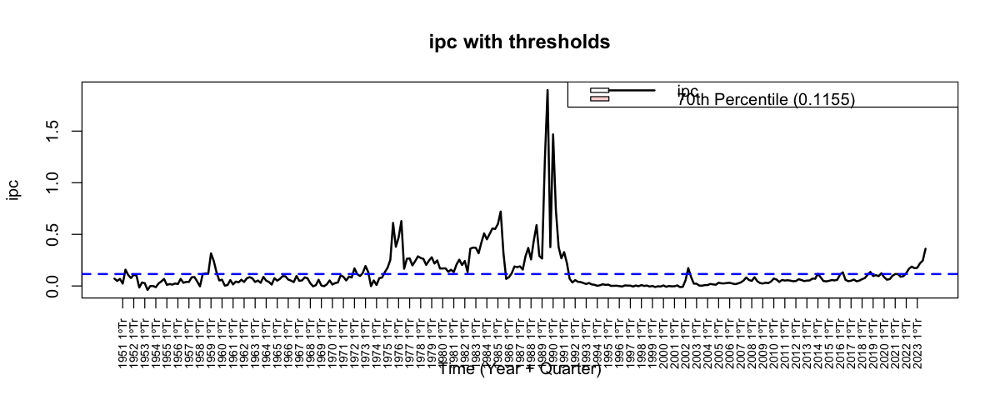

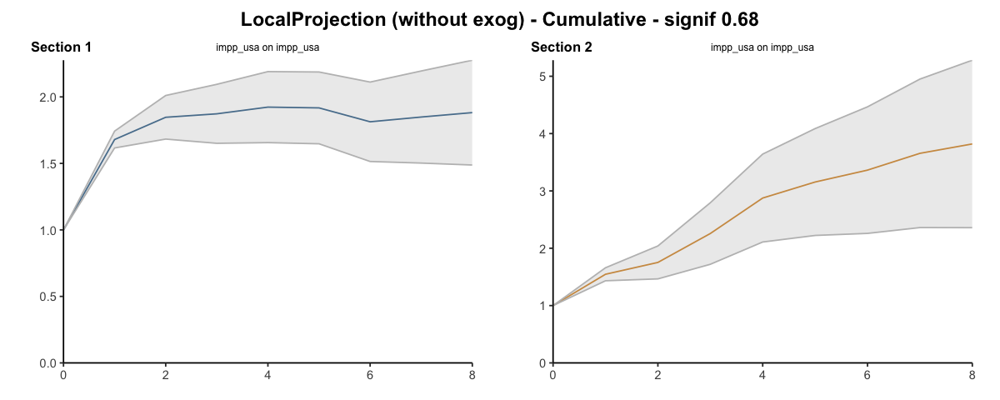

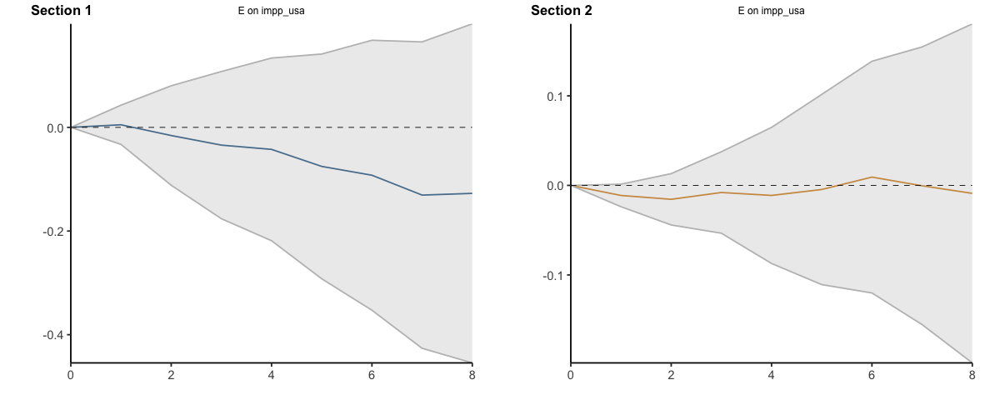

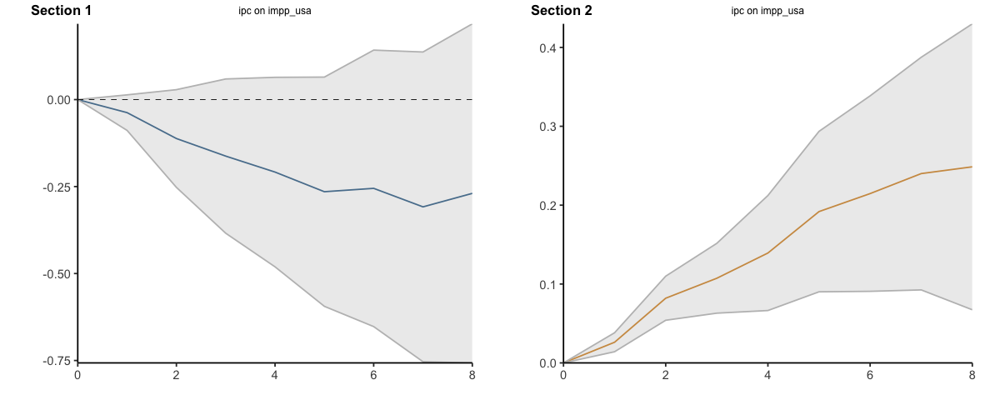

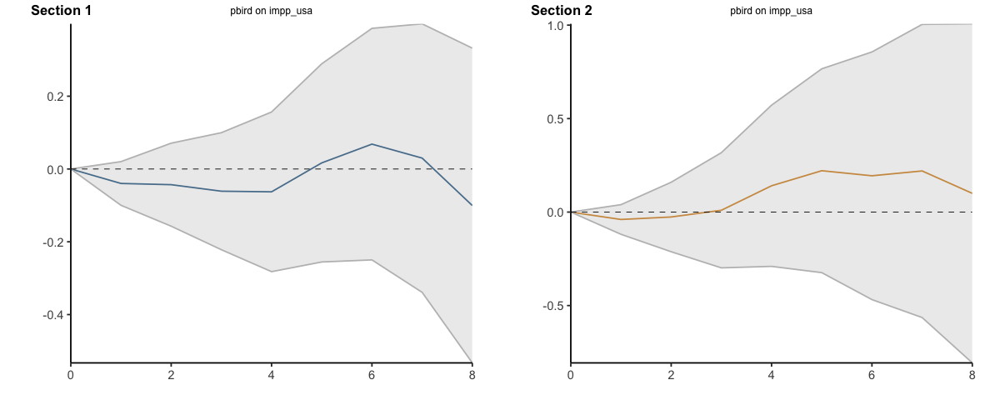

...

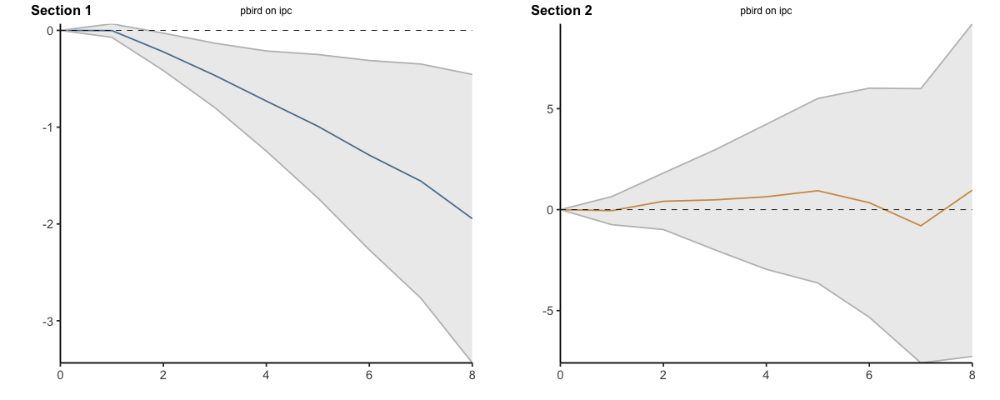

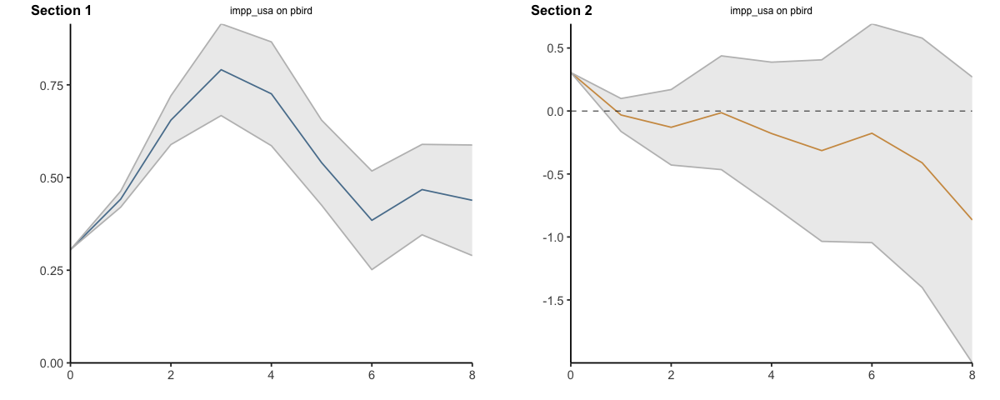

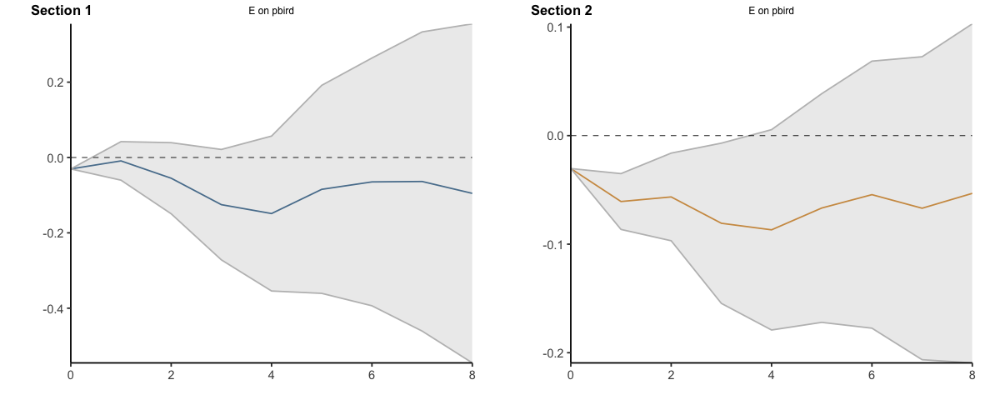

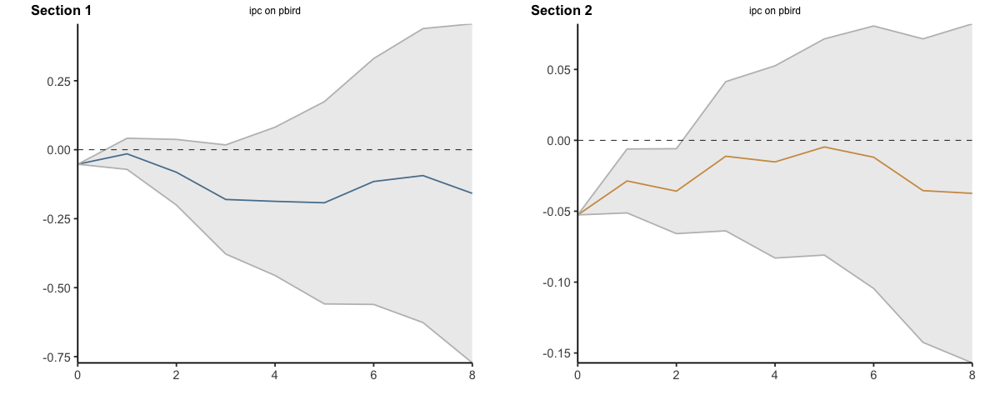

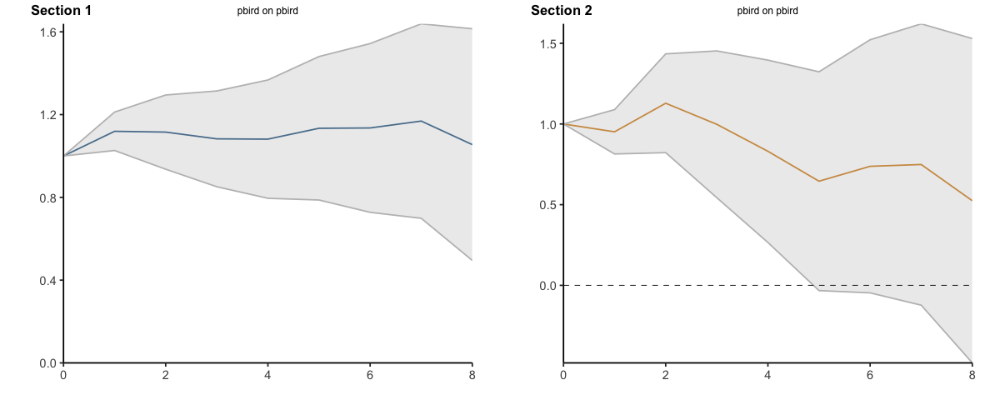

In [29]:
res <- run_lp_model(df_ERPT_Arg, endog=c("impp_usa", "E", "ipc", "pbird"), fixed_lags = 3, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

#### Percentile 70 - 3 lags

Umbral: ipc > 0.1155 (percentil 70 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 206 | encima del umbral (dummy = 1) = 89 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, umbral: ipc > 0,115, 89 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4489         0.4489       1.0000
         1              0.7685         0.5624       1.3665
         2              1.0129         0.6412       1.5798
         3              1.1464         0.7983       1.4361
         4              1.2441         0.9469       1.3138
         5              1.2263         0.9728       1.2606
         6              1.2135         1.1096       1.0937
         7              1.2135         1.3615       0.8913
         8              1.0309         2.3405       0.4405
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4489             0.4489
                  0.3196             0.1135
                  0.2444             0.0788
                  0.1

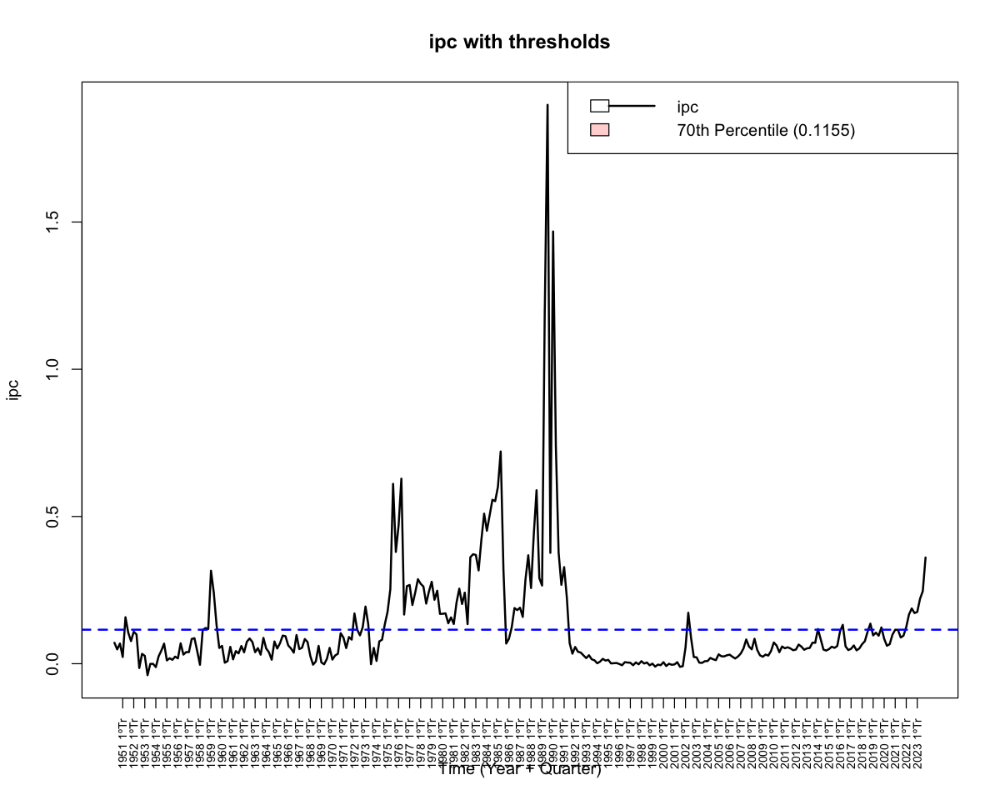

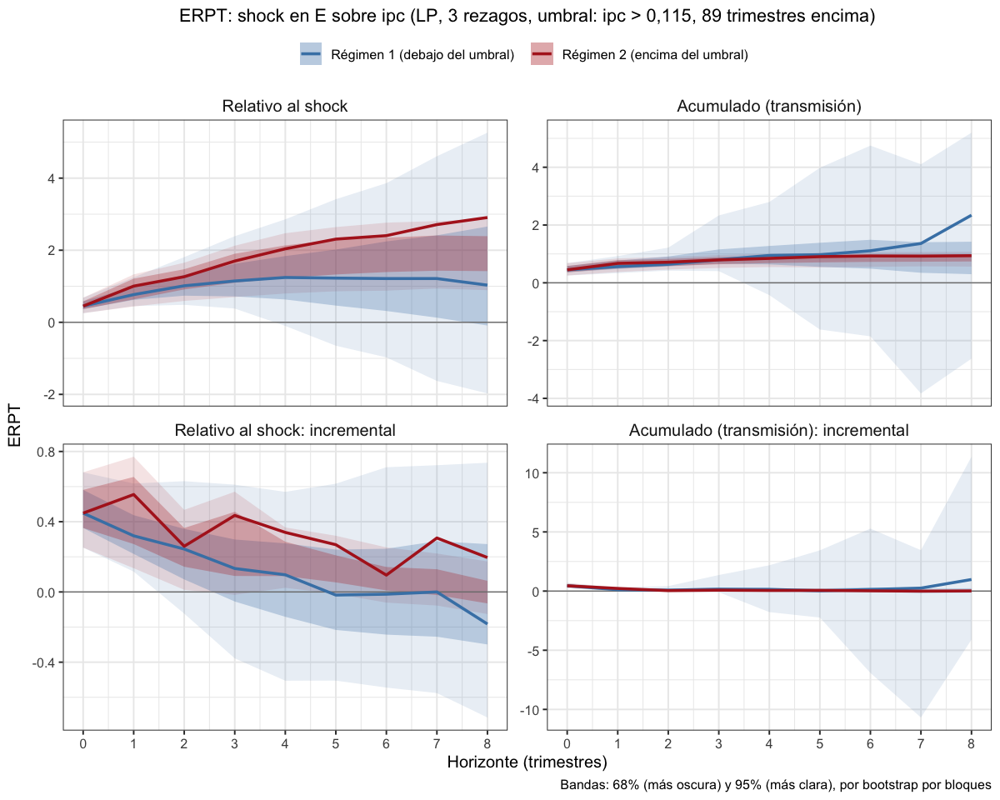

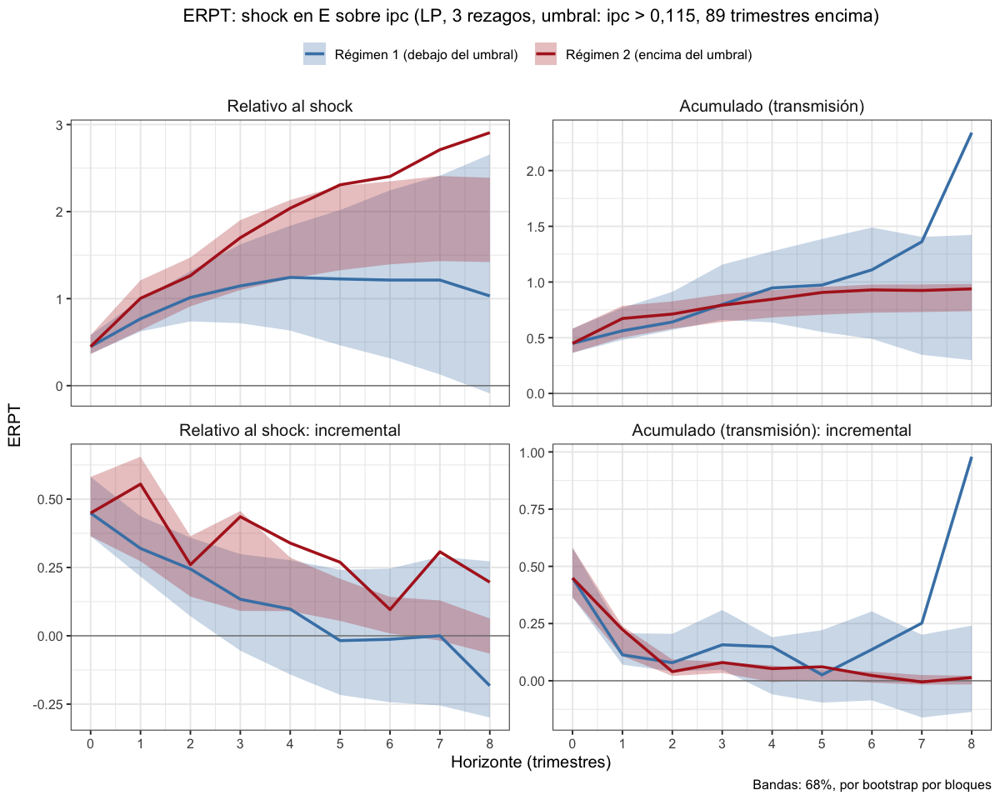

In [12]:
# Todas endógenas con umbral en el percentil 70 del ipc, 3 rezagos
lp_erpt_endog_p3_u70 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                fixed_lags = 3, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.7)
saveRDS(lp_erpt_endog_p3_u70, "lp_erpt_endog_p3_u70.rds")
graficar_erpt_lp(lp_erpt_endog_p3_u70, archivo = "lp_erpt_endog_p3_u70")
graficar_erpt_lp(lp_erpt_endog_p3_u70, niveles = 0.68, archivo = "lp_erpt_endog_p3_u70_68")

#### Percentile 0.725423728813559 (12,5% inflación trimestral) - quedan 81 trimestres por encima del umbral

Umbral: ipc > 0.1265 (percentil 72.5 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 214 | encima del umbral (dummy = 1) = 81 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, umbral: ipc > 0,127, 81 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4489         0.4489       1.0000
         1              0.8368         0.6182       1.3535
         2              1.1457         0.7138       1.6050
         3              1.3042         0.8622       1.5127
         4              1.4158         1.0153       1.3945
         5              1.4500         1.0420       1.3915
         6              1.5009         1.1293       1.3290
         7              1.5440         1.2944       1.1928
         8              1.4580         1.6330       0.8928
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4489             0.4489
                  0.3879             0.1693
                  0.3089             0.0956
                  0.1

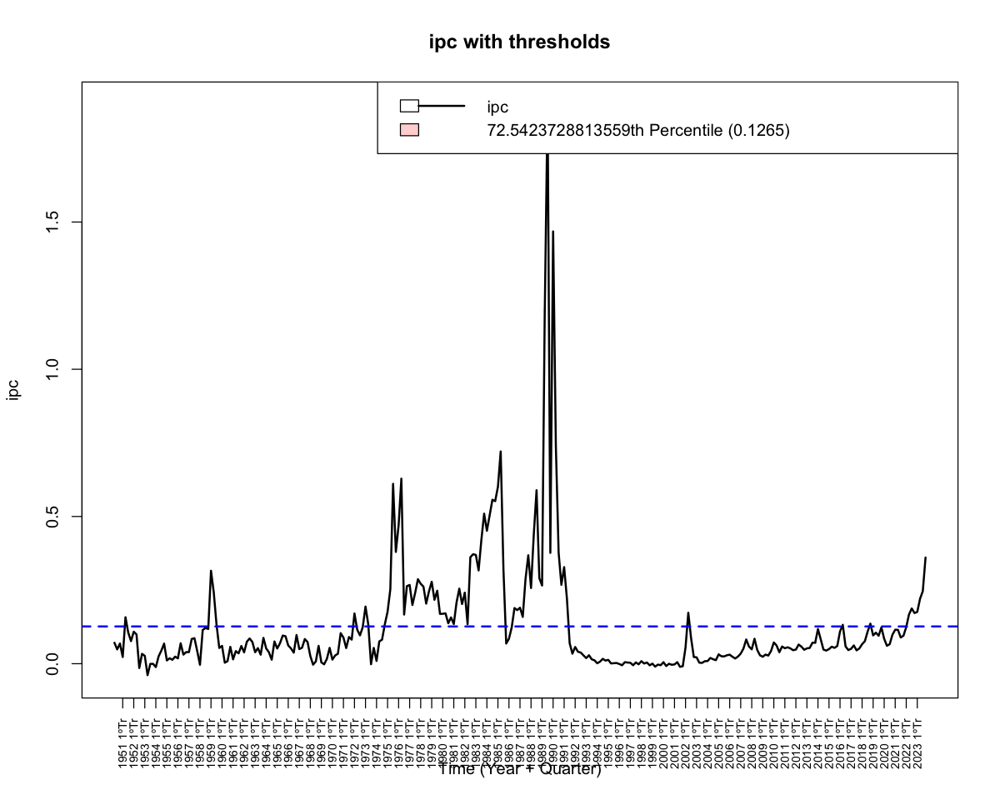

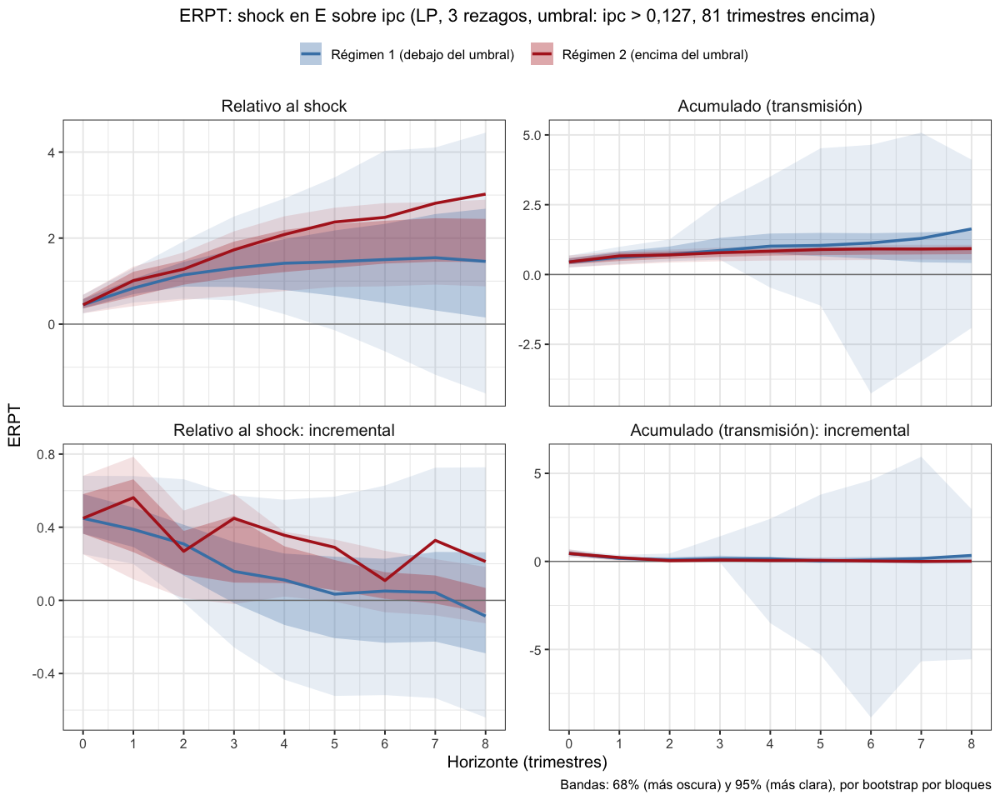

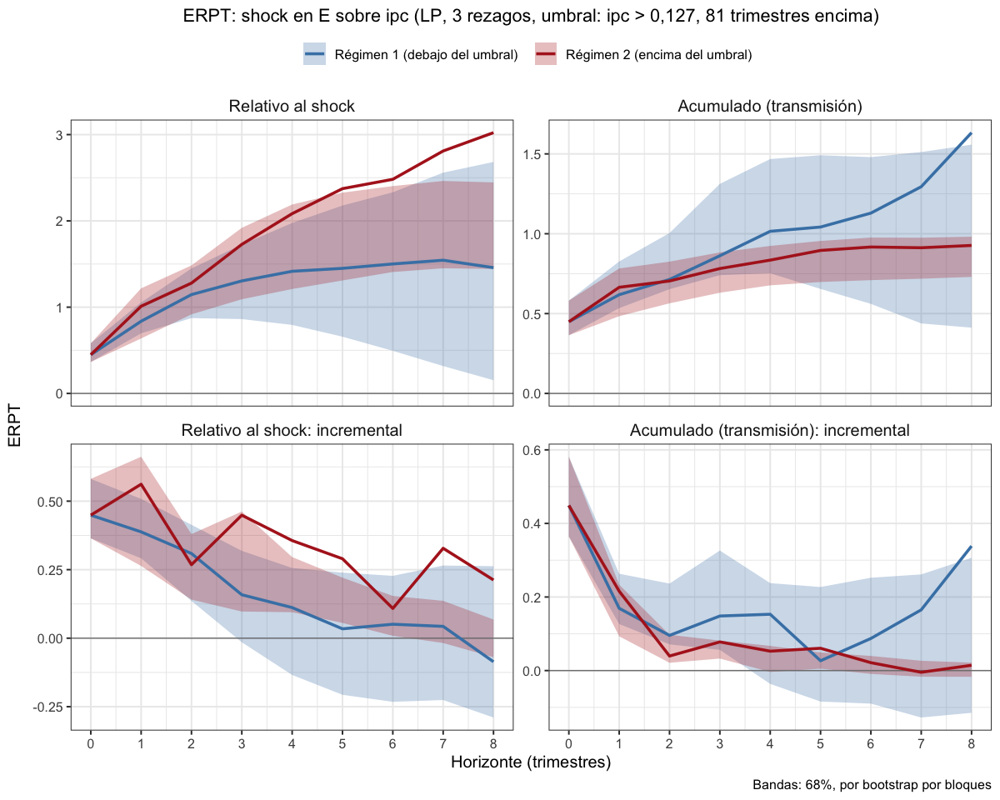

In [13]:
# Todas endógenas con umbral en 12,5% de inflación trimestral (umbral del TVAR), 3 rezagos
lp_erpt_endog_p3_tvar12.5 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                     fixed_lags = 3, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.725423728813559)
saveRDS(lp_erpt_endog_p3_tvar12.5, "lp_erpt_endog_p3_tvar12.5.rds")
graficar_erpt_lp(lp_erpt_endog_p3_tvar12.5, archivo = "lp_erpt_endog_p3_tvar12.5")
graficar_erpt_lp(lp_erpt_endog_p3_tvar12.5, niveles = 0.68, archivo = "lp_erpt_endog_p3_tvar12.5_68")

#### Percentile 0.932203389830508 (37,6% de inflación trimestral) - quedan 20 trimestres por encima del umbral (son pocos)

Umbral: ipc > 0.3722 (percentil 93.2 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 275 | encima del umbral (dummy = 1) = 20 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%


3 réplicas fallaron y se descartaron.



ERPT de un shock unitario en E sobre ipc ( LP, 3 rezagos, umbral: ipc > 0,372, 20 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4489         0.4489       1.0000
         1              0.8917         0.5837       1.5277
         2              1.2815         0.6940       1.8465
         3              1.5802         0.7642       2.0679
         4              1.9986         0.8509       2.3489
         5              2.2880         0.8922       2.5645
         6              2.6748         0.9062       2.9517
         7              3.3002         0.9245       3.5698
         8              3.7846         0.9363       4.0419
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4489             0.4489
                  0.4428             0.1348
                  0.3898             0.1103
                  0.2987             0.0701
                  0.4184             0.0867
             

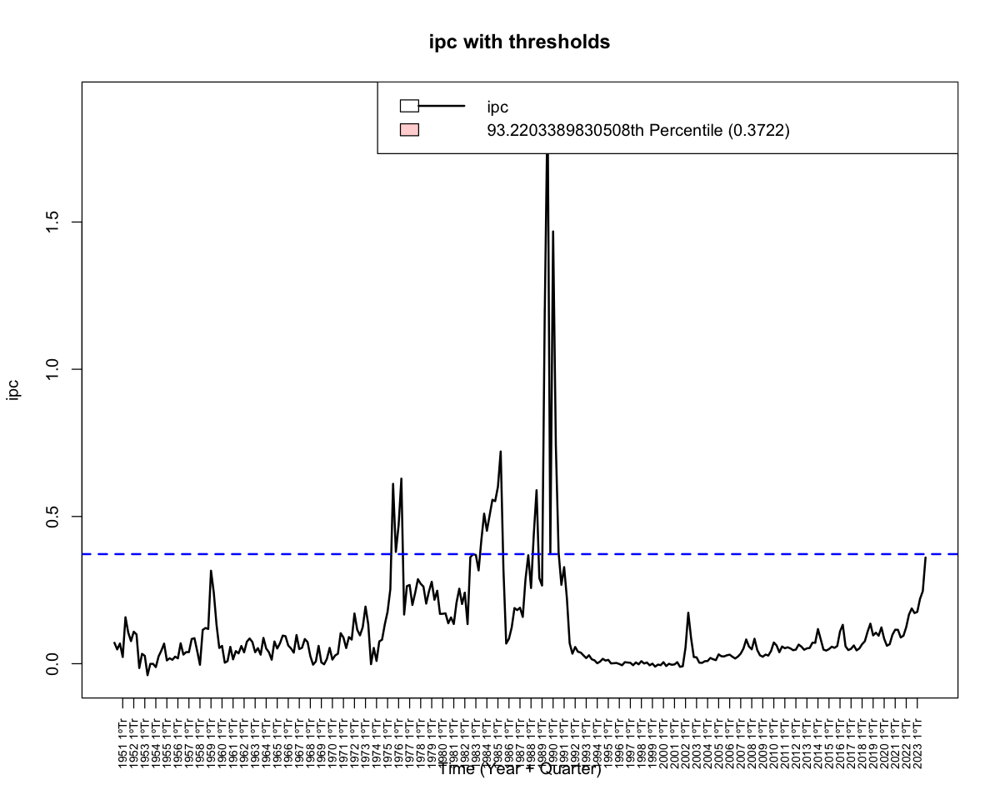

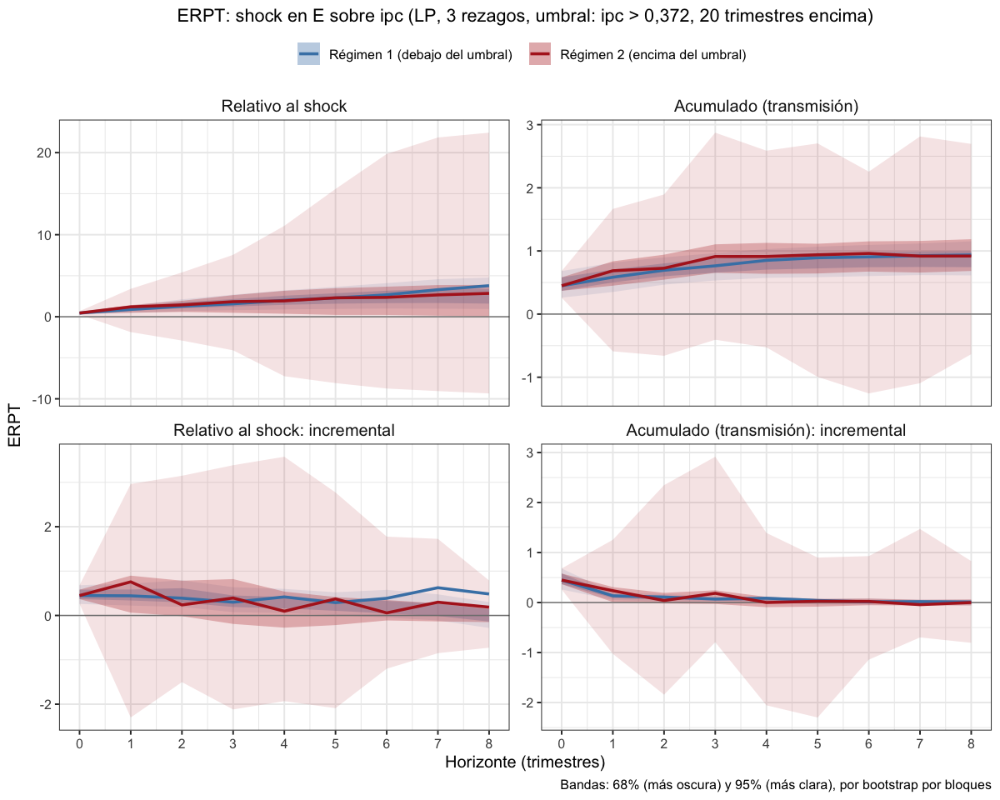

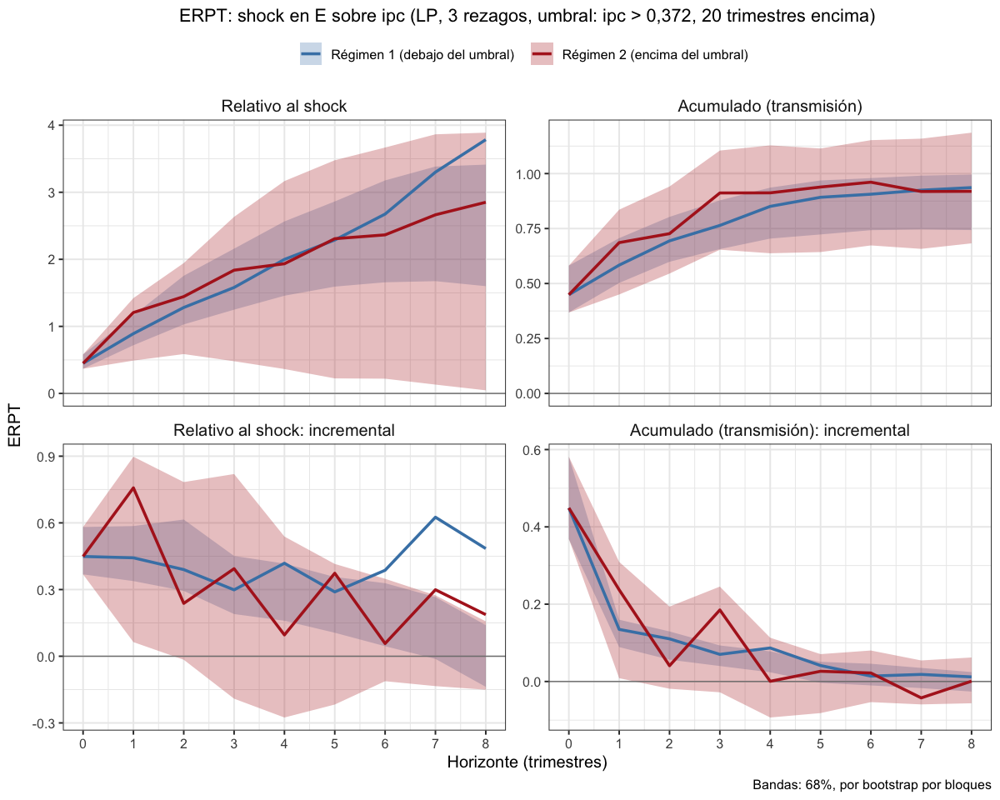

In [14]:
# Todas endógenas con umbral en 37,6% de inflación trimestral (umbral del TVAR-indt), 3 rezagos
lp_erpt_endog_p3_tvar37.6 <- erpt_lp(df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                                     fixed_lags = 3, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.932203389830508)
saveRDS(lp_erpt_endog_p3_tvar37.6, "lp_erpt_endog_p3_tvar37.6.rds")
graficar_erpt_lp(lp_erpt_endog_p3_tvar37.6, archivo = "lp_erpt_endog_p3_tvar37.6")
graficar_erpt_lp(lp_erpt_endog_p3_tvar37.6, niveles = 0.68, archivo = "lp_erpt_endog_p3_tvar37.6_68")

### impp_usa 1950 a 2023 - 1 exógena y el resto endógenas - Selected orders: 2 y 5

### 1 exógena y el resto endógenas - 2 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.45749761,0.45749761,0.45749761,0.4574976,0.45749761,0.4574976
2,1,0.29034112,0.20803749,0.37264476,0.5517323,0.21514554,0.8883190
3,2,0.17402621,0.04826138,0.29979105,0.1952958,-0.14302273,0.5336144
4,3,0.12791141,-0.01001475,0.26583757,0.4037421,0.11183379,0.6956504
5,4,0.03795588,-0.10491676,0.18082851,0.2964406,0.08101739,0.5118638
6,5,-0.05670296,-0.24973305,0.13632713,0.2077226,0.06022773,0.3552175
7,6,-0.04021823,-0.21928521,0.13884875,0.1385380,-0.02583258,0.3029085
8,7,-0.01539892,-0.22068290,0.18988506,0.2571480,0.06944315,0.4448529
9,8,-0.24438140,-0.47747864,-0.01128417,0.1377636,0.02742272,0.2481045


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.035019959,-0.035019959,-0.035019959,-0.035019959,-0.035019959,-0.03501996
11,1,0.015895795,-0.035632074,0.067423664,-0.021954008,-0.054460029,0.01055201
12,2,-0.044555220,-0.084368558,-0.004741882,0.012534283,-0.008765135,0.03383370
13,3,-0.085829647,-0.144861654,-0.026797639,-0.020561165,-0.051493619,0.01037129
14,4,-0.011031142,-0.064741917,0.042679632,-0.004121263,-0.018950649,0.01070812
15,5,0.058406728,-0.009978193,0.126791650,0.019054223,0.005460913,0.03264753
16,6,0.023599086,-0.028678166,0.075876337,0.008138798,-0.006430093,0.02270769
17,7,-0.009911254,-0.075952991,0.056130484,-0.003390730,-0.019550017,0.01276856
18,8,-0.024436463,-0.076249621,0.027376694,0.015994773,0.002591632,0.02939791


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.0000000,0.00000000,0.00000000,0.0000000,0.0000000
38,1,-0.8399393,-1.2072263,-0.47265238,-0.90275597,-2.1060562,0.3005443
39,2,-1.0789187,-1.6309159,-0.52692147,1.35462255,0.5983375,2.1109076
40,3,-0.5243211,-0.8844406,-0.16420168,-0.27606523,-1.6706413,1.1185109
41,4,-0.5172797,-0.9024983,-0.13206108,-0.15590162,-1.5445128,1.2327095
42,5,0.1282954,-0.3567354,0.61332621,1.53793294,0.2834601,2.7924058
43,6,-0.3556508,-0.6739642,-0.03733743,-1.12141735,-2.6109828,0.3681481
44,7,-0.6485701,-1.0820259,-0.21511426,-0.02428799,-1.0162735,0.9676975
45,8,-1.0064786,-1.4064671,-0.60649006,3.50930720,1.3459793,5.6726351


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000
47,1,-0.1294488,-0.2506354,-0.00826219,0.1179023,-0.6074324,0.8432370
48,2,-0.3657372,-0.6137802,-0.11769430,1.1999718,0.6055918,1.7943518
49,3,-0.2445320,-0.4295291,-0.05953488,0.2312929,-0.7676331,1.2302190
50,4,-0.4080447,-0.6417492,-0.17434027,0.4666603,-0.6896870,1.6230077
51,5,-0.3246341,-0.5817289,-0.06753932,1.0561859,0.2128955,1.8994763
52,6,-0.2847643,-0.5474820,-0.02204658,0.3565921,-0.7373114,1.4504955
53,7,-0.2441657,-0.4715154,-0.01681609,-0.6389615,-1.8038129,0.5258899
54,8,-0.4162584,-0.7094605,-0.12305634,2.5770363,0.9893975,4.1646751


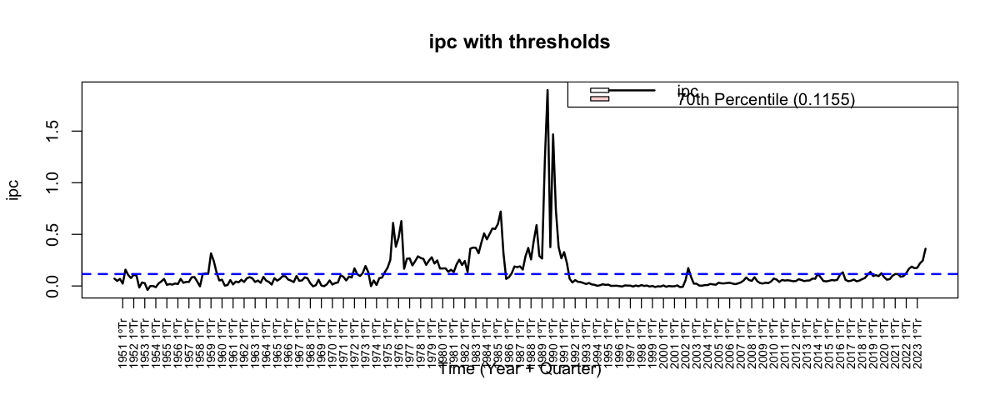

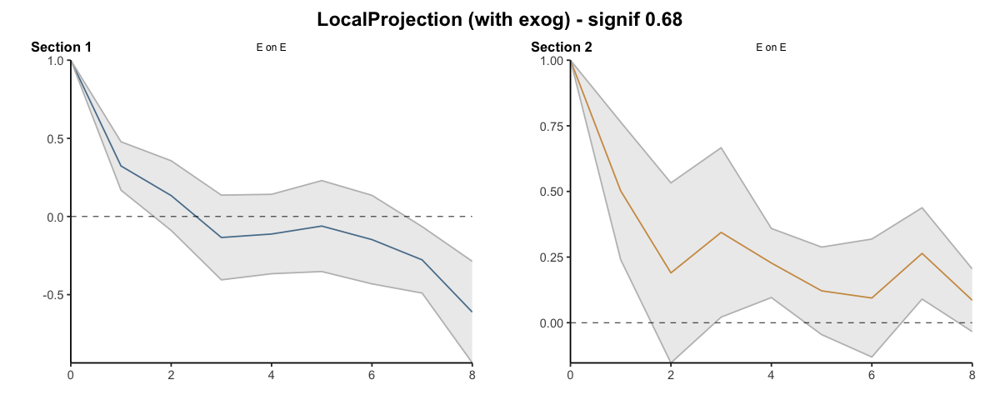

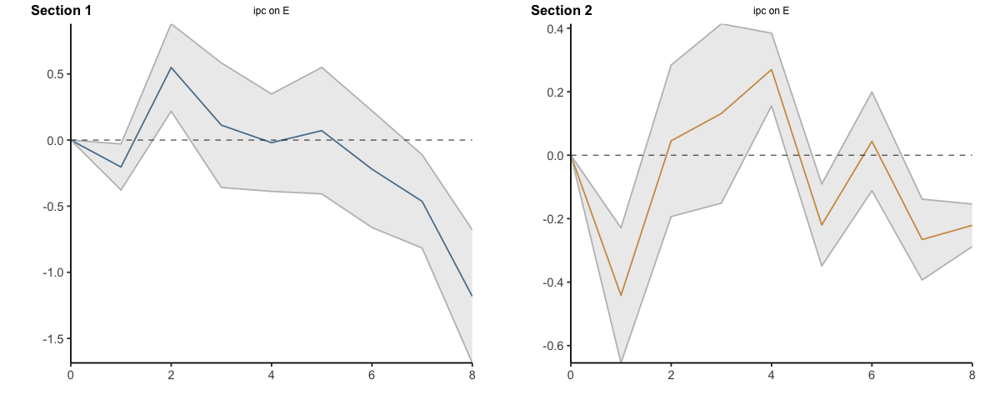

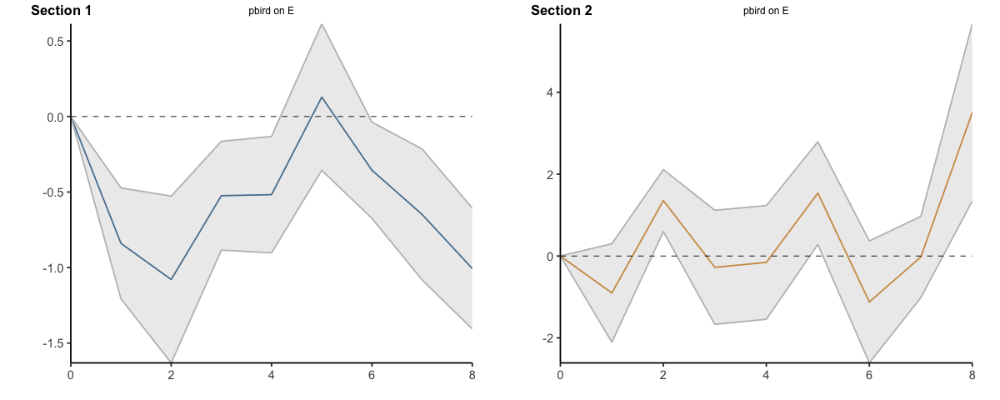

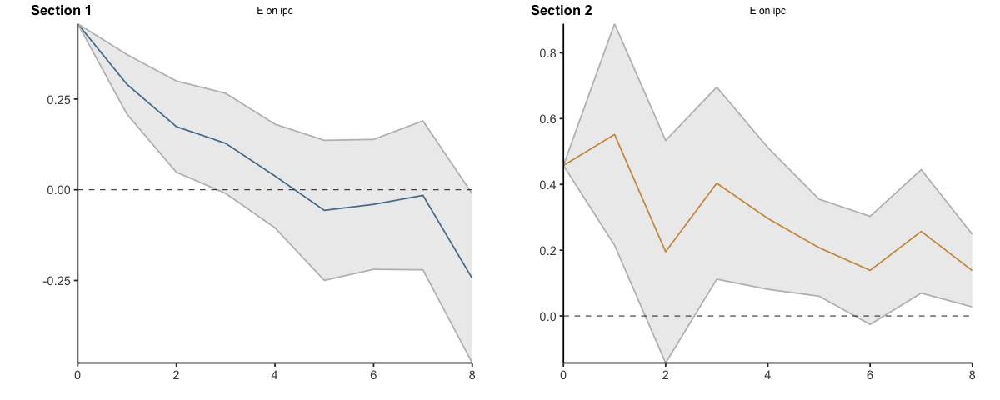

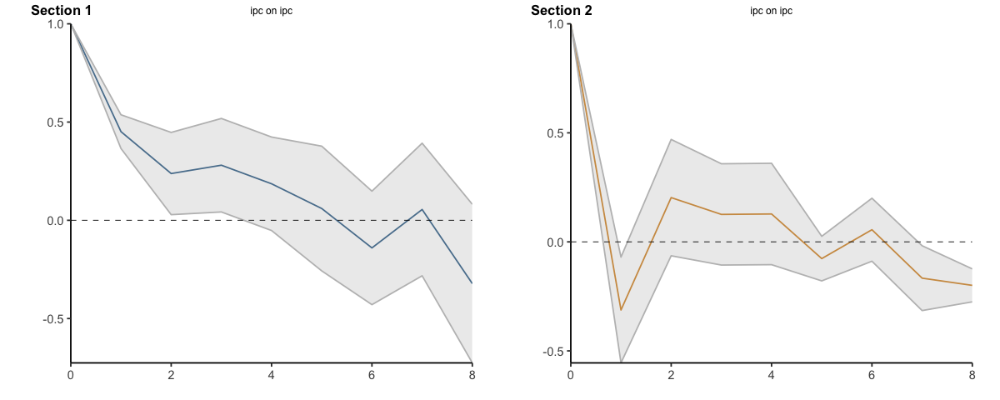

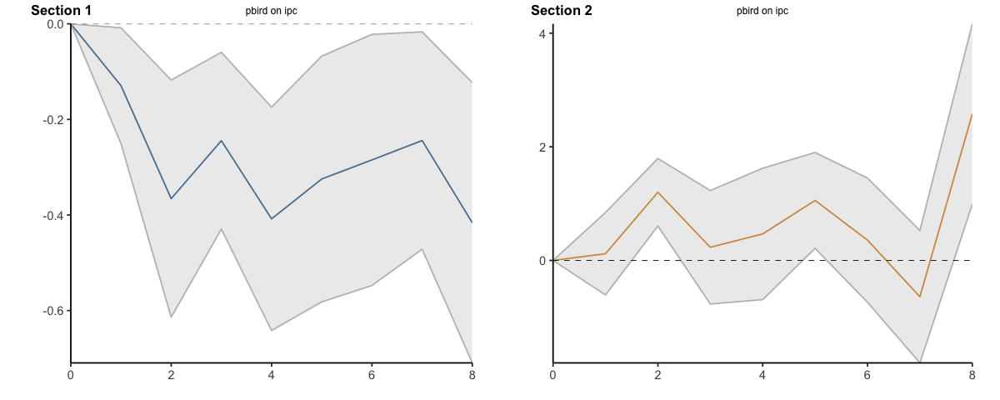

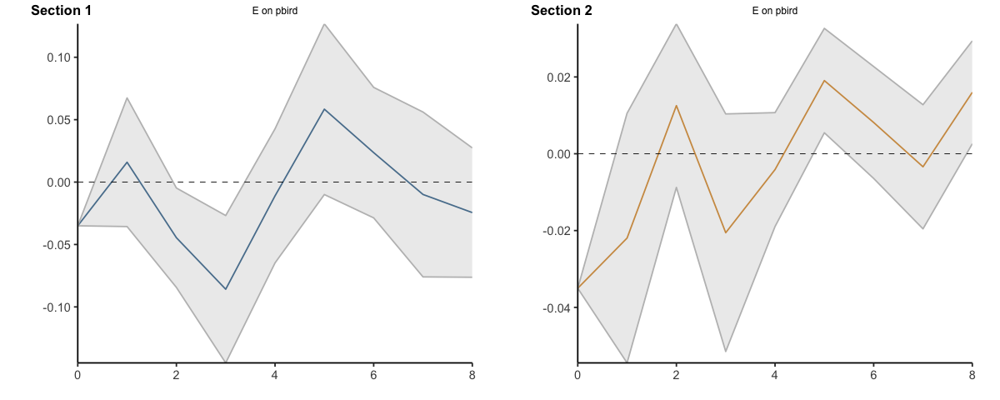

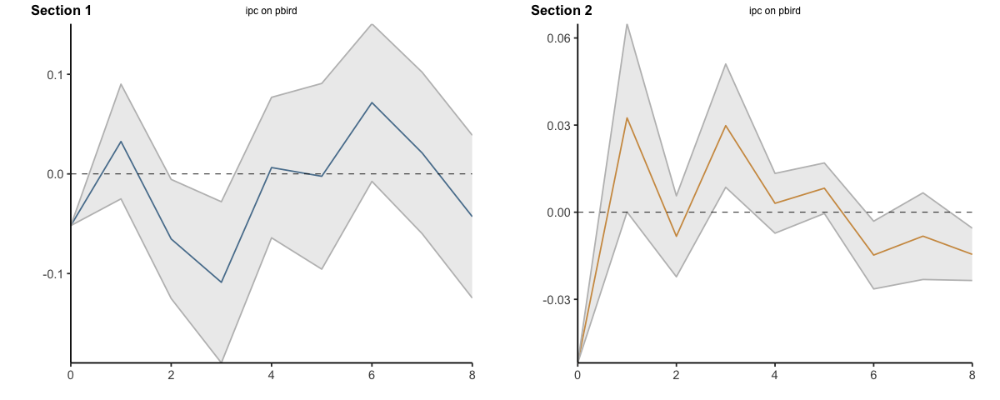

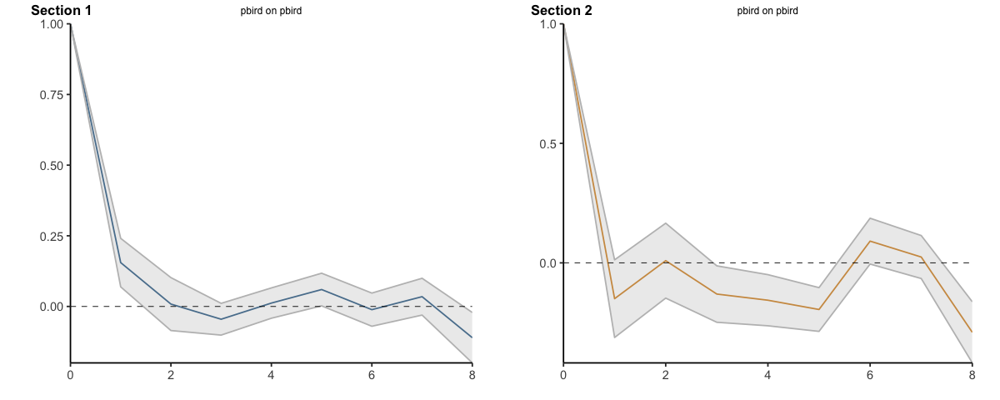

In [33]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,2,NaN,NA,2,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4574976,0.45749761,0.4574976,0.4574976,0.4574976,0.4574976
2,1,0.7478387,0.66553510,0.8301424,1.0092299,0.6726432,1.3458166
3,2,0.9218650,0.71379648,1.1299334,1.2045257,0.5296204,1.8794310
4,3,1.0497764,0.70378172,1.3957710,1.6082678,0.6414542,2.5750814
5,4,1.0877322,0.59886497,1.5765995,1.9047084,0.7224716,3.0869453
6,5,1.0310293,0.34913191,1.7129266,2.1124310,0.7826993,3.4421628
7,6,0.9908110,0.12984671,1.8517754,2.2509690,0.7568668,3.7450713
8,7,0.9754121,-0.09083619,2.0416604,2.5081170,0.8263099,4.1899242
9,8,0.7310307,-0.56831483,2.0303763,2.6458807,0.8537326,4.4380287


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03501996,-0.03501996,-0.0350199590,-0.03501996,-0.03501996,-0.035019959
11,1,-0.01912416,-0.07065203,0.0324037050,-0.05697397,-0.08947999,-0.024467946
12,2,-0.06367938,-0.15502059,0.0276618230,-0.04443968,-0.09824512,0.009365756
13,3,-0.14950903,-0.29988225,0.0008641841,-0.06500085,-0.14973874,0.019737045
14,4,-0.16054017,-0.36462416,0.0435438162,-0.06912211,-0.16868939,0.030445168
15,5,-0.10213344,-0.37460236,0.1703354665,-0.05006789,-0.16322848,0.063092701
16,6,-0.07853436,-0.40328052,0.2462118040,-0.04192909,-0.16965857,0.085800390
17,7,-0.08844561,-0.47923351,0.3023422881,-0.04531982,-0.18920859,0.098568948
18,8,-0.11288208,-0.55548313,0.3297189818,-0.02932505,-0.18661696,0.127966862


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.000000,0.0000000,0.00000000,0.000000,0.0000000
38,1,-0.8399393,-1.207226,-0.4726524,-0.90275597,-2.106056,0.3005443
39,2,-1.9188580,-2.838142,-0.9995739,0.45186658,-1.507719,2.4114519
40,3,-2.4431792,-3.722583,-1.1637755,0.17580135,-3.178360,3.5299627
41,4,-2.9604589,-4.625081,-1.2958366,0.01989973,-4.722873,4.7626723
42,5,-2.8321635,-4.981817,-0.6825104,1.55783267,-4.439413,7.5550781
43,6,-3.1878143,-5.655781,-0.7198478,0.43641533,-7.050396,7.9232262
44,7,-3.8363843,-6.737807,-0.9349621,0.41212734,-8.066669,8.8909237
45,8,-4.8428629,-8.144274,-1.5414522,3.92143454,-6.720690,14.5635589


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.0000000,0.00000000,0.0000000,0.000000000,0.000000
47,1,-0.1294488,-0.2506354,-0.00826219,0.1179023,-0.607432354,0.843237
48,2,-0.4951860,-0.8644155,-0.12595649,1.3178741,-0.001840552,2.637589
49,3,-0.7397180,-1.2939446,-0.18549137,1.5491670,-0.769473682,3.867808
50,4,-1.1477627,-1.9356939,-0.35983164,2.0158274,-1.459160694,5.490815
51,5,-1.4723968,-2.5174227,-0.42737096,3.0720133,-1.246265219,7.390292
52,6,-1.7571611,-3.0649047,-0.44941754,3.4286053,-1.983576572,8.840787
53,7,-2.0013268,-3.5364200,-0.46623363,2.7896438,-3.787389495,9.366677
54,8,-2.4175852,-4.2458805,-0.58928997,5.3666801,-2.797991995,13.531352


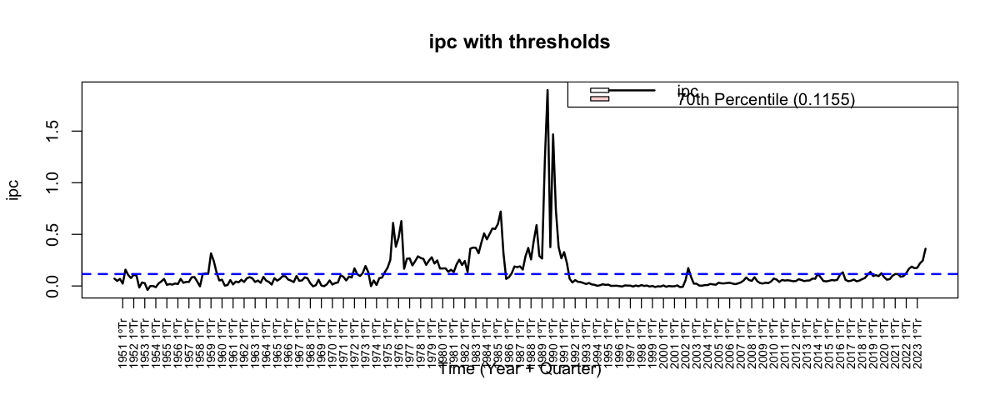

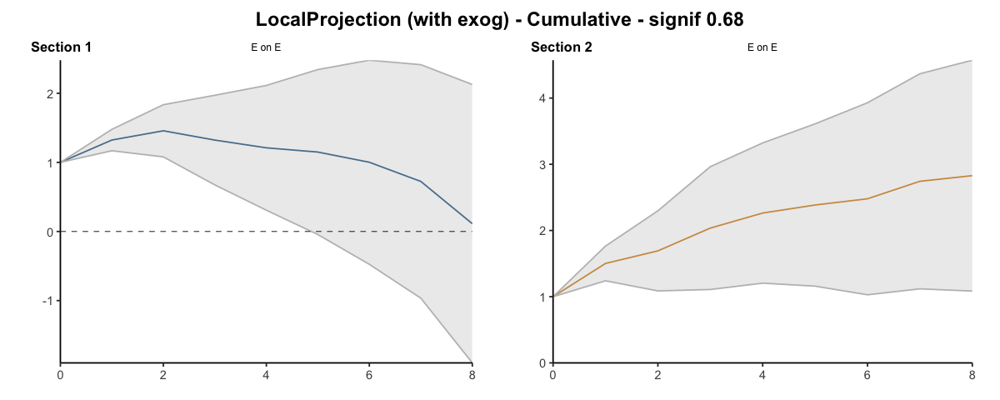

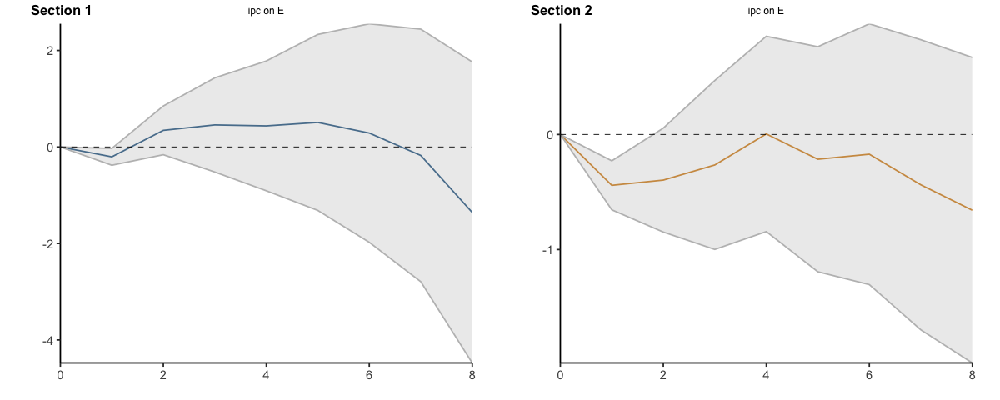

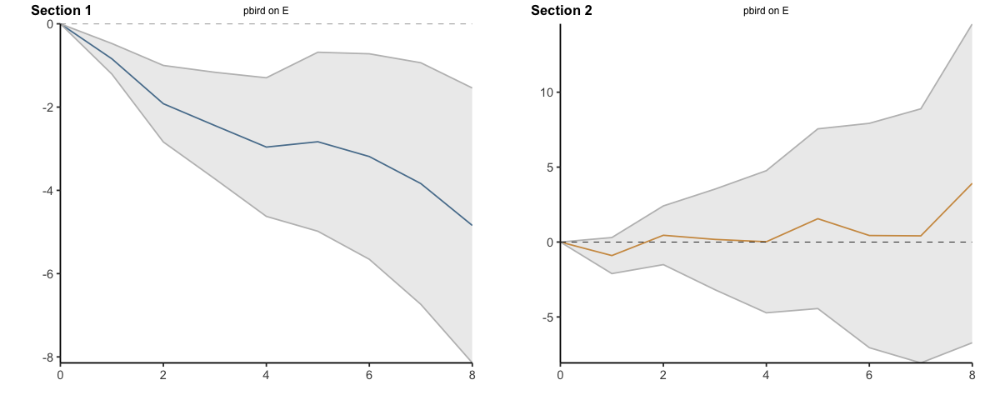

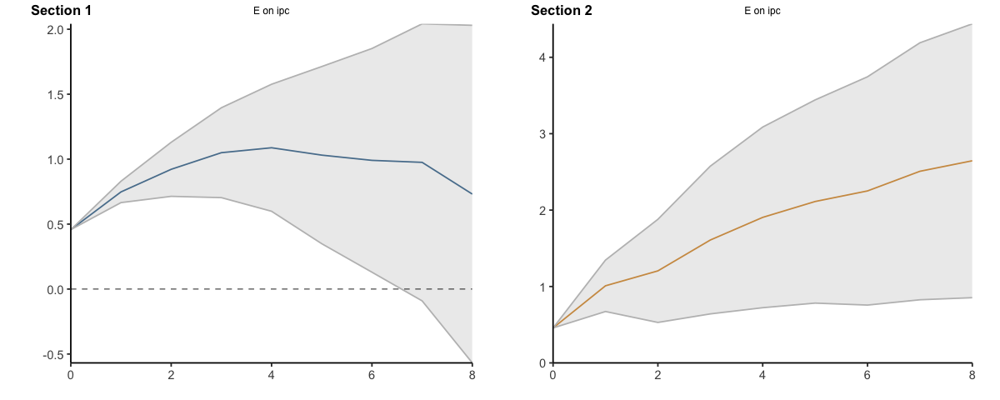

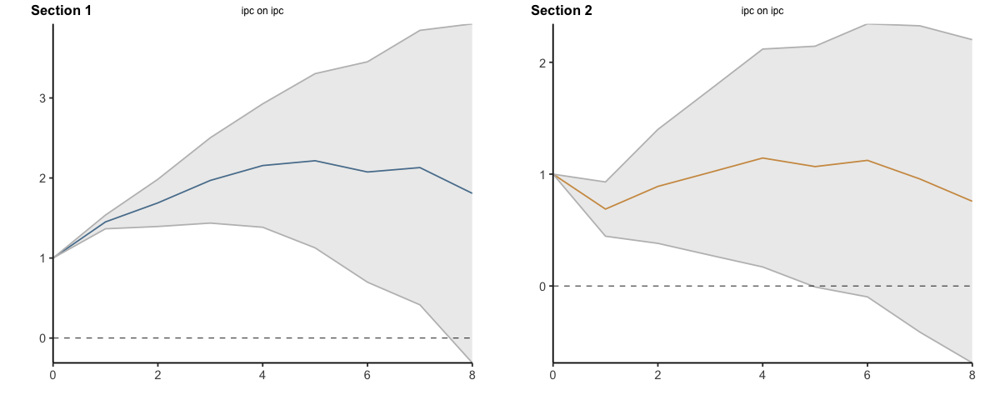

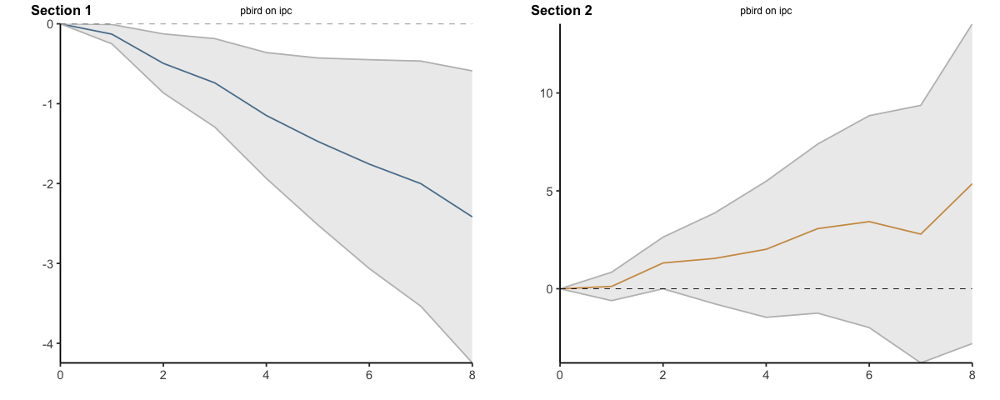

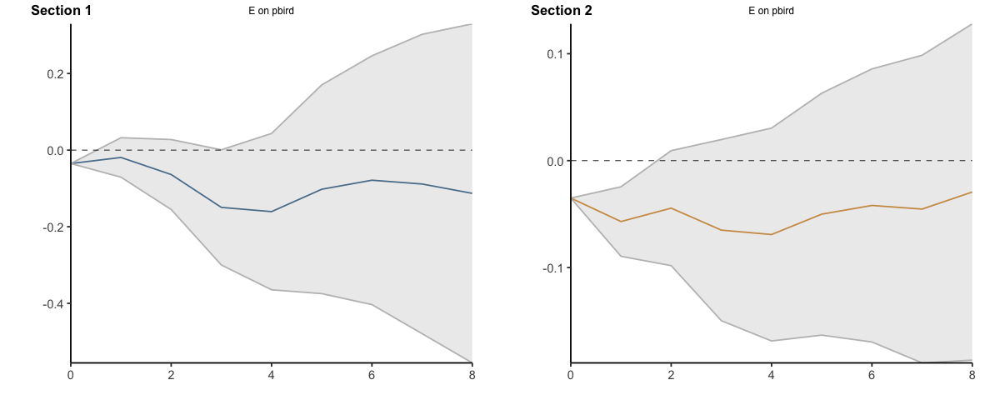

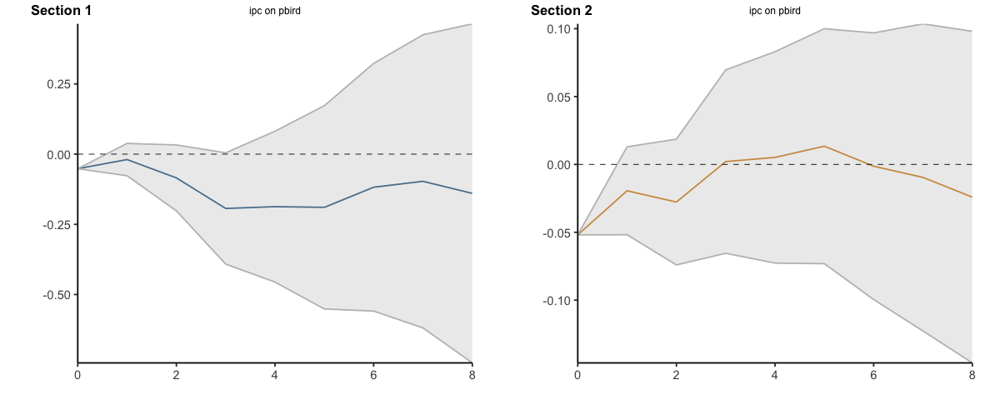

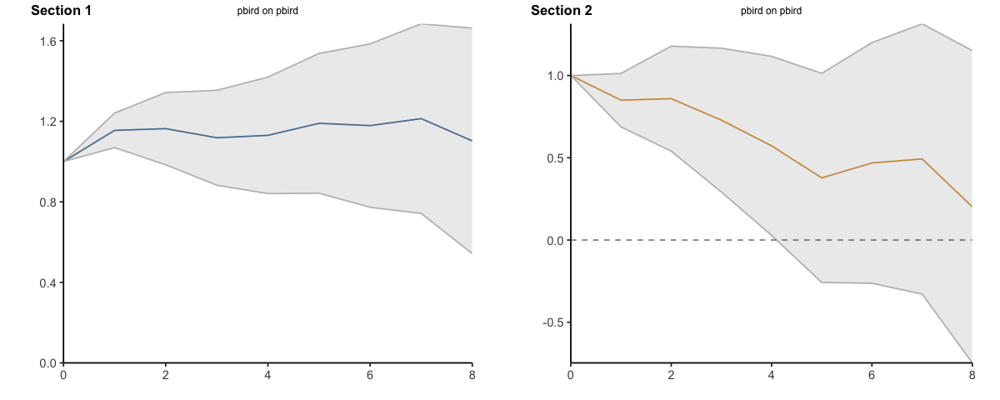

In [34]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 2, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

#### Percentile 70 - 2 lags

Umbral: ipc > 0.1155 (percentil 70 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 206 | encima del umbral (dummy = 1) = 89 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,115, 89 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4575         0.4575       1.0000
         1              0.7478         0.5651       1.3234
         2              0.9219         0.6327       1.4571
         3              1.0498         0.7936       1.3227
         4              1.0877         0.8985       1.2106
         5              1.0310         0.8970       1.1494
         6              0.9908         0.9891       1.0017
         7              0.9754         1.3466       0.7244
         8              0.7310         6.4961       0.1125
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4575             0.4575
                  0.2903             0.1076
                  0.1740             0.0676
 

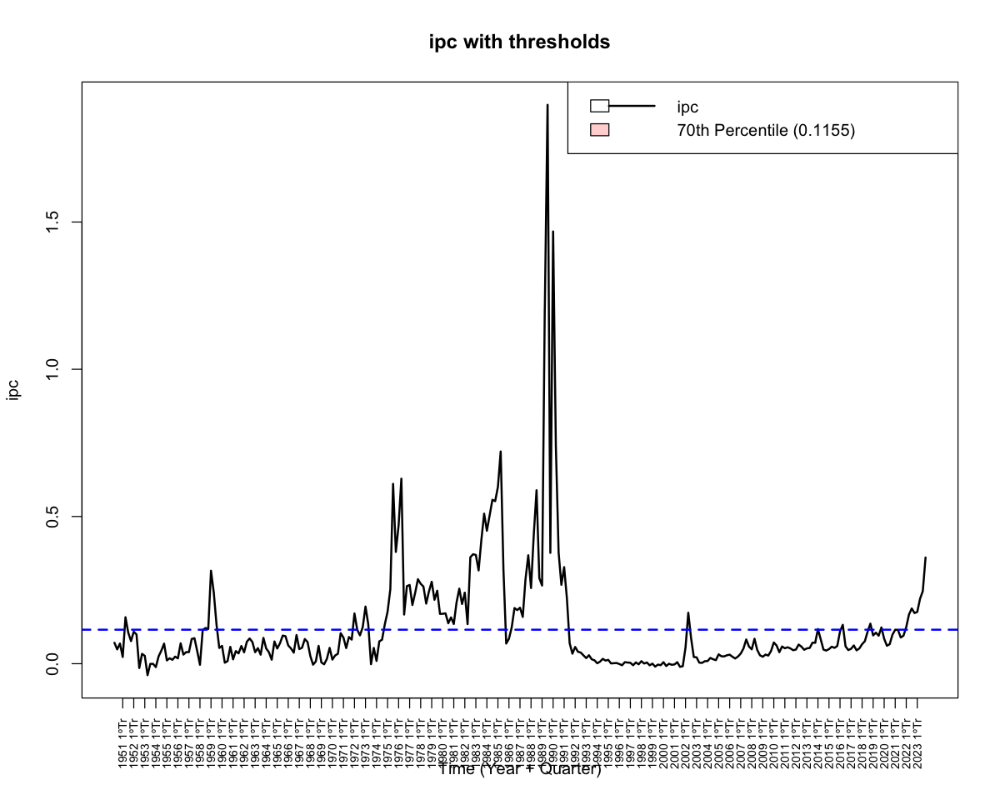

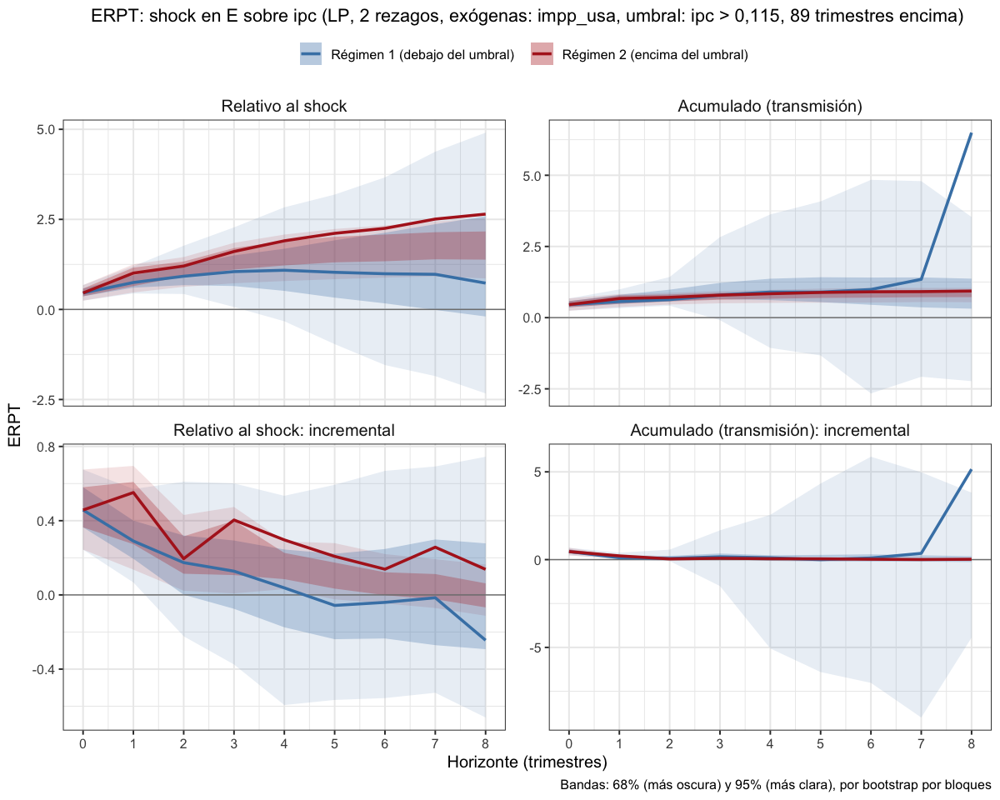

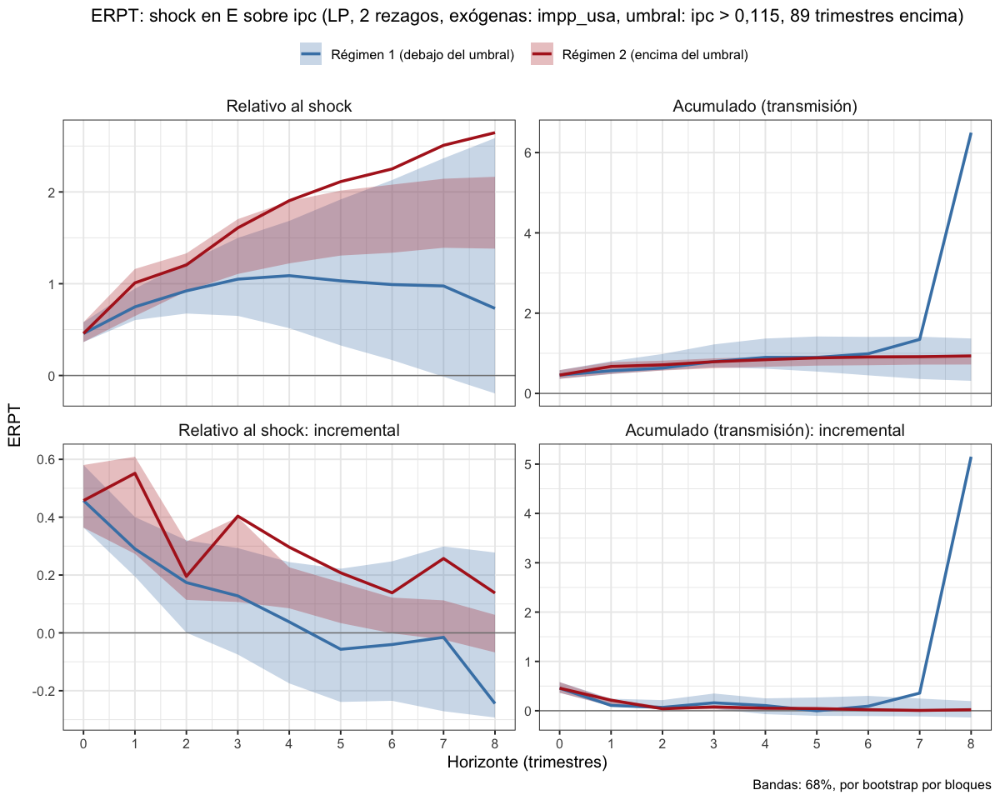

In [15]:
# 1 exógena y el resto endógenas con umbral en el percentil 70 del ipc, 2 rezagos
lp_erpt_exog_p2_u70 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                                fixed_lags = 2, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.7)
saveRDS(lp_erpt_exog_p2_u70, "lp_erpt_exog_p2_u70.rds")
graficar_erpt_lp(lp_erpt_exog_p2_u70, archivo = "lp_erpt_exog_p2_u70")
graficar_erpt_lp(lp_erpt_exog_p2_u70, niveles = 0.68, archivo = "lp_erpt_exog_p2_u70_68")

### Percentile 0,725423728813559 (12,5 inflación trimestral) - quedan 81 trimestres por encima del umbral

Umbral: ipc > 0.1265 (percentil 72.5 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 214 | encima del umbral (dummy = 1) = 81 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,127, 81 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4575         0.4575       1.0000
         1              0.8105         0.6166       1.3146
         2              1.0622         0.7158       1.4839
         3              1.2264         0.8694       1.4106
         4              1.2815         0.9964       1.2861
         5              1.2669         1.0074       1.2577
         6              1.2951         1.0749       1.2048
         7              1.3119         1.3216       0.9926
         8              1.1530         2.1760       0.5299
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4575             0.4575
                  0.3530             0.1591
                  0.2516             0.0992
 

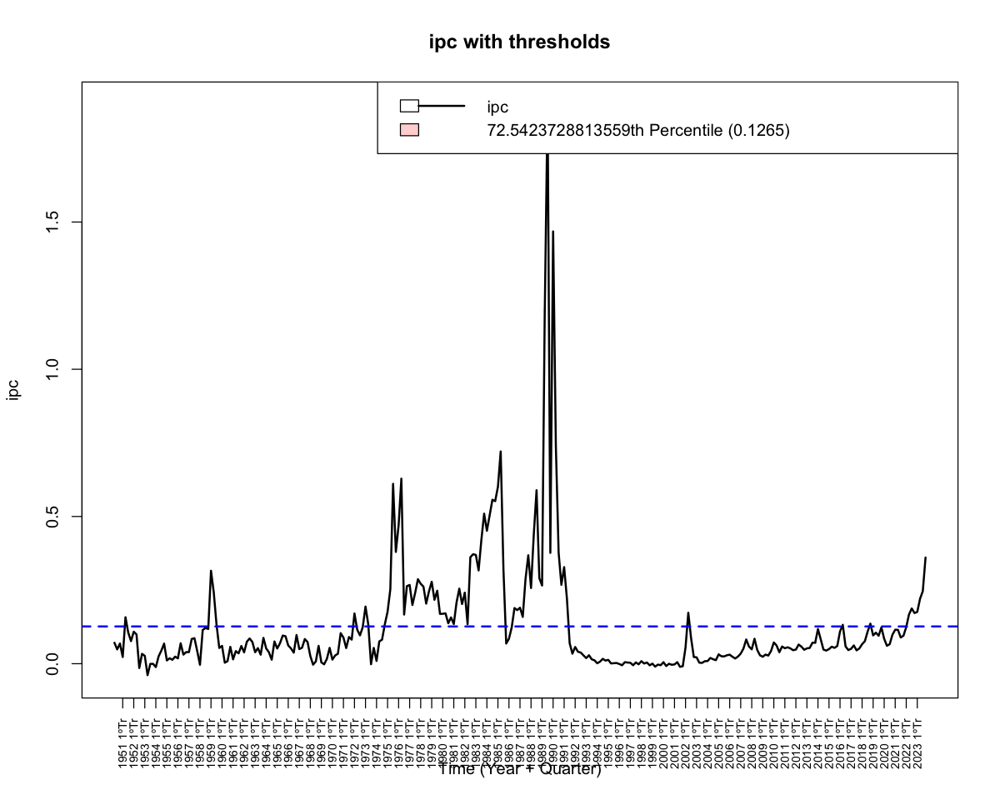

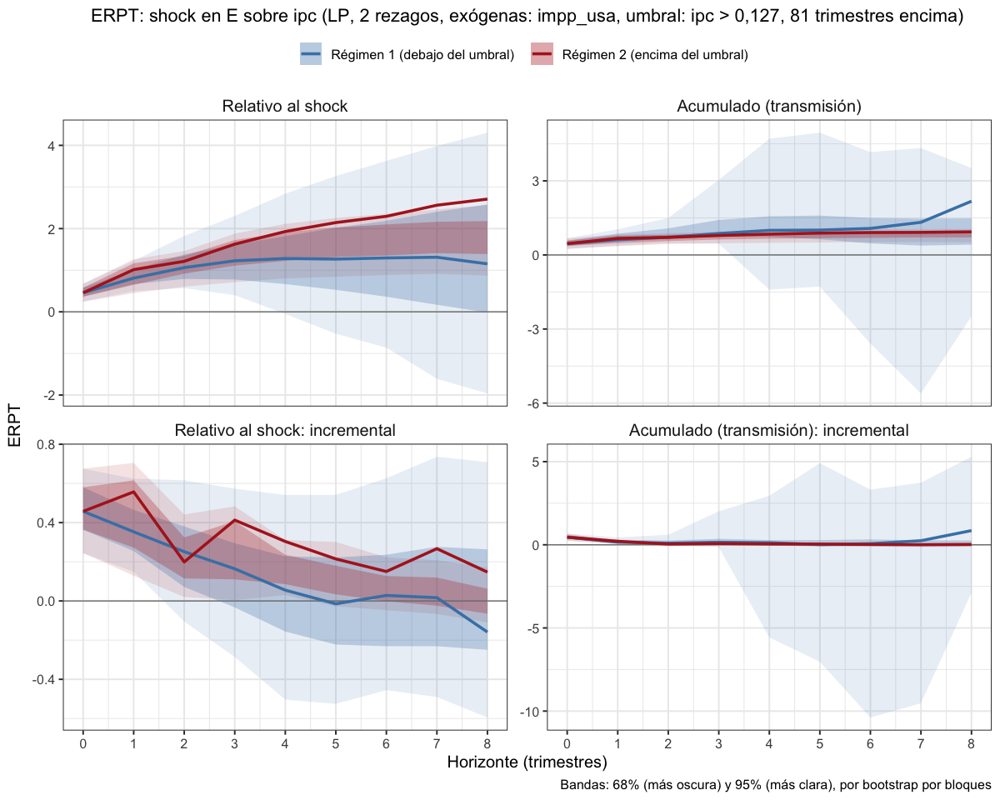

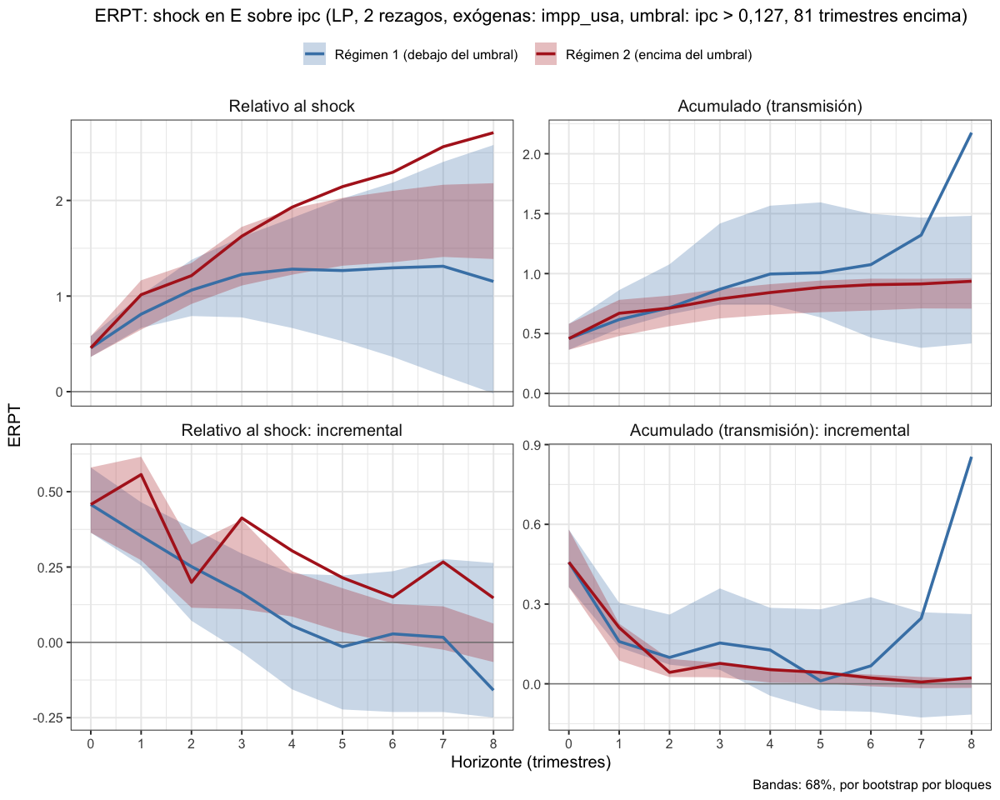

In [16]:
# 1 exógena y el resto endógenas con umbral en en 12,5% de inflación trimestral (umbral del TVAR), 2 rezagos
lp_erpt_exog_p2_tvar12.5 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"), 
                                     fixed_lags = 2, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.725423728813559)
saveRDS(lp_erpt_exog_p2_tvar12.5, "lp_erpt_exog_p2_tvar12.5.rds")
graficar_erpt_lp(lp_erpt_exog_p2_tvar12.5, archivo = "lp_erpt_exog_p2_tvar12.5")
graficar_erpt_lp(lp_erpt_exog_p2_tvar12.5, niveles = 0.68, archivo = "lp_erpt_exog_p2_tvar12.5_68")

#### Percentile 0.932203389830508 (37,6% inflación trimestral) - quedan 20 trimestres por encima del umbral (es poco)

Umbral: ipc > 0.3722 (percentil 93.2 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 275 | encima del umbral (dummy = 1) = 20 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%


3 réplicas fallaron y se descartaron.



ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,372, 20 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4575         0.4575       1.0000
         1              0.9298         0.5914       1.5721
         2              1.3475         0.7020       1.9194
         3              1.6467         0.7656       2.1508
         4              2.0926         0.8516       2.4573
         5              2.3976         0.8924       2.6867
         6              2.7882         0.9088       3.0680
         7              3.4138         0.9247       3.6918
         8              3.9116         0.9333       4.1911
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4575             0.4575
                  0.4723             0.1339
                  0.4177             0.1106
                  0.2992             0.0636
                  0.4459             

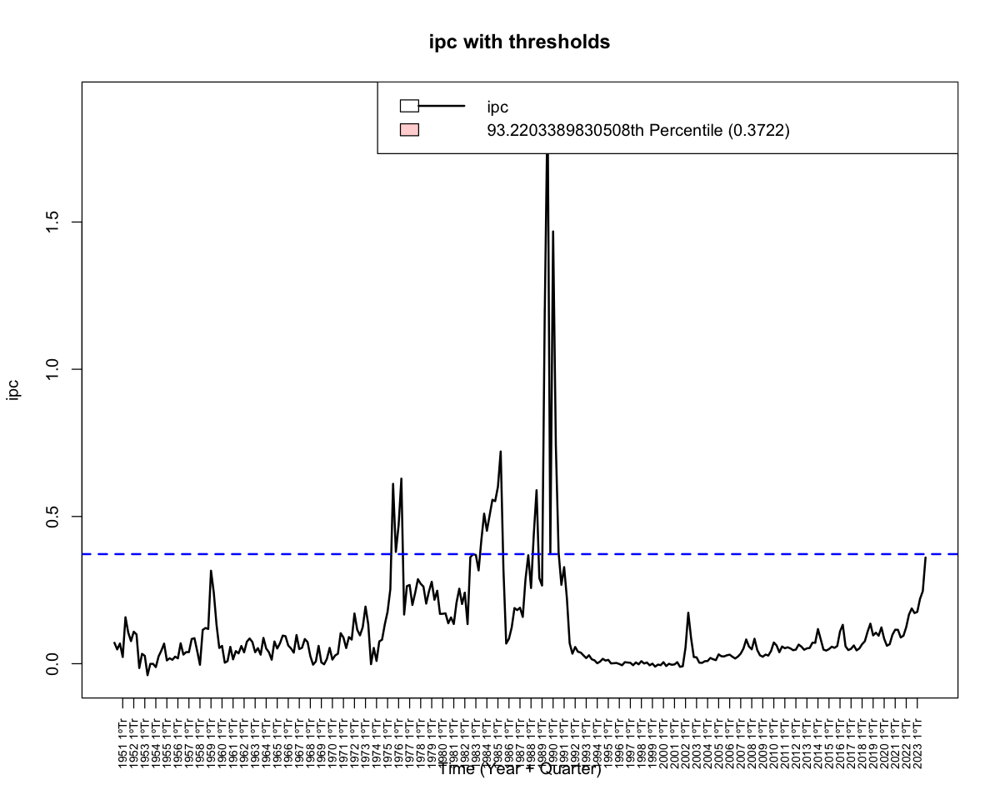

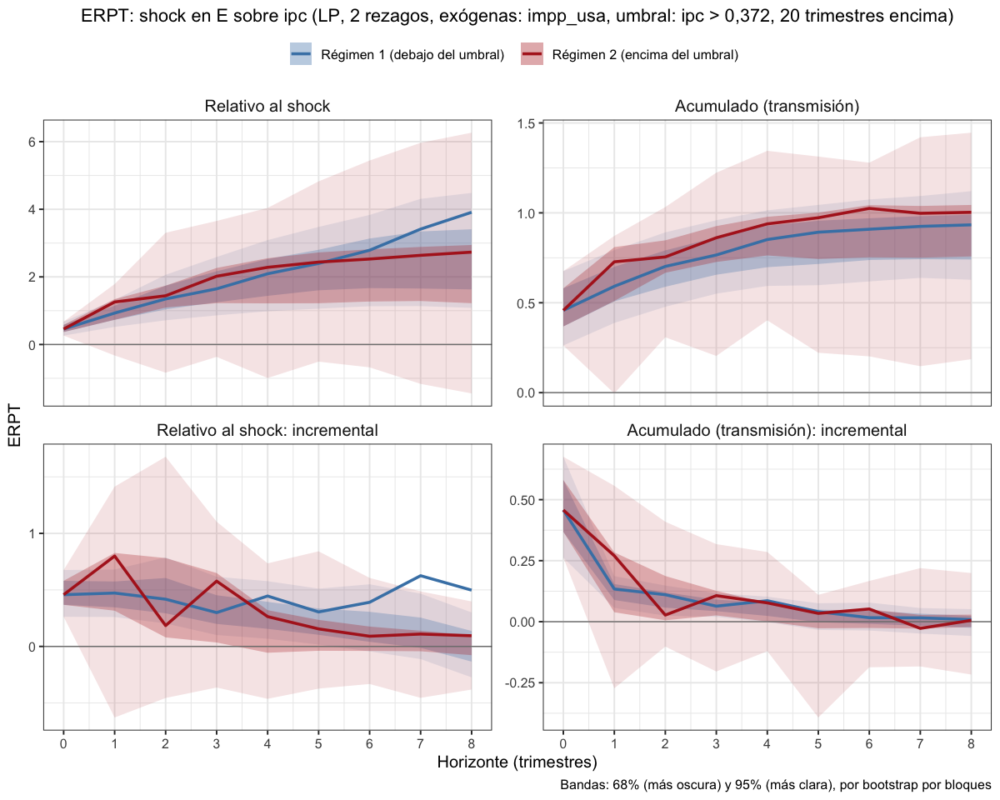

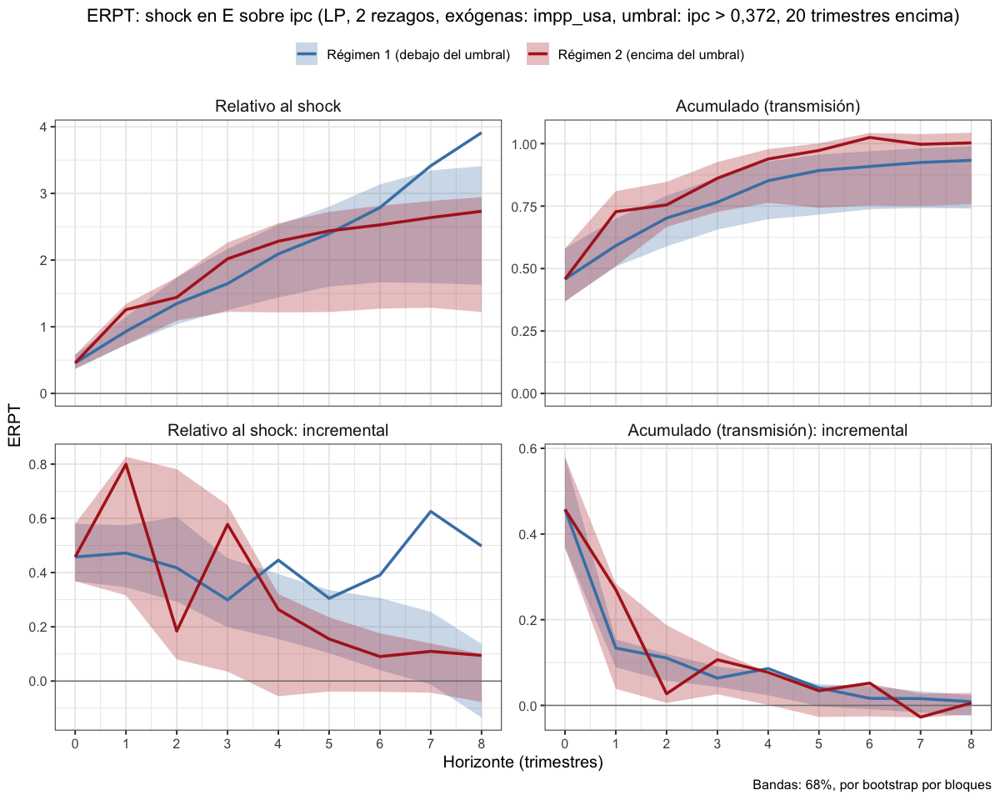

In [18]:
# 1 exógena y el resto endógenas con umbral en 37,6% de inflación trimestral (umbral del TVAR-indt), 2 rezagos
lp_erpt_exog_p2_tvar37.6 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                                    fixed_lags = 2, horizons = 8, reps = 500,
                                    threshold_var = "ipc", upper_threshold = 0.932203389830508)
saveRDS(lp_erpt_exog_p2_tvar37.6, "lp_erpt_exog_p2_tvar37.6.rds")
graficar_erpt_lp(lp_erpt_exog_p2_tvar37.6, archivo = "lp_erpt_exog_p2_tvar37.6")
graficar_erpt_lp(lp_erpt_exog_p2_tvar37.6, niveles = 0.68, archivo = "lp_erpt_exog_p2_tvar37.6_68")

### 1 exógena y el resto endógenas - 5 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,5,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.434994713,0.434994713,0.43499471,0.4349947,0.434994713,0.4349947
2,1,0.319081192,0.227002530,0.41115985,0.5821183,0.331964820,0.8322719
3,2,0.177147292,0.044557297,0.30973729,0.2274005,-0.009385357,0.4641864
4,3,0.112018993,-0.056389534,0.28042752,0.4672544,0.237610732,0.6968981
5,4,0.127142083,-0.008783556,0.26306772,0.3361826,0.161351364,0.5110138
6,5,0.003124894,-0.184210461,0.19046025,0.2654502,0.098984475,0.4319160
7,6,-0.032298679,-0.218490948,0.15389359,0.1395650,-0.087552213,0.3666821
8,7,0.007938149,-0.179389931,0.19526623,0.3251148,0.096781648,0.5534480
9,8,-0.147394473,-0.355430366,0.06064142,0.1926800,0.050731039,0.3346289


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03149282,-0.031492818,-0.03149282,-0.031492818,-0.0314928184,-0.031492818
11,1,0.01962149,-0.034872950,0.07411593,-0.023615644,-0.0451023192,-0.002128969
12,2,-0.04628148,-0.088103876,-0.00445908,0.011818299,-0.0044603956,0.028096994
13,3,-0.07119887,-0.124896562,-0.01750117,-0.026394676,-0.0610660060,0.008276654
14,4,-0.04214584,-0.097331493,0.01303980,-0.006004177,-0.0227921399,0.010783786
15,5,0.06930498,0.001153471,0.13745649,0.012802358,-0.0026557591,0.028260476
16,6,0.01115786,-0.039289077,0.06160480,0.001838946,-0.0119129954,0.015590888
17,7,0.01626533,-0.045282732,0.07781339,-0.013545999,-0.0287944575,0.001702459
18,8,-0.03763023,-0.085521452,0.01026099,0.014810052,-0.0003908753,0.030010980


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.0000000
38,1,-0.7410644,-1.1064962,-0.37563260,-0.2401657,-1.1812838,0.7009524
39,2,-1.0139169,-1.5465440,-0.48128969,1.7804970,0.8850313,2.6759627
40,3,-0.4255061,-0.7727603,-0.07825195,0.1669520,-1.1935891,1.5274932
41,4,-0.2793244,-0.6427111,0.08406238,1.1335335,-0.1084656,2.3755326
42,5,0.2196374,-0.2752394,0.71451428,1.7833371,0.6933166,2.8733576
43,6,-0.4895843,-0.8084596,-0.17070907,-1.7161984,-3.3152554,-0.1171414
44,7,-0.7742219,-1.2231576,-0.32528615,0.4593371,-0.6183804,1.5370546
45,8,-1.0739422,-1.5025502,-0.64533428,4.0852071,1.7353185,6.4350956


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.000000
47,1,-0.1171734,-0.2489515,0.01460481,0.7341448,0.1629178,1.305372
48,2,-0.3040732,-0.5153204,-0.09282596,1.8015185,1.1176845,2.485353
49,3,-0.2330164,-0.4386208,-0.02741197,0.5965730,-0.5036753,1.696821
50,4,-0.2456174,-0.4446708,-0.04656399,1.6470961,0.8261223,2.468070
51,5,-0.1953192,-0.4107462,0.02010784,1.5843893,0.8713625,2.297416
52,6,-0.3391384,-0.5746006,-0.10367631,0.3104547,-0.5465704,1.167480
53,7,-0.3926635,-0.6154050,-0.16992207,-0.4285198,-1.4866205,0.629581
54,8,-0.4363637,-0.7216891,-0.15103821,3.0923350,1.1966207,4.988049


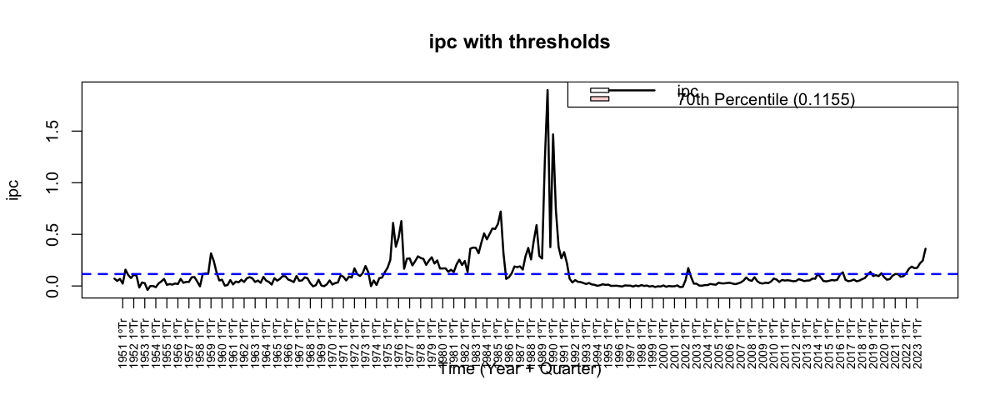

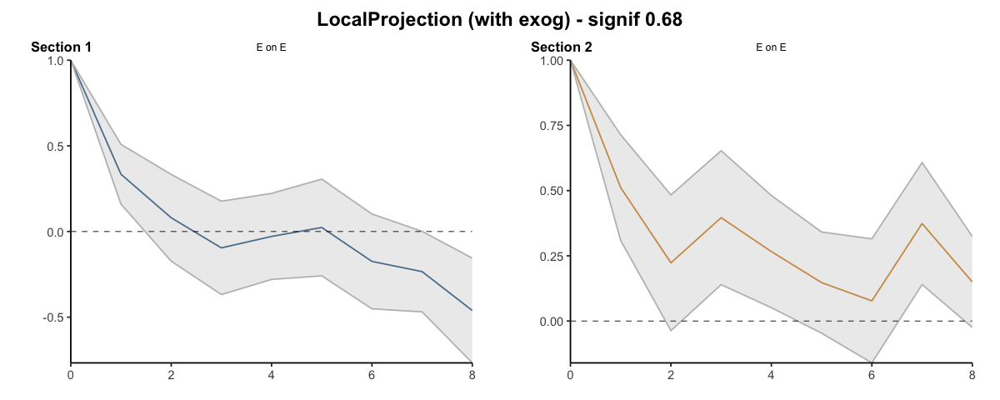

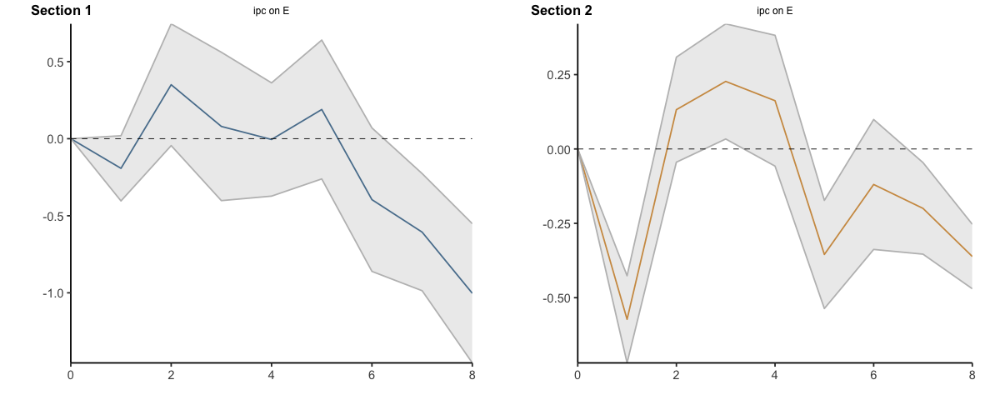

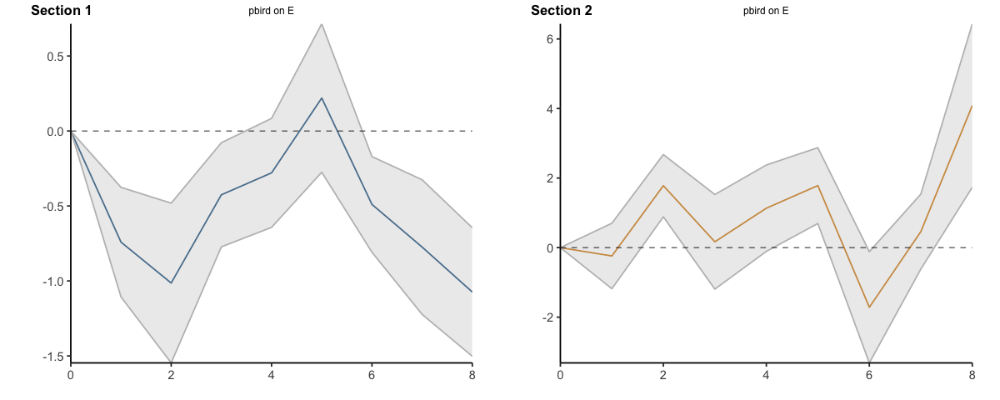

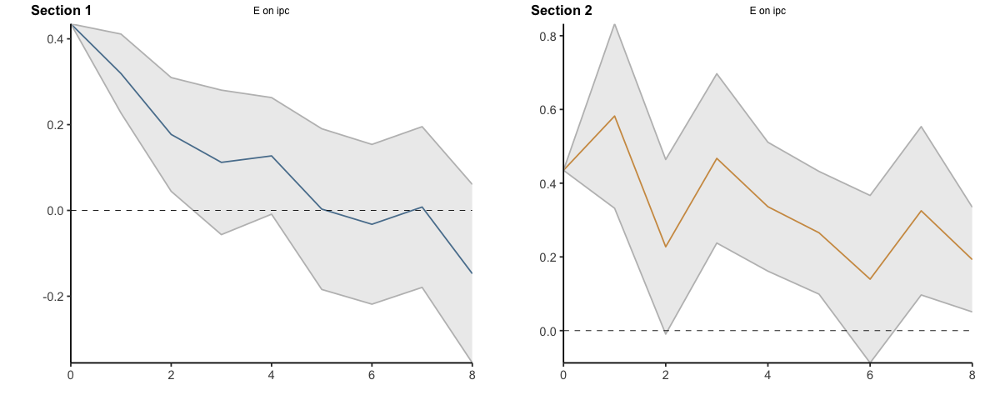

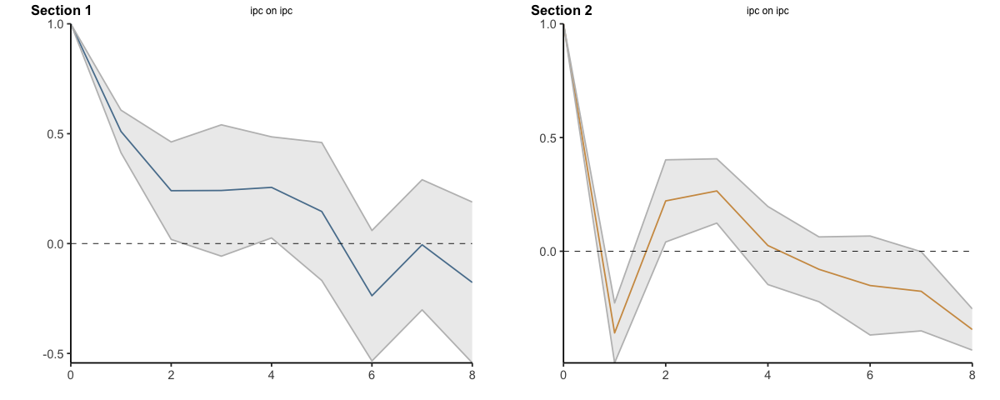

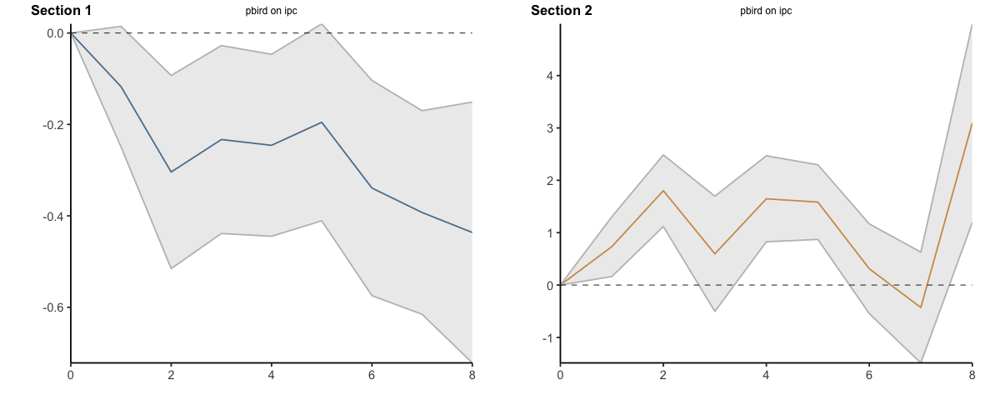

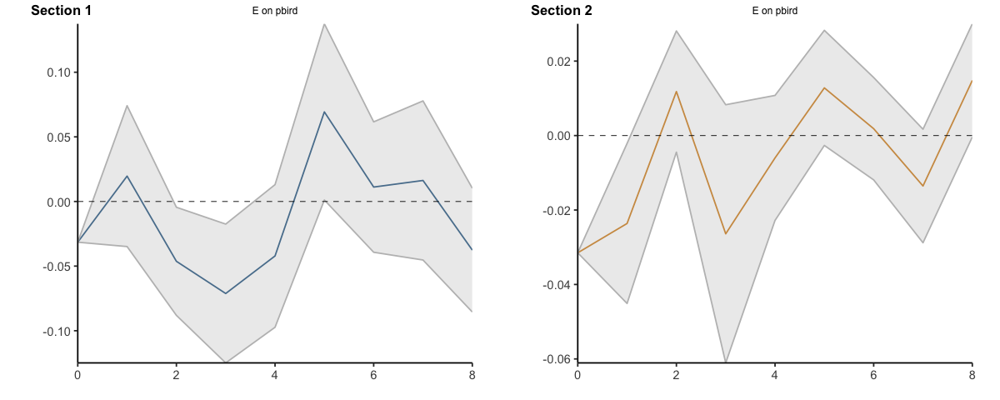

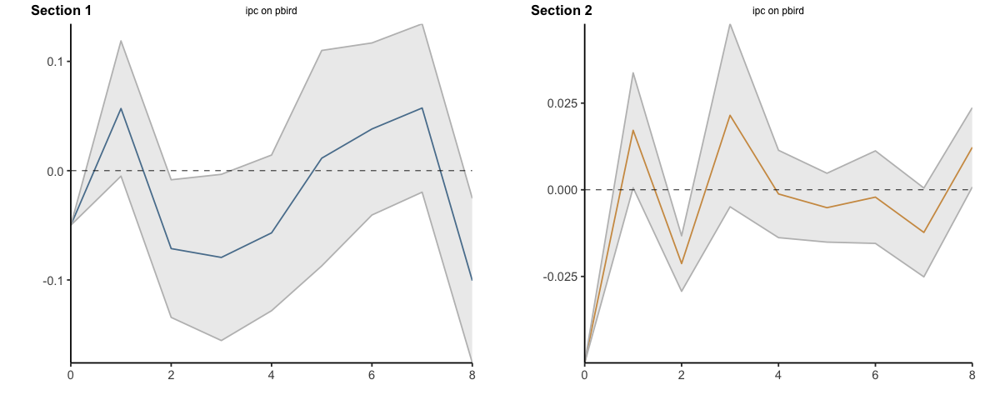

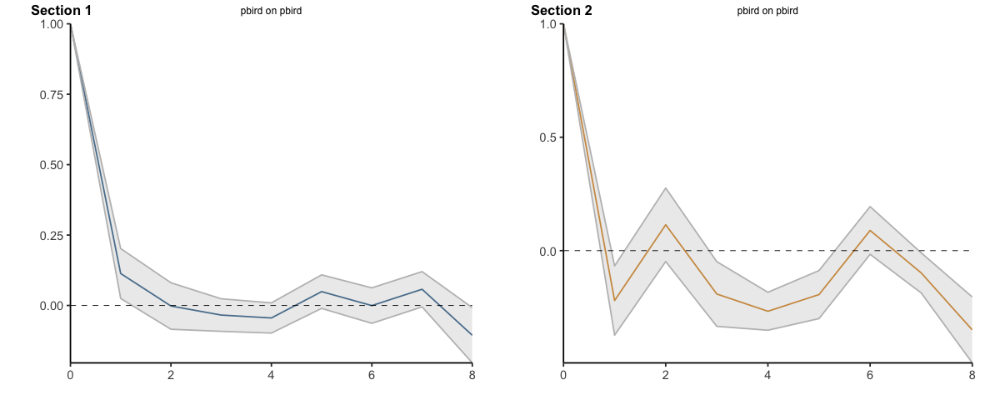

In [40]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<dbl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,5,NaN,NA,5,0,1,0.68,8,TRUE,TRUE,NA,FALSE,FALSE,0,1,295,"E, ipc, pbird",3


Impulse: E -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,0,0.4349947,0.43499471,0.4349947,0.4349947,0.4349947,0.4349947
2,1,0.7540759,0.66199724,0.8461546,1.0171131,0.7669595,1.2672666
3,2,0.9312232,0.70655454,1.1558919,1.2445136,0.7575742,1.7314530
4,3,1.0432422,0.65016501,1.4363194,1.7117680,0.9951849,2.4283511
5,4,1.1703843,0.64138145,1.6993871,2.0479506,1.1565363,2.9393649
6,5,1.1735092,0.45717099,1.8898473,2.3134008,1.2555207,3.3712809
7,6,1.1412105,0.23868004,2.0437409,2.4529658,1.1679685,3.7379630
8,7,1.1491486,0.05929011,2.2390072,2.7780806,1.2647502,4.2914110
9,8,1.0017542,-0.29614026,2.2996486,2.9707606,1.3154812,4.6260400


Impulse: E -> Response: pbird

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
10,0,-0.03149282,-0.03149282,-0.03149282,-0.03149282,-0.03149282,-0.031492818
11,1,-0.01187133,-0.06636577,0.04262312,-0.05510846,-0.07659514,-0.033621787
12,2,-0.05815280,-0.15446964,0.03816403,-0.04329016,-0.08105553,-0.005524793
13,3,-0.12935167,-0.27936621,0.02066287,-0.06968484,-0.14212154,0.002751861
14,4,-0.17149752,-0.37669770,0.03370267,-0.07568902,-0.16491368,0.013535647
15,5,-0.10219254,-0.37554423,0.17115916,-0.06288666,-0.16756944,0.041796123
16,6,-0.09103467,-0.41483330,0.23276396,-0.06104771,-0.17948243,0.057387011
17,7,-0.07476935,-0.46011604,0.31057735,-0.07459371,-0.20827689,0.059089470
18,8,-0.11239958,-0.54563749,0.32083834,-0.05978366,-0.20866777,0.089100450


... (4 outputs left out)

Impulse: pbird -> Response: E

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
37,0,0.0000000,0.000000,0.0000000,0.0000000,0.0000000,0.0000000
38,1,-0.7410644,-1.106496,-0.3756326,-0.2401657,-1.1812838,0.7009524
39,2,-1.7549813,-2.653040,-0.8569223,1.5403313,-0.2962525,3.3769152
40,3,-2.1804874,-3.425801,-0.9351742,1.7072834,-1.4898416,4.9044083
41,4,-2.4598117,-4.068512,-0.8511119,2.8408168,-1.5983072,7.2799409
42,5,-2.2401743,-4.343751,-0.1365976,4.6241539,-0.9049906,10.1532985
43,6,-2.7297586,-5.152211,-0.3073066,2.9079555,-4.2202460,10.0361571
44,7,-3.5039805,-6.375368,-0.6325928,3.3672926,-4.8386265,11.5732116
45,8,-4.5779227,-7.877918,-1.2779271,7.4524996,-3.1033080,18.0083072


Impulse: pbird -> Response: ipc

,horizon,IRF S1,Lower S1,Upper S1,IRF S2,Lower S2,Upper S2
,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
46,0,0.0000000,0.0000000,0.00000000,0.0000000,0.0000000,0.000000
47,1,-0.1171734,-0.2489515,0.01460481,0.7341448,0.1629178,1.305372
48,2,-0.4212465,-0.7642719,-0.07822115,2.5356634,1.2806023,3.790724
49,3,-0.6542629,-1.2028927,-0.10563312,3.1322364,0.7769270,5.487546
50,4,-0.8998803,-1.6475635,-0.15219711,4.7793325,1.6030493,7.955616
51,5,-1.0951995,-2.0583097,-0.13208927,6.3637219,2.4744117,10.253032
52,6,-1.4343379,-2.6329103,-0.23576558,6.6741765,1.9278413,11.420512
53,7,-1.8270015,-3.2483153,-0.40568765,6.2456568,0.4412208,12.050093
54,8,-2.2633651,-3.9700044,-0.55672585,9.3379917,1.6378415,17.038142


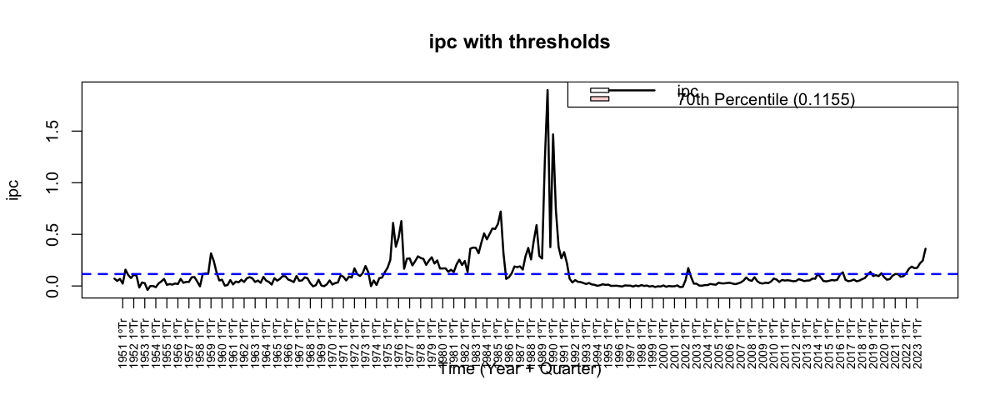

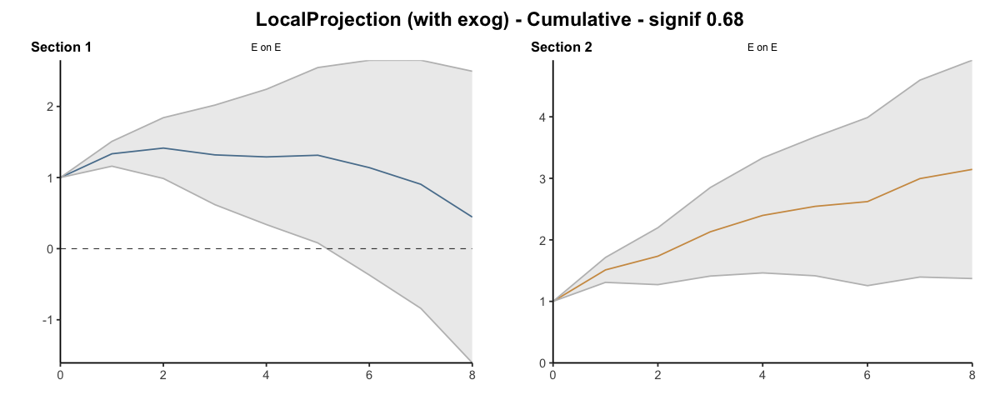

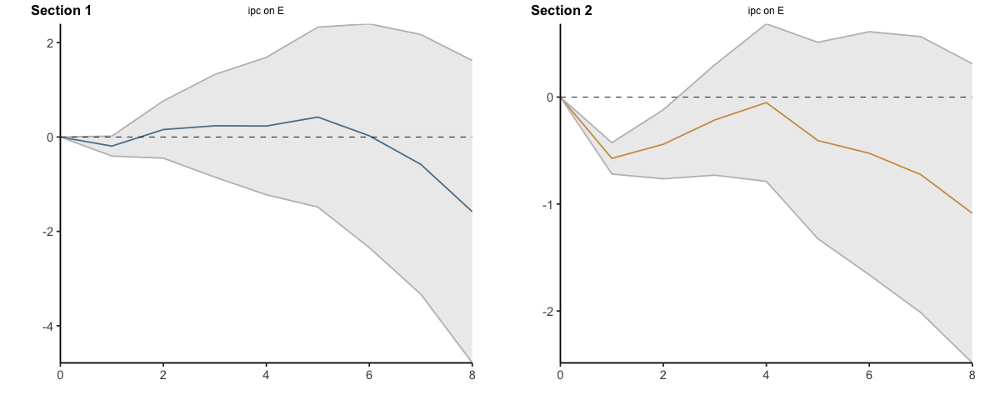

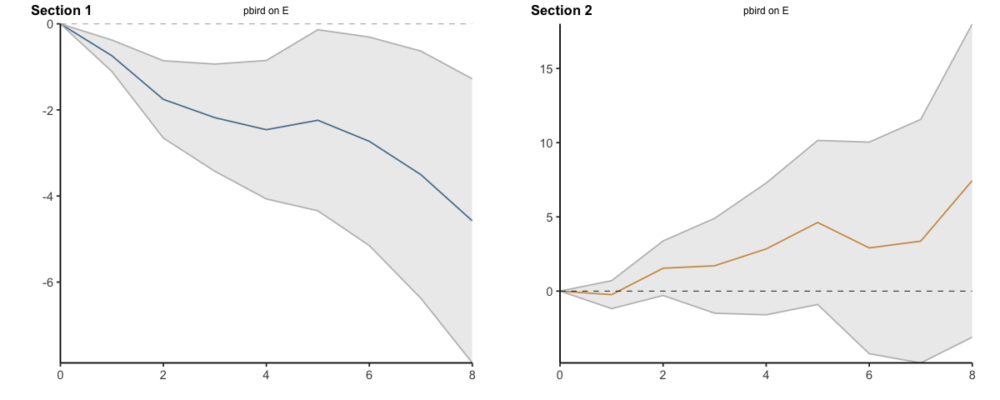

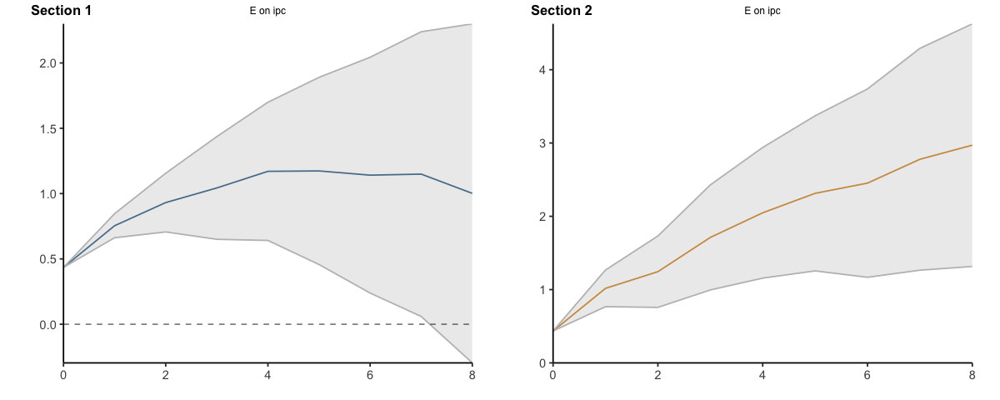

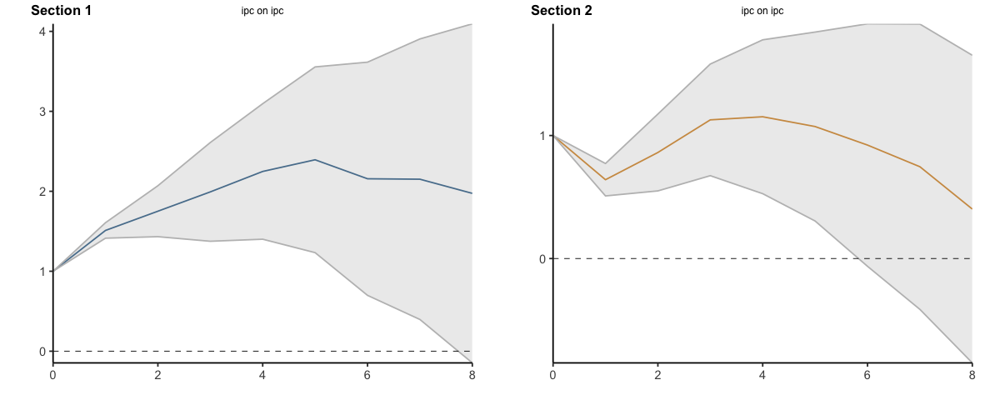

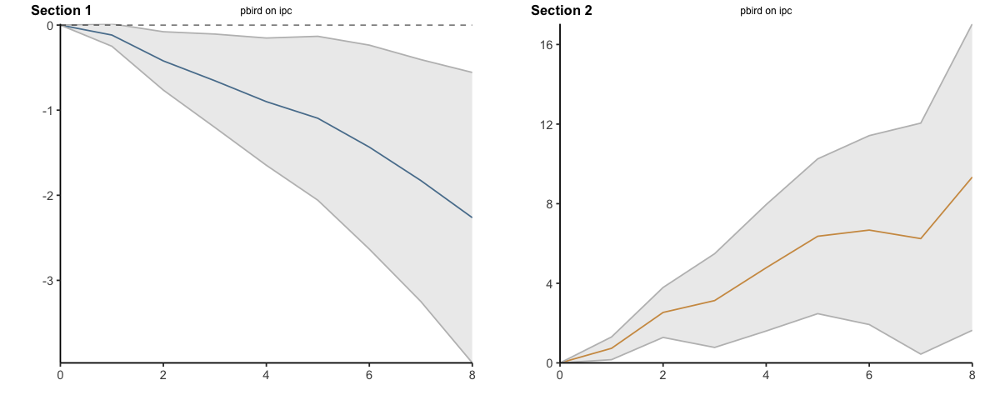

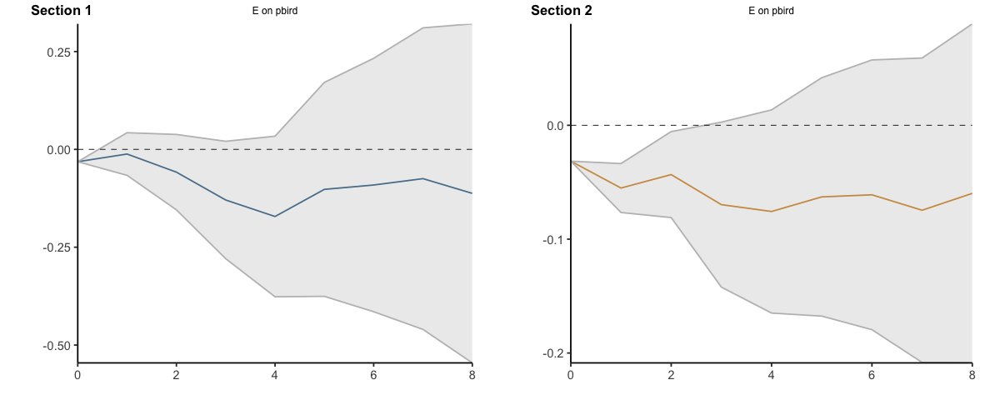

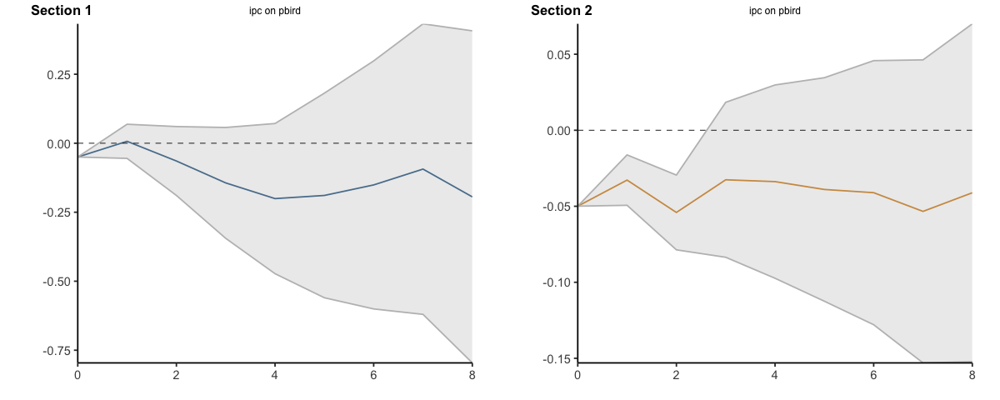

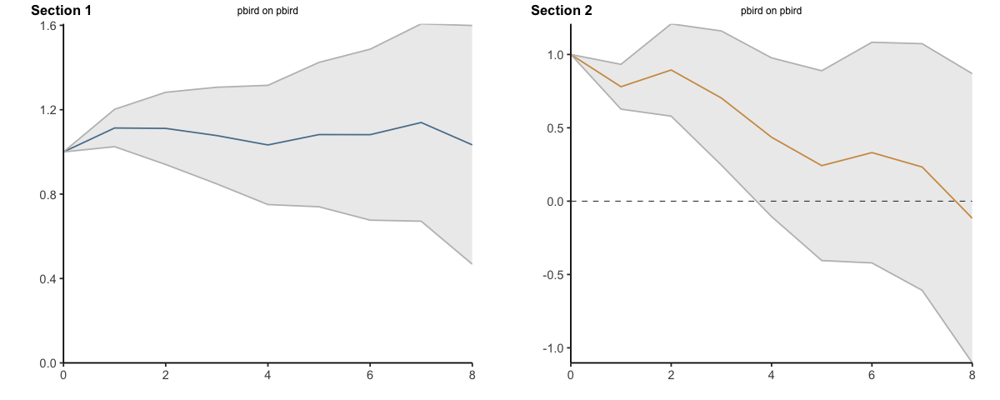

In [41]:
res <- run_lp_model(df_ERPT_Arg, endog=c("E", "ipc", "pbird"), exog=c("impp_usa"), fixed_lags = 5, horizons=8, signif = 0.68, threshold_var = 'ipc', upper_threshold=0.7, cumulative=TRUE)

#### Percentile 70 - 5 lags

Umbral: ipc > 0.1155 (percentil 70 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 206 | encima del umbral (dummy = 1) = 89 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 5 rezagos, exógenas: impp_usa, umbral: ipc > 0,115, 89 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4350         0.4350       1.0000
         1              0.7541         0.5653       1.3341
         2              0.9312         0.6584       1.4144
         3              1.0432         0.7910       1.3189
         4              1.1704         0.9071       1.2903
         5              1.1735         0.8932       1.3138
         6              1.1412         1.0016       1.1394
         7              1.1491         1.2692       0.9054
         8              1.0018         2.2549       0.4442
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4350             0.4350
                  0.3191             0.1303
                  0.1771             0.0931
 

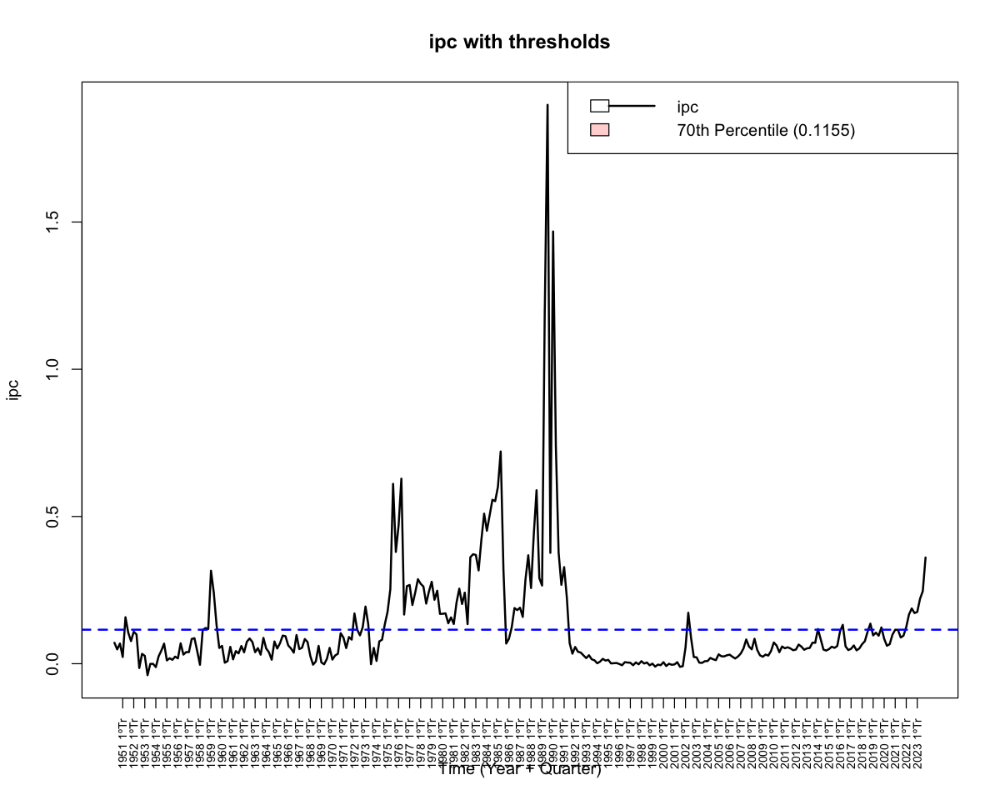

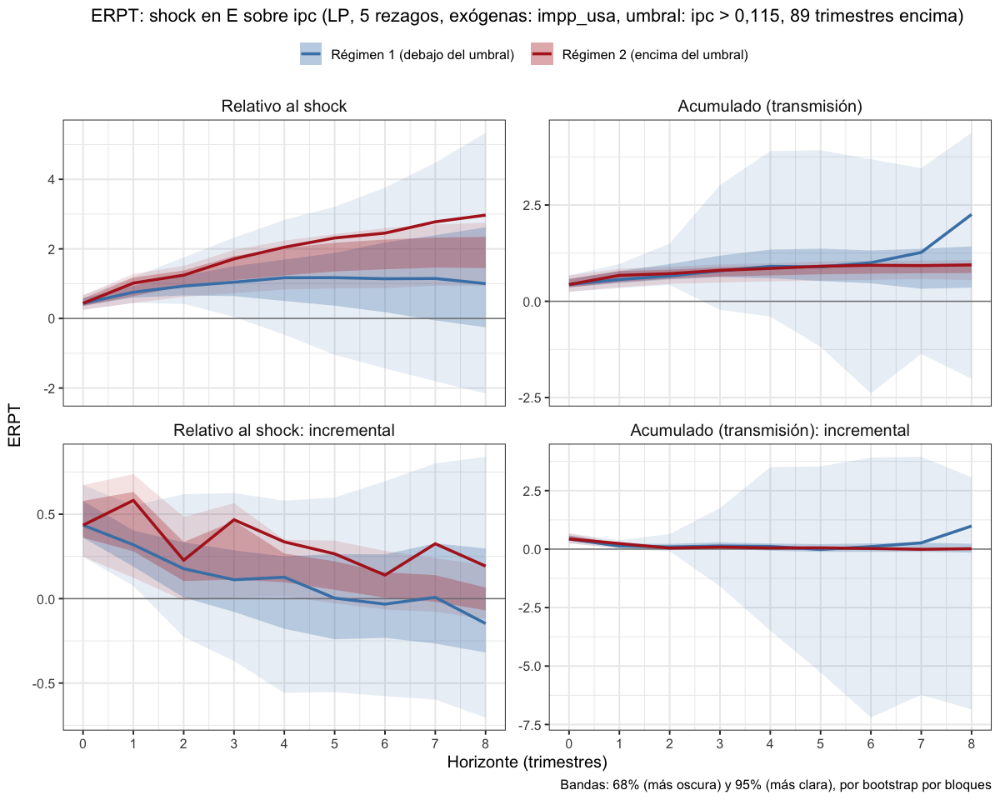

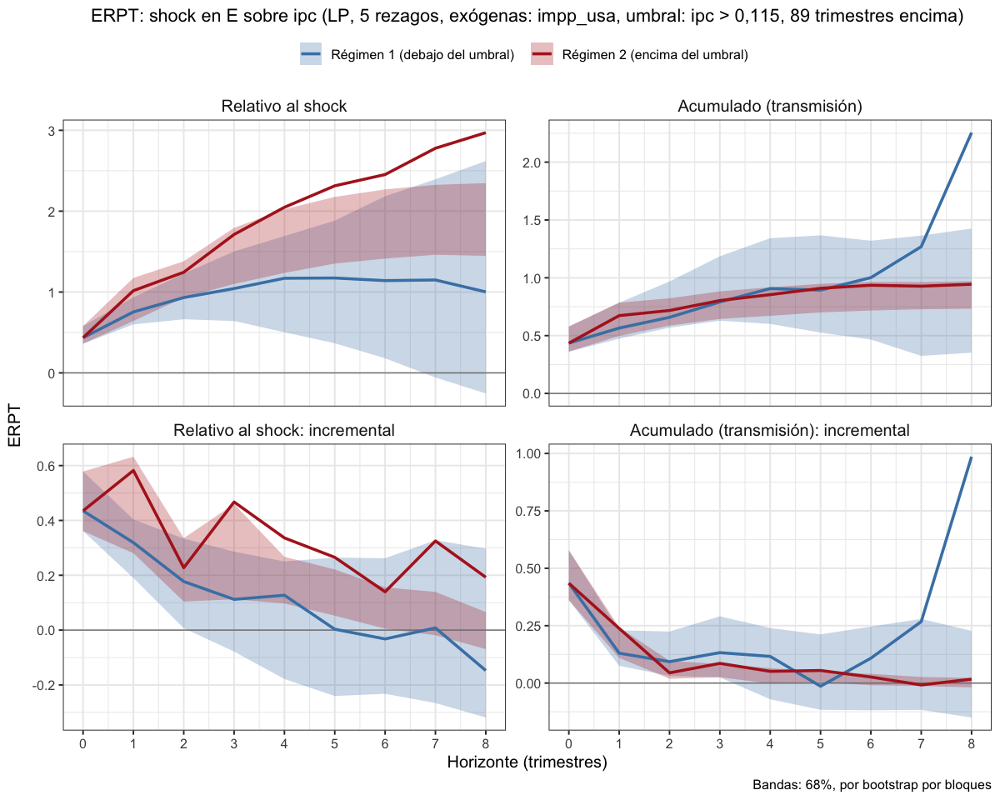

In [19]:
# 1 exógena y el resto endógenas con umbral en el percentil 70 del ipc, 5 rezagos
lp_erpt_exog_p5_u70 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                                fixed_lags = 5, horizons = 8, reps = 500,
                                threshold_var = "ipc", upper_threshold = 0.7)
saveRDS(lp_erpt_exog_p5_u70, "lp_erpt_exog_p5_u70.rds")
graficar_erpt_lp(lp_erpt_exog_p5_u70, archivo = "lp_erpt_exog_p5_u70")
graficar_erpt_lp(lp_erpt_exog_p5_u70, niveles = 0.68, archivo = "lp_erpt_exog_p5_u70_68")

#### Percentile 0.725423728813559 (12,5% inflación trimestral) - quedan 81 trimestres por encima del umbral

Umbral: ipc > 0.1265 (percentil 72.5 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 214 | encima del umbral (dummy = 1) = 81 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 5 rezagos, exógenas: impp_usa, umbral: ipc > 0,127, 81 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4350         0.4350       1.0000
         1              0.8198         0.6284       1.3046
         2              1.0466         0.7324       1.4289
         3              1.1688         0.8621       1.3557
         4              1.3015         0.9917       1.3123
         5              1.3217         0.9800       1.3487
         6              1.3249         1.0819       1.2246
         7              1.3507         1.3176       1.0251
         8              1.2515         1.8745       0.6676
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4350             0.4350
                  0.3848             0.1934
                  0.2268             0.1040
 

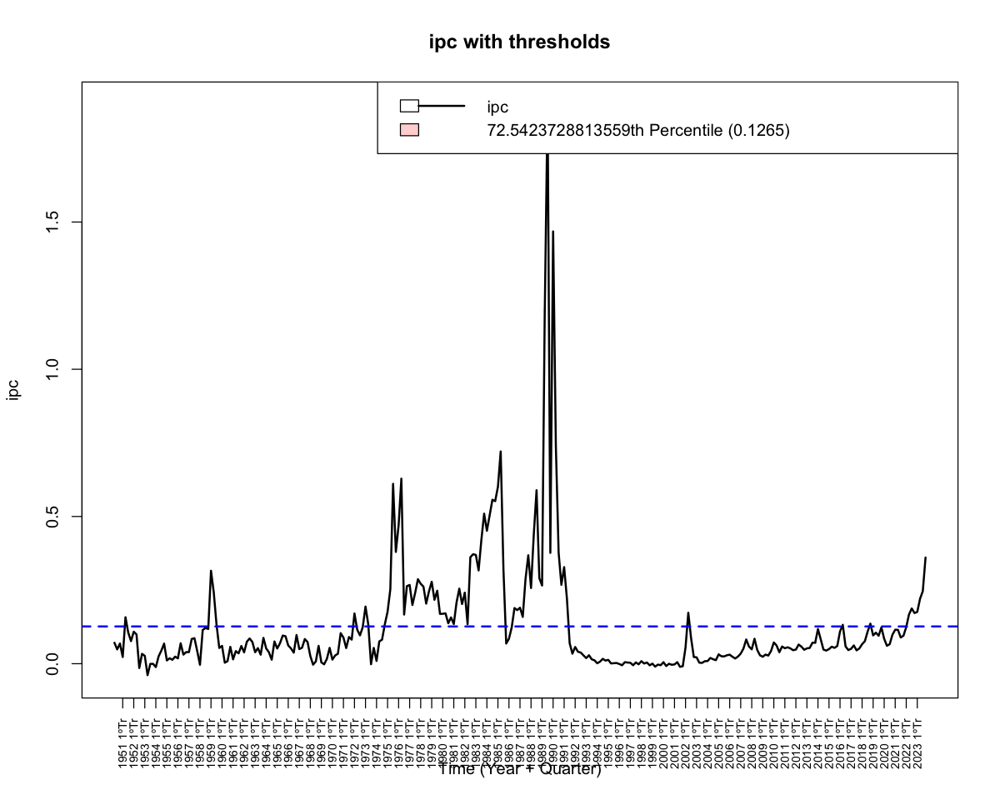

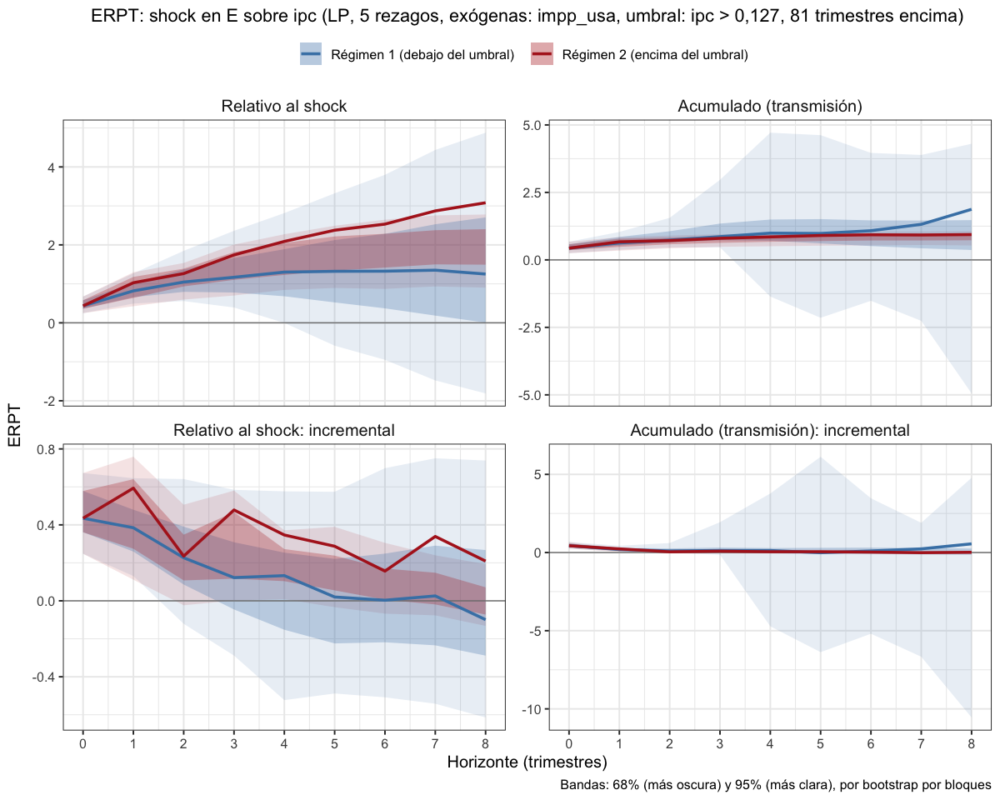

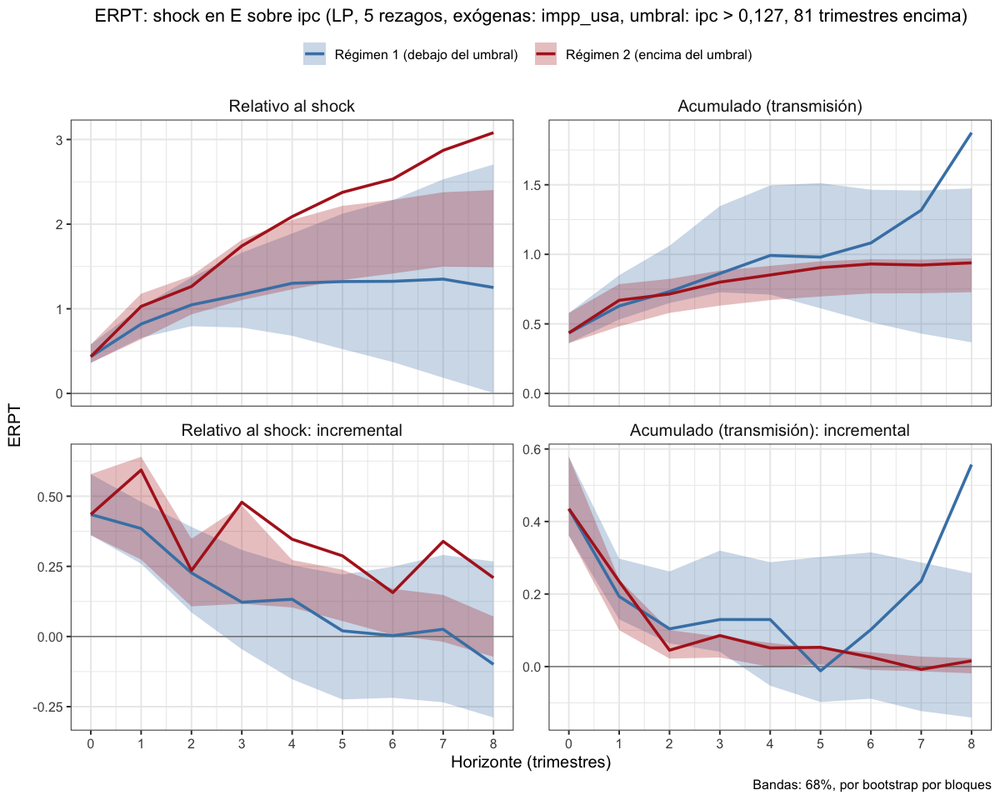

In [20]:
# 1 exógena y el resto endógenas con umbral en en 12,5% de inflación trimestral (umbral del TVAR), 5 rezagos
lp_erpt_exog_p5_tvar12.5 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"), 
                                     fixed_lags = 5, horizons = 8, reps = 500,
                                     threshold_var = "ipc", upper_threshold = 0.725423728813559)
saveRDS(lp_erpt_exog_p5_tvar12.5, "lp_erpt_exog_p5_tvar12.5.rds")
graficar_erpt_lp(lp_erpt_exog_p5_tvar12.5, archivo = "lp_erpt_exog_p5_tvar12.5")
graficar_erpt_lp(lp_erpt_exog_p5_tvar12.5, niveles = 0.68, archivo = "lp_erpt_exog_p5_tvar12.5_68")

#### Percentile 0.932203389830508 (37,6% de inflación trimestral) - quedan 20 trimestres por encima del umbral (son pocos)

Umbral: ipc > 0.3722 (percentil 93.2 )
Trimestres por régimen: debajo del umbral (dummy = 0) = 275 | encima del umbral (dummy = 1) = 20 


Bootstrap por bloques: 500 réplicas, bloques de 8 trimestres...



  |======================================================================| 100%


5 réplicas fallaron y se descartaron.



ERPT de un shock unitario en E sobre ipc ( LP, 5 rezagos, exógenas: impp_usa, umbral: ipc > 0,372, 20 trimestres encima )

Régimen 1 (debajo del umbral)
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4350         0.4350       1.0000
         1              0.8953         0.5777       1.5497
         2              1.3138         0.6998       1.8775
         3              1.6195         0.7789       2.0794
         4              2.0498         0.8717       2.3515
         5              2.3473         0.9154       2.5641
         6              2.7347         0.9323       2.9332
         7              3.3654         0.9514       3.5373
         8              3.8622         0.9605       4.0209
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4350             0.4350
                  0.4603             0.1427
                  0.4185             0.1220
                  0.3057             0.0791
                  0.4303             

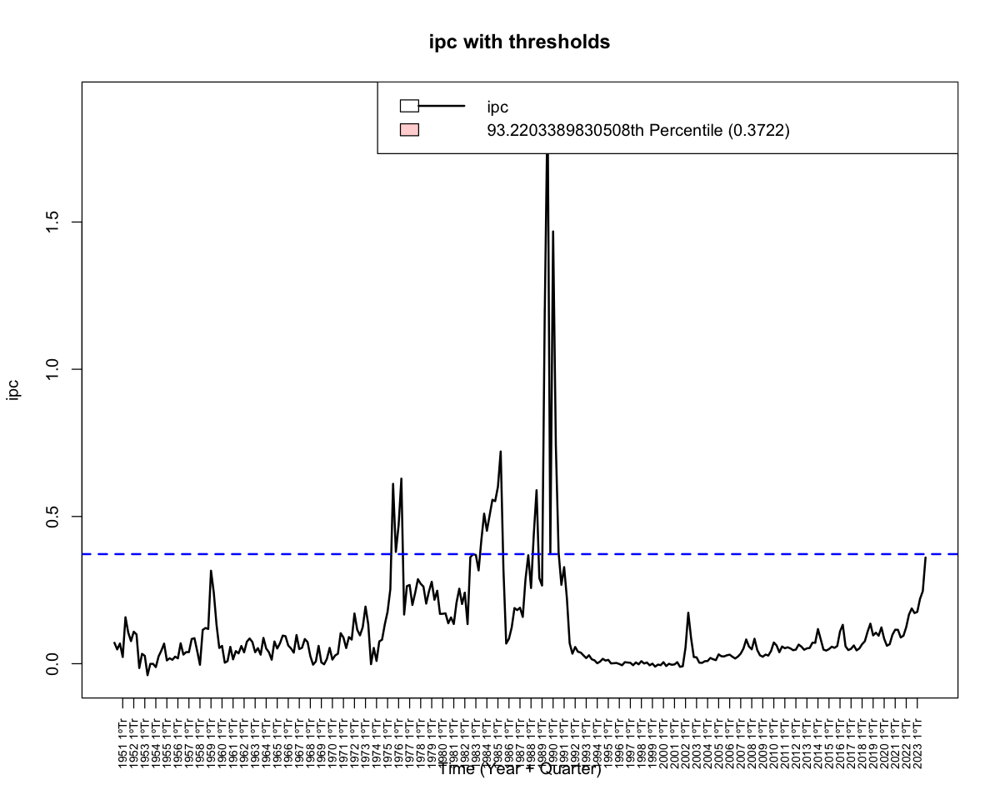

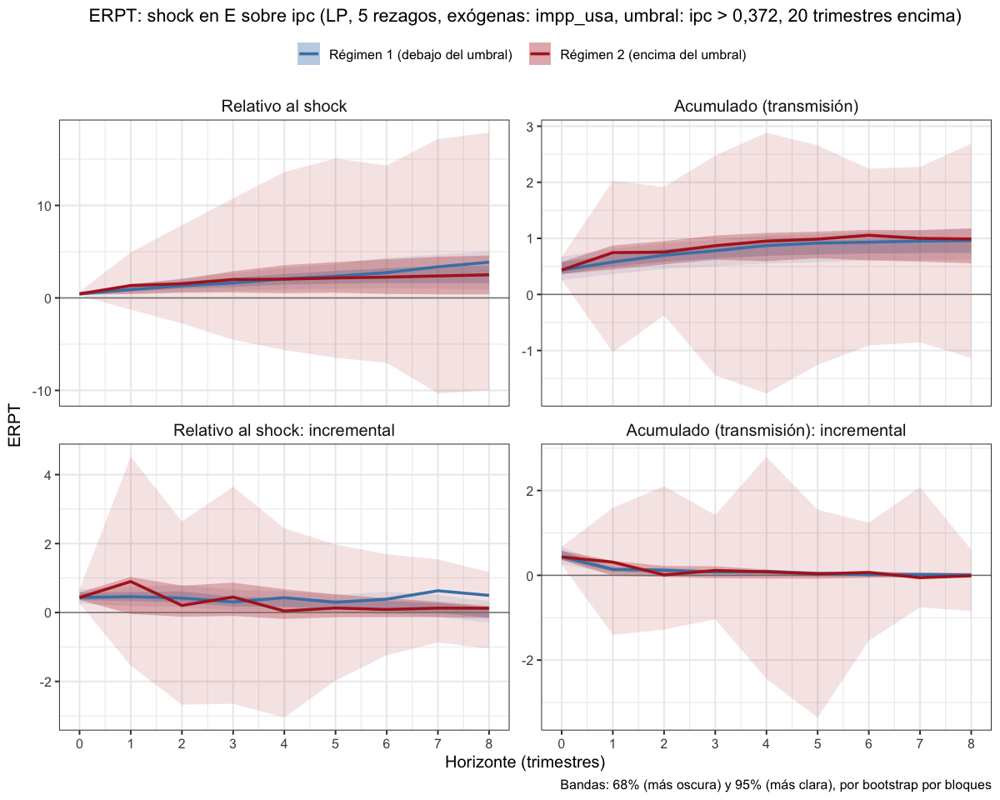

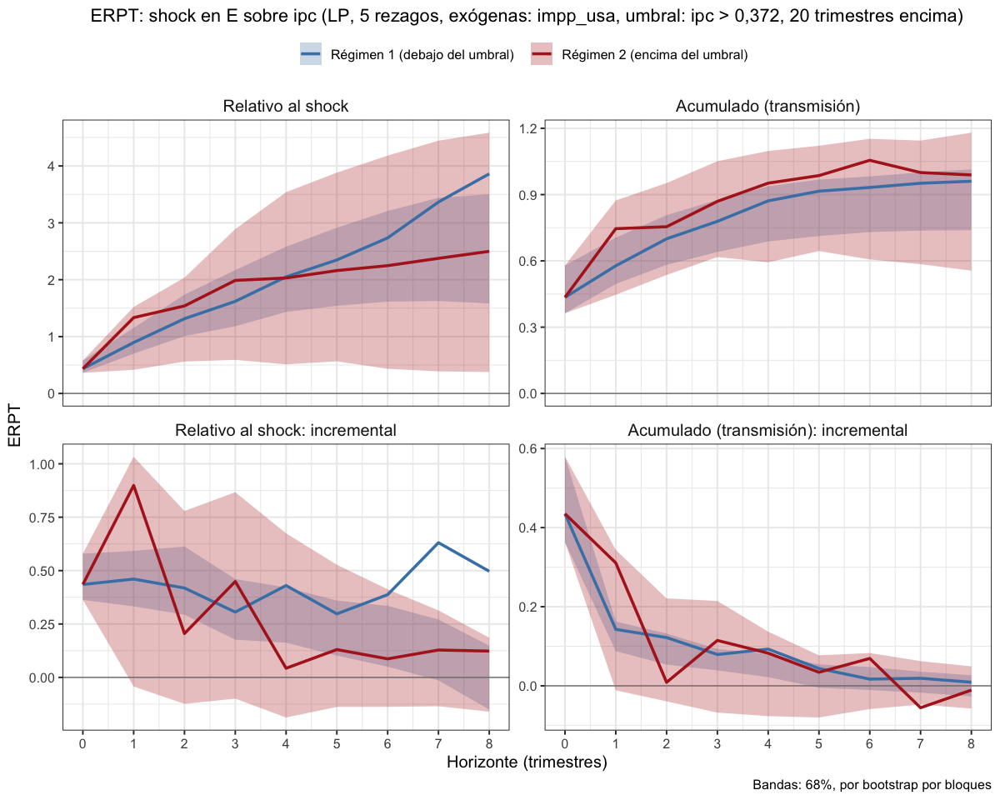

In [21]:
# 1 exógena y el resto endógenas con umbral en 37,6% de inflación trimestral (umbral del TVAR-indt), 5 rezagos
lp_erpt_exog_p5_tvar37.6 <- erpt_lp(df_ERPT_Arg, endog = c("E", "ipc", "pbird"), exog = c("impp_usa"),
                                    fixed_lags = 5, horizons = 8, reps = 500,
                                    threshold_var = "ipc", upper_threshold = 0.932203389830508)
saveRDS(lp_erpt_exog_p5_tvar37.6, "lp_erpt_exog_p5_tvar37.6.rds")
graficar_erpt_lp(lp_erpt_exog_p5_tvar37.6, archivo = "lp_erpt_exog_p5_tvar37.6")
graficar_erpt_lp(lp_erpt_exog_p5_tvar37.6, niveles = 0.68, archivo = "lp_erpt_exog_p5_tvar37.6_68")

### Celda de control

In [22]:
for (m in ls(pattern = "^lp_erpt_")) cat(m, ":", attr(get(m), "modelo"), "\n")

lp_erpt_endog_p2_tvar12.5 : LP, 2 rezagos, umbral: ipc > 0,127, 81 trimestres encima 
lp_erpt_endog_p2_tvar37.6 : LP, 2 rezagos, umbral: ipc > 0,372, 20 trimestres encima 
lp_erpt_endog_p2_u70 : LP, 2 rezagos, umbral: ipc > 0,115, 89 trimestres encima 
lp_erpt_endog_p2_u80 : LP, 2 rezagos, umbral: ipc > 0,183, 59 trimestres encima 
lp_erpt_endog_p3_tvar12.5 : LP, 3 rezagos, umbral: ipc > 0,127, 81 trimestres encima 
lp_erpt_endog_p3_tvar37.6 : LP, 3 rezagos, umbral: ipc > 0,372, 20 trimestres encima 
lp_erpt_endog_p3_u70 : LP, 3 rezagos, umbral: ipc > 0,115, 89 trimestres encima 
lp_erpt_exog_p2_tvar12.5 : LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,127, 81 trimestres encima 
lp_erpt_exog_p2_tvar37.6 : LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,372, 20 trimestres encima 
lp_erpt_exog_p2_u70 : LP, 2 rezagos, exógenas: impp_usa, umbral: ipc > 0,115, 89 trimestres encima 
lp_erpt_exog_p5_tvar12.5 : LP, 5 rezagos, exógenas: impp_usa, umbral: ipc > 0,127, 81 trimestres encima